# 01 · Data Sources, Ingestion & Data Lakes
*AI Foundations · Notebook 01 of 19*

Every machine-learning model sits at the end of a long pipe. Before anyone can train a
classifier or fine-tune a language model, somebody has to find the data, pull it out of the
systems that produce it (databases, web APIs, spreadsheets, event streams, sensors) and land it
somewhere safe, organized and easy to query. That "first mile" decides what your model can ever
learn: a brilliant architecture trained on duplicated, stale or mislabeled data still produces
garbage. In this notebook you will learn how professionals think about that first mile, and
you will build a small but realistic **data lake** that ingests papers, API records and partner
files every day, safely and repeatably.

**What you will learn**
- The data lifecycle: sources → ingestion → raw storage (the lake) → processing (ETL/ELT) →
  warehouse/lakehouse → dashboards and ML, and why "garbage in, garbage out" is an engineering problem.
- How to classify data sources by *origin* (databases, APIs, files, streams, cloud services, the web,
  logs, sensors) and by *structure* (structured, semi-structured, unstructured), plus schema-on-write
  versus schema-on-read.
- How batch, micro-batch and streaming ingestion trade off latency, throughput and cost (with a
  simulation), and the core reliability ideas: full vs incremental loads, watermarks, change data
  capture, at-least-once vs exactly-once delivery, idempotency, late data and backfills.
- How a data lake is organized: zones (raw/bronze → silver → gold), Hive-style partitions, CSV vs
  JSON Lines vs Parquet (measured, not just claimed), the small-files problem, catalogs and lineage,
  open table formats and the lakehouse.
- How to build a working mini lake: an arXiv Atom client, a robust paginated REST client against a
  local mock API (retries, `Retry-After`, cursors, watermarks), a checksum-based file drop zone with
  schema-drift detection, data-quality gates, curated Parquet with a catalog, SQL over the lake with DuckDB,
  and ready-to-use templates for media APIs (YouTube, Unsplash) with their quota and licensing rules.
- How to automate it: an orchestrator CLI with exit codes, per-day logs and lock files, cron syntax
  (with a cron matcher you write from scratch), Windows Task Scheduler, launchd, and time-zone traps.

**Prerequisites:** comfortable Python (functions, dictionaries, exceptions, a little object-oriented
code) and basic pandas. No prior data-engineering, HTTP or SQL knowledge is assumed. Everything is
explained when it first appears.      **Estimated time:** ~6 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.
Everything runs offline: whenever a real web service is unreachable, the notebook falls back to
local sample data and tells you so.

**Contents**
1. The big picture: from raw data to models
2. Where data comes from: sources by origin and by structure
3. Data ingestion: moving data reliably
4. Data lakes: storing raw data so it stays useful
5. Hands-on: building a mini data lake
6. Quiz
7. Summary and going further

## 0. Setup

The setup cell imports everything, fixes the random seed, sets one plotting style, and creates two
working folders inside `data/`:

- `data/01_playground/` for the small experiments of Sections 2–4, and
- `data/01_lake/` for the mini data lake we build in Section 5.

Both folders are **deleted and recreated** every time you run the setup cell, so the notebook always
starts from the same clean state. (That is our first reliability habit: a run should not depend on
leftovers from a previous run.)

In [1]:
# Setup: imports, reproducibility, plotting style and small helpers used throughout the notebook.
import base64, csv, difflib, hashlib, importlib, inspect, io, json, logging, math, os, random, re
import shutil, sqlite3, subprocess, sys, textwrap, threading, time, zlib
import email.utils, urllib.error, urllib.parse, urllib.request, urllib.robotparser
import xml.etree.ElementTree as ET
from datetime import date, datetime, timedelta, timezone
from html.parser import HTMLParser
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
from IPython.display import display

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
UTC = timezone.utc

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


duckdb = ensure("duckdb")          # an in-process SQL engine that can query Parquet files directly

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
PLAY = DATA_DIR / "01_playground"   # scratch space for Sections 2-4
LAKE = DATA_DIR / "01_lake"         # the mini data lake of Section 5
for folder in (PLAY, LAKE):
    shutil.rmtree(folder, ignore_errors=True)   # start from a clean slate on every run
    folder.mkdir(parents=True)


def run_check(name, test_fn):
    """Run test_fn(); print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def show_tree(root: Path, max_depth: int = 4, max_files: int = 4, prefix: str = "") -> None:
    """Print a directory tree (folders first), showing at most `max_files` files per folder."""
    root = Path(root)
    if not prefix:
        print(f"{root.as_posix()}/")
    entries = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    dirs = [p for p in entries if p.is_dir()]
    files = [p for p in entries if p.is_file()]
    shown = dirs + files[:max_files]
    for i, p in enumerate(shown):
        last = (i == len(shown) - 1) and len(files) <= max_files
        branch = "└── " if last else "├── "
        if p.is_dir():
            print(f"{prefix}{branch}{p.name}/")
            if max_depth > 1:
                show_tree(p, max_depth - 1, max_files, prefix + ("    " if last else "│   "))
        else:
            print(f"{prefix}{branch}{p.name}  ({p.stat().st_size:,} B)")
    if len(files) > max_files:
        print(f"{prefix}└── ... {len(files) - max_files} more file(s)")


print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"pyarrow {pa.__version__} | duckdb {duckdb.__version__} | matplotlib {matplotlib.__version__}")
print("Working folders:", PLAY.as_posix(), "and", LAKE.as_posix())

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | pyarrow 25.0.1 | duckdb 1.5.6 | matplotlib 3.11.2
Working folders: data/01_playground and data/01_lake


## 1. The big picture: from raw data to models

### 1.1 The data lifecycle

> **Intuition.** Think of a city's water system. Water starts in rivers, wells and rain
> (the **sources**). Pumps and pipes bring it to the city (**ingestion**). It is stored, untreated,
> in a big reservoir (the **data lake**): raw water is not drinkable, but keeping it means you can
> treat it in different ways later. A treatment plant cleans it (**processing**, ETL/ELT), water towers
> hold drinking water ready for use (the **warehouse** or **lakehouse**), and finally households open
> their taps (**consumers**: dashboards, analysts, machine-learning models). A problem anywhere upstream
> reaches every tap downstream.

Here is the same picture for data:

```text
 SOURCES                 INGESTION              DATA LAKE (object storage)        CONSUMERS
 -------                 ---------              --------------------------        ---------
 operational DBs --+                        +-----------------------------+
 web APIs ---------+     batch              | raw / bronze   as received  |      BI dashboards
 flat files -------+-->  micro-batch  --->  | silver         cleaned      | ---> data science
 event streams ----+     streaming          | gold           aggregated   |      ML training
 logs, sensors ----+     (CDC)              +--------------+--------------+      apps / APIs
                                                           | ETL / ELT
                                                           v
                                             warehouse / lakehouse tables
```

Each stage answers a different question, and each fails in its own way:

| Stage | Question it answers | Typical technology | What goes wrong if neglected |
|---|---|---|---|
| Sources | Where is the data born, and who owns it? | PostgreSQL, SaaS apps, REST APIs, Kafka, files | Nobody knows what exists or what a field means |
| Ingestion | How does data reach us, how often, how reliably? | Python jobs, Airbyte, Kafka Connect, Debezium | Missing or duplicated records, stale data |
| Raw storage (lake) | Where do we keep an untouched copy? | Amazon S3, Google Cloud Storage, Azure Data Lake Storage, MinIO | No way to reprocess after a bug is found |
| Processing (ETL/ELT) | How do we clean, join and reshape it? | SQL, dbt, Spark, pandas | Silent errors, inconsistent definitions |
| Warehouse / lakehouse | Where are curated tables queried? | BigQuery, Snowflake, Redshift, Delta Lake / Iceberg tables | Slow queries, two dashboards disagreeing |
| Consumption | Who uses the data, for what? | dashboards, notebooks, training jobs | Decisions and models built on wrong data |

A few definitions we will refine throughout the notebook:

- A **data source** is any system that creates, stores or emits data that you want to use: a database,
  an API, a folder of files, a stream of events, a sensor.
- **Data ingestion** is the process of *moving* data from sources into a central storage or processing
  system, ideally with little or no transformation, on a schedule or continuously.
- A **data lake** is a central repository that stores large volumes of data **in its original (raw)
  format**, usually on cheap object storage, for many future uses.
- **ETL** (Extract–Transform–Load) and **ELT** (Extract–Load–Transform) are the two classic orders in
  which data is extracted, cleaned/reshaped and loaded, and Section 3.1 compares them.
- A **data warehouse** stores cleaned, structured, query-optimized tables for analytics. A
  **lakehouse** adds warehouse-like guarantees directly on top of lake files (Section 4.7).

> **Key idea.** Machine-learning work is downstream work. The questions "what data do we have, how
> fresh is it, can we trust it, can we reproduce last month's training set?" are answered (or not)
> by the ingestion and storage layers long before any model is trained.

### 1.2 Garbage in, garbage out: a 30-second experiment

"Garbage in, garbage out" is an old computing proverb: a program cannot produce correct answers from
incorrect input. Let us see how a *pipeline* bug, not a modeling bug, ruins a model.

**Setup.** Three weather stations (A, B, C) report hourly temperatures for 60 summer days. A utility
wants to predict electricity demand (in megawatts, MW) from temperature, and the true relationship is
linear:

$$
\text{demand} = 900 + 25 \cdot T_{\text{°C}} + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 40^2)
$$

so every extra degree Celsius costs 25 MW (air conditioners). **The bug:** after a firmware update on
day 30, station B silently starts reporting **Fahrenheit** ($T_{\text{°F}} = \tfrac{9}{5} T_{\text{°C}} + 32$).
The ingestion job copies the numbers as they are. We fit the same least-squares line to the clean and
to the corrupted data, and evaluate both on a clean test set.

In [2]:
# Simulate the clean data: 3 stations x 60 days x 24 hours.
n_days, stations = 60, ["A", "B", "C"]
hours = np.arange(n_days * 24)
frames = []
for i, st in enumerate(stations):
    temp_c = (27 + 6 * np.sin(2 * np.pi * ((hours % 24) - 9) / 24)    # daily cycle
              + 1.5 * i - 1.5                                          # small station offset
              + rng.normal(0, 2.0, size=hours.size))                   # weather noise
    demand = 900 + 25 * temp_c + rng.normal(0, 40, size=hours.size)
    frames.append(pd.DataFrame({"station": st, "day": hours // 24, "temp": temp_c, "demand": demand}))
clean = pd.concat(frames, ignore_index=True)

# The ingestion bug: station B switches to Fahrenheit from day 30 on.
corrupted = clean.copy()
bad = (corrupted["station"] == "B") & (corrupted["day"] >= 30)
corrupted.loc[bad, "temp"] = corrupted.loc[bad, "temp"] * 9 / 5 + 32

# A clean, independent test set generated from the true relationship.
t_test = rng.uniform(18, 36, size=2000)
y_test = 900 + 25 * t_test + rng.normal(0, 40, size=t_test.size)


def fit_line(x, y):
    """Least-squares line y = a + b x; returns (a, b, R^2 on the fitting data)."""
    b, a = np.polyfit(x, y, deg=1)
    resid = y - (a + b * x)
    r2 = 1 - resid.var() / y.var()
    return a, b, r2


rows = []
for name, df in [("clean", clean), ("corrupted", corrupted)]:
    a, b, r2 = fit_line(df["temp"].to_numpy(), df["demand"].to_numpy())
    mae = np.abs(y_test - (a + b * t_test)).mean()
    rows.append({"training data": name, "intercept": a, "slope (MW per degree)": b,
                 "R^2 (train)": r2, "MAE on clean test (MW)": mae})
results = pd.DataFrame(rows).round(3)
display(results)
print(f"Rows affected by the bug: {bad.sum()} of {len(corrupted)} ({bad.mean():.1%})")

,training data,intercept,slope (MW per degree),R^2 (train),MAE on clean test (MW)
0,clean,899.496,24.977,0.903,31.386
1,corrupted,1517.835,1.581,0.065,109.770


Rows affected by the bug: 720 of 4320 (16.7%)


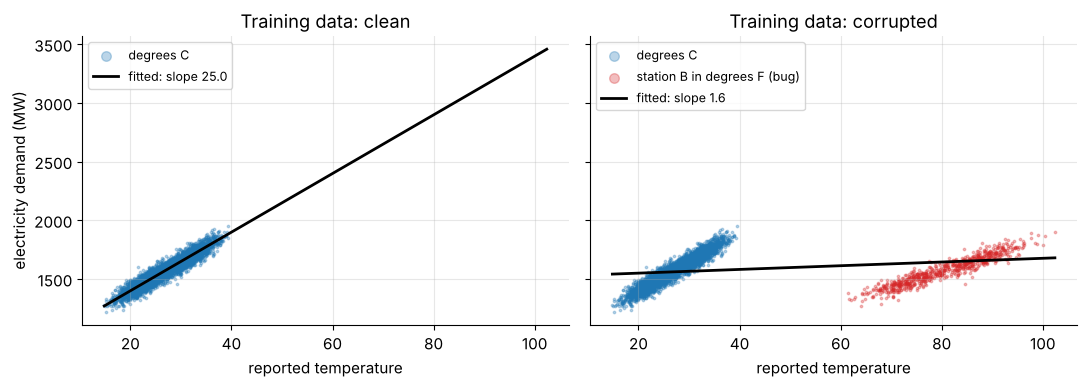

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
xs = np.linspace(clean["temp"].min(), corrupted["temp"].max(), 50)
for ax, (name, df) in zip(axes, [("clean", clean), ("corrupted", corrupted)]):
    is_bad = bad if name == "corrupted" else np.zeros(len(df), dtype=bool)
    ax.scatter(df.loc[~is_bad, "temp"], df.loc[~is_bad, "demand"], s=3, alpha=0.3, label="degrees C")
    if is_bad.any():
        ax.scatter(df.loc[is_bad, "temp"], df.loc[is_bad, "demand"], s=3, alpha=0.3, color="C3",
                   label="station B in degrees F (bug)")
    a, b, _ = fit_line(df["temp"].to_numpy(), df["demand"].to_numpy())
    ax.plot(xs, a + b * xs, color="black", lw=2, label=f"fitted: slope {b:.1f}")
    ax.set_title(f"Training data: {name}")
    ax.set_xlabel("reported temperature")
    ax.legend(loc="upper left", fontsize=9, markerscale=4)
axes[0].set_ylabel("electricity demand (MW)")
plt.tight_layout()
plt.show()

Only one sixth of the rows were affected, yet the fitted slope collapses from about 25 MW per degree
to about 1.6, $R^2$ falls from 0.90 to below 0.1, and the mean absolute error on clean test data
more than triples (from about 31 MW to about 110 MW). The model did exactly what it was told. The
*pipeline* lied to it. No amount of hyper-parameter tuning fixes this.

The cheapest fix lives at **ingestion time**. A one-line plausibility check (summer temperatures in
°C should lie between −40 and 50) flags the bad rows immediately:

In [4]:
flagged = ~corrupted["temp"].between(-40, 50)
print(f"Range check flags {flagged.sum()} rows; {(flagged & bad).sum()} of them are the "
      f"{bad.sum()} Fahrenheit rows, false alarms: {(flagged & ~bad).sum()}")
print(corrupted[flagged].groupby(["station"]).agg(first_bad_day=("day", "min"), rows=("day", "size")))

Range check flags 720 rows; 720 of them are the 720 Fahrenheit rows, false alarms: 0
         first_bad_day  rows
station                     
B                   30   720


The check flags essentially all of the corrupted rows, tells you *which source* and *since when*,
and produces zero false alarms. Section 5.5 turns this idea into a small data-quality framework that
runs on every ingestion.

> **Common pitfall.** "The model is bad, let's try a bigger model." Before touching the model, check
> the data path: duplicates, unit or time-zone changes, schema changes, stale snapshots, and leakage.

<details>
<summary><b>Quick check:</b> name two ingestion-time safeguards that would have caught this bug, and one that would have <i>prevented</i> it.</summary>

Caught: (1) a range/plausibility check on temperature, and (2) a per-source distribution monitor that
compares today's mean/quantiles for station B with its history (a jump of ~50 degrees is obvious).
Prevented: a **data contract** in which each source declares its units in the schema (for example a
field `temp_c` or explicit unit metadata) and the ingestion job rejects payloads that violate it.
</details>

### 1.3 Vocabulary you will meet again and again

| Term | Meaning in this notebook |
|---|---|
| **pipeline** | a chain of steps that moves and transforms data from sources to consumers |
| **job** / **run** | a job is a unit of work (e.g., "ingest arXiv"). A run is one execution of it |
| **logical date** | the time period a run is responsible for (e.g., "papers submitted on March 1"), which is *not* the wall-clock time at which it happens to execute |
| **record** / **event** | one row or one message. An event is a record describing something that happened at a time |
| **schema** | the names and types of the fields in a record |
| **sink** | the place data is written to (a folder, a table, a topic) |
| **state** | what a pipeline remembers between runs (last watermark, IDs already seen, checksums of files) |
| **idempotent** | running it twice has the same effect as running it once (Section 3.6) |
| **watermark** | in batch: the highest "updated at" value already ingested. In streaming: a moving estimate of event-time progress (Sections 3.4, 3.7) |
| **backfill** | re-running a pipeline for past logical dates, e.g. after fixing a bug (Section 3.7) |
| **partition** | a slice of a dataset stored separately (e.g., one folder per day) so queries can skip the rest |

## 2. Where data comes from: sources by origin and by structure

Data sources can be classified in two complementary ways:

- **By origin:** where the data is produced and *how it is delivered* to you: a database you can
  query, an API you can call, files someone drops in a folder, a stream of events, a sensor. The
  origin decides **how you ingest**.
- **By structure:** how organized the data is: neat tables, nested JSON, free text, images. The
  structure decides **how you store and analyze** it.

Every source carries both labels at once. A Kafka topic of JSON click events is *streaming* by origin
and *semi-structured* by structure. A folder of scanned invoices is *files* by origin and
*unstructured* by structure. Sections 2.1–2.8 walk through the origins, Section 2.9 the structures.

### 2.1 Operational databases (OLTP)

> **Intuition.** Operational databases are the cash registers of a company: every sale, sign-up,
> refund or stock movement is rung up there, one small transaction at a time, and it must be fast
> and exactly right.

**OLTP** (Online Transaction Processing) systems are the databases behind day-to-day operations:

- **CRM** (customer relationship management): customers, contacts, sales opportunities.
- **ERP** (enterprise resource planning): orders, inventory, invoices, accounting.
- **HRM** (human resource management): employees, payroll, time off.

They usually run on relational engines such as PostgreSQL, MySQL, SQL Server or Oracle (some apps use
NoSQL stores such as MongoDB or DynamoDB). They are optimized for **many small, concurrent reads and
writes** that must be **ACID**: *Atomic* (all of a transaction or nothing), *Consistent* (rules such as
foreign keys always hold), *Isolated* (concurrent transactions don't see each other's half-done work)
and *Durable* (once committed, it survives a crash).

To keep writes small and correct, OLTP schemas are **normalized**: each fact is stored exactly once and
tables reference each other through keys. Instead of copying a customer's name and city onto every
order row, the order stores only `customer_id`. If the customer moves, one row changes. (In a
denormalized design the city would be repeated on thousands of rows, and forgetting to update one of them
creates an *update anomaly*: two different "truths" in the same database.)

The price of normalization is paid by analysts: answering "revenue per month per product category"
needs joins across four tables and a scan of every order line. Let us measure that on a small shop
database (40,000 orders) built in SQLite, a full SQL engine that ships with Python.

In [5]:
def build_shop_db(n_customers=2_000, n_products=300, n_orders=40_000, seed=SEED):
    """Create a small normalized shop database (in memory) with random but reproducible content."""
    r = np.random.default_rng(seed)
    con = sqlite3.connect(":memory:")
    con.executescript("""
        CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT NOT NULL, city TEXT NOT NULL);
        CREATE TABLE products  (product_id INTEGER PRIMARY KEY, name TEXT NOT NULL,
                                category TEXT NOT NULL, price REAL NOT NULL CHECK (price > 0));
        CREATE TABLE orders    (order_id INTEGER PRIMARY KEY,
                                customer_id INTEGER NOT NULL REFERENCES customers(customer_id),
                                ordered_at TEXT NOT NULL);
        CREATE TABLE order_items (order_id INTEGER NOT NULL REFERENCES orders(order_id),
                                  line_no INTEGER NOT NULL,
                                  product_id INTEGER NOT NULL REFERENCES products(product_id),
                                  qty INTEGER NOT NULL CHECK (qty > 0),
                                  PRIMARY KEY (order_id, line_no));
    """)
    cities = ["Toronto", "Montreal", "Vancouver", "Calgary", "Ottawa", "Halifax"]
    categories = ["audio", "books", "garden", "kitchen", "sports", "toys"]
    con.executemany("INSERT INTO customers VALUES (?, ?, ?)",
                    [(i, f"Customer {i:04d}", cities[r.integers(len(cities))]) for i in range(1, n_customers + 1)])
    con.executemany("INSERT INTO products VALUES (?, ?, ?, ?)",
                    [(i, f"Product {i:03d}", categories[r.integers(len(categories))], round(float(r.uniform(3, 250)), 2))
                     for i in range(1, n_products + 1)])
    start = datetime(2025, 1, 1, tzinfo=UTC)
    seconds = r.integers(0, 365 * 24 * 3600, size=n_orders)
    con.executemany("INSERT INTO orders VALUES (?, ?, ?)",
                    [(i + 1, int(r.integers(1, n_customers + 1)), (start + timedelta(seconds=int(s))).isoformat())
                     for i, s in enumerate(seconds)])
    items = [(o, line, int(r.integers(1, n_products + 1)), int(r.integers(1, 4)))
             for o in range(1, n_orders + 1) for line in range(1, int(r.integers(1, 6)) + 1)]
    con.executemany("INSERT INTO order_items VALUES (?, ?, ?, ?)", items)
    con.commit()
    return con


shop = build_shop_db()
for table in ["customers", "products", "orders", "order_items"]:
    print(f"{table:12s} {shop.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0]:>8,} rows")

customers       2,000 rows
products          300 rows
orders         40,000 rows
order_items   119,746 rows


Now two queries. The first is a typical **transactional** lookup (what the order-status page of the
shop runs thousands of times per minute). The second is a typical **analytical** question.
`EXPLAIN QUERY PLAN` asks SQLite *how* it will execute each query: `SEARCH ... USING ... PRIMARY KEY`
means "jump straight to the rows via an index", while `SCAN` means "read the whole table".

In [6]:
OLTP_SQL = """
SELECT o.order_id, o.ordered_at, c.name AS customer, p.name AS product, i.qty, p.price
FROM orders o
JOIN customers c   ON c.customer_id = o.customer_id
JOIN order_items i ON i.order_id = o.order_id
JOIN products p    ON p.product_id = i.product_id
WHERE o.order_id = 12345
"""
OLAP_SQL = """
SELECT substr(o.ordered_at, 1, 7) AS month, p.category, ROUND(SUM(i.qty * p.price), 2) AS revenue
FROM order_items i
JOIN orders o   ON o.order_id = i.order_id
JOIN products p ON p.product_id = i.product_id
GROUP BY month, p.category
ORDER BY month, p.category
"""


def time_query(con, sql, repeat):
    """Best-of-`repeat` wall time of a query, in milliseconds."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql).fetchall()
        best = min(best, time.perf_counter() - t0)
    return best * 1000


for label, sql, repeat in [("transactional (one order)", OLTP_SQL, 200), ("analytical (all orders)", OLAP_SQL, 3)]:
    plan = [row[-1] for row in shop.execute("EXPLAIN QUERY PLAN " + sql)]
    print(f"{label}: best of {repeat} runs = {time_query(shop, sql, repeat):.3f} ms")
    for step in plan:
        print("    plan:", step)

display(pd.read_sql_query(OLTP_SQL, shop))
display(pd.read_sql_query(OLAP_SQL, shop).head(4))

transactional (one order): best of 200 runs = 0.006 ms
    plan: SEARCH o USING INTEGER PRIMARY KEY (rowid=?)
    plan: SEARCH c USING INTEGER PRIMARY KEY (rowid=?)
    plan: SEARCH i USING INDEX sqlite_autoindex_order_items_1 (order_id=?)
    plan: SEARCH p USING INTEGER PRIMARY KEY (rowid=?)


analytical (all orders): best of 3 runs = 389.365 ms
    plan: SCAN i
    plan: SEARCH o USING INTEGER PRIMARY KEY (rowid=?)
    plan: SEARCH p USING INTEGER PRIMARY KEY (rowid=?)
    plan: USE TEMP B-TREE FOR GROUP BY


,order_id,ordered_at,customer,product,qty,price
0,12345,2025-09-14T05:11:41+00:00,Customer 1341,Product 191,1,99.70
1,12345,2025-09-14T05:11:41+00:00,Customer 1341,Product 153,3,17.69
2,12345,2025-09-14T05:11:41+00:00,Customer 1341,Product 087,3,249.86


,month,category,revenue
0,2025-01,audio,356826.12
1,2025-01,books,598362.46
2,2025-01,garden,438406.73
3,2025-01,kitchen,404967.45


The transactional query touches a handful of rows through primary-key lookups and finishes in
microseconds. The analytical query must scan all ~120,000 order lines and join them, which takes
orders of magnitude longer, and this is a *tiny* database. On a real system with a billion order
lines, the analytical query would hog CPU, memory and disk for minutes. That is why companies avoid
running heavy analytics directly on production OLTP databases:

1. **Resource contention.** A big scan competes with the checkout page for CPU, memory, disk I/O and
   cache, and customers notice.
2. **Locks and long transactions.** Long reads can block writers or keep old row versions alive,
   slowing the whole database down.
3. **Wrong shape.** Row-oriented storage plus a normalized schema means many joins and full scans for
   every aggregate. Analytical stores use **columnar** storage and denormalized "star" schemas instead.
4. **No history.** OLTP rows are updated in place: yesterday's price or a customer's old address is
   simply gone. Analytics and ML often need the history.
5. **Safety.** Giving many analysts access to the production database is a security and stability risk.

The standard answer is to **copy the data out**: extract it on a schedule (ETL/ELT) or continuously
with change data capture (CDC, Section 3.5) into a data lake or warehouse, or at least query a
**read replica**, a continuously updated copy dedicated to reading.

| | OLTP (operational) | OLAP (analytical) |
|---|---|---|
| Purpose | run the business | understand the business |
| Typical query | read/write a few rows by key | aggregate millions of rows |
| Latency target | milliseconds | seconds to minutes |
| Schema | normalized (many tables) | denormalized star/snowflake schemas, wide tables |
| Storage layout | row-oriented | column-oriented |
| Data | current state | history (append-only facts, snapshots) |
| Examples | PostgreSQL, MySQL, SQL Server, Oracle | BigQuery, Snowflake, Redshift, ClickHouse, DuckDB |

<details>
<summary><b>Quick check:</b> a teammate wants to point the company dashboard straight at the production orders database "because it is always up to date". Name two risks and one alternative.</summary>

Risks: heavy dashboard queries slow down (or lock) the live shop, the dashboard cannot show history
that OLTP overwrites, and analysts get access to a critical system. Alternatives: replicate the data
into a warehouse or lake with incremental loads or CDC (minutes of latency is usually fine for a
dashboard), or at minimum use a read replica.
</details>

### 2.2 APIs: asking another system for data

> **Intuition.** An API (Application Programming Interface) is like a restaurant waiter. You never walk
> into the kitchen (the provider's database). You order from a menu (the **endpoints**), the waiter
> brings back a dish (usually **JSON**), and the restaurant decides who may order (**authentication**),
> how fast you may order (**rate limits**) and how much you may order per day (**quotas**).

Most data APIs are **REST** APIs over HTTP: resources are named by URLs, you act on them with HTTP
methods (`GET` reads, `POST` creates, `PUT`/`PATCH` updates, `DELETE` removes), every request is
self-contained (stateless), and responses carry a **status code**. A single exchange looks like this:

```text
GET /v1/products?updated_since=2026-03-01T00%3A00%3A00Z&limit=50 HTTP/1.1    <- method, path, query string
Host: api.example.com
X-API-Key: ********                                                           <- credentials in a header
Accept: application/json

HTTP/1.1 200 OK                                                               <- status code
Content-Type: application/json
X-RateLimit-Remaining: 41                                                     <- how many calls are left

{"data": [{"id": "P0001", "price": 19.99, ...}, ...], "next_cursor": "eyJ0IjoiMjAyNi0w..."}
```

The status code tells your client what to do next, and in particular **whether a retry can help**:

| Code | Meaning | Retry? |
|---|---|---|
| 200 OK, 201 Created, 204 No Content | success | no need |
| 304 Not Modified | your cached copy is still valid (after a conditional request with `ETag`/`If-None-Match`) | no, reuse the cache |
| 400 Bad Request, 422 Unprocessable | your request is malformed | **no**: fix the request |
| 401 Unauthorized, 403 Forbidden | missing/invalid credentials, or not allowed | **no**: fix the credentials or permissions |
| 404 Not Found | the resource does not exist | no |
| 408 Request Timeout | the server gave up waiting for you | yes |
| 429 Too Many Requests | you hit a rate limit | yes, **after** the delay in the `Retry-After` header |
| 500, 502, 503, 504 | server-side or gateway trouble, often transient | yes, with backoff |

**Authentication.** Common schemes are an **API key** (a long random string sent in a header such as
`X-API-Key`, or sometimes in the URL), and **OAuth 2.0 bearer tokens** (`Authorization: Bearer <token>`)
that expire and must be refreshed. Keys are passwords: keep them out of your code and notebooks, read
them from **environment variables** or a `.env` file that is listed in `.gitignore`, and never print
them in logs. Prefer headers over URL parameters, because URLs end up in server logs and browser history.

In [7]:
# Building a request safely: URL-encode parameters, read secrets from the environment, mask them in logs.
base_url = "https://api.example.com/v1/products"
params = {"updated_since": "2026-03-01T00:00:00Z", "limit": 50, "category": "books & media"}
url = base_url + "?" + urllib.parse.urlencode(params)
print("URL:", url)        # note how ':' '&' and spaces are percent-encoded

api_key = os.environ.get("EXAMPLE_API_KEY", "demo_0123456789abcdef")   # a real key would come from the environment


def mask(secret: str) -> str:
    """Show only the first 4 and last 2 characters of a secret."""
    return secret[:4] + "*" * max(len(secret) - 6, 0) + secret[-2:]


headers = {"X-API-Key": api_key, "Accept": "application/json",
           "User-Agent": "ai-foundations-demo/1.0 (contact: you@example.com)"}
print("headers as they should appear in a log:", {k: mask(v) if k == "X-API-Key" else v for k, v in headers.items()})

URL: https://api.example.com/v1/products?updated_since=2026-03-01T00%3A00%3A00Z&limit=50&category=books+%26+media
headers as they should appear in a log: {'X-API-Key': 'demo***************ef', 'Accept': 'application/json', 'User-Agent': 'ai-foundations-demo/1.0 (contact: you@example.com)'}


**Pagination.** APIs return large result sets in pages. There are three common styles:

| Style | Request looks like | Pros | Cons |
|---|---|---|---|
| Offset / limit | `?offset=200&limit=100` | simple, can jump to any page | slow for deep pages, **duplicates or gaps if data changes while you page** |
| Page number | `?page=3&per_page=30` | simple, human-friendly | same problems as offset |
| Cursor (keyset) | `?cursor=eyJ...&limit=100` | stable under inserts, fast at any depth | can only move forward, cursor is opaque |

A cursor is an opaque token that encodes *where you stopped*, typically the sort key of the last item
you received (for example `(updated_at, id)`). The server then returns "items strictly after this
key". Here is the classic offset bug in action: a newest-first feed receives two new posts while we
are reading it.

In [8]:
feed = [f"post-{i:03d}" for i in range(20, 0, -1)]         # newest first: post-020, post-019, ...

page1 = feed[0:5]                                            # offset=0, limit=5
feed = ["post-022", "post-021"] + feed                       # two new posts arrive between our requests
page2 = feed[5:10]                                           # offset=5, limit=5 (everything shifted!)
print("offset page 1:", page1)
print("offset page 2:", page2)
print("seen twice   :", sorted(set(page1) & set(page2)))

# Cursor (keyset) pagination: "give me 5 items older than the last one I saw".
def fetch_older_than(feed, cursor, limit):
    start = feed.index(cursor) + 1 if cursor else 0
    return feed[start:start + limit]

cursor_page2 = fetch_older_than(feed, page1[-1], 5)
print("cursor page 2:", cursor_page2, "-> no duplicates:", not (set(page1) & set(cursor_page2)))

offset page 1: ['post-020', 'post-019', 'post-018', 'post-017', 'post-016']
offset page 2: ['post-017', 'post-016', 'post-015', 'post-014', 'post-013']
seen twice   : ['post-016', 'post-017']
cursor page 2: ['post-015', 'post-014', 'post-013', 'post-012', 'post-011'] -> no duplicates: True


The two new posts pushed old items down the list, so offset 5 now points at items we already read
(`post-017` and `post-016` are seen twice, and with deletions instead of insertions, items would be *skipped*).
The cursor version asks for "items older than `post-016`" and is immune to insertions at the top.
(The two new posts are not lost: the *next* run asks for "items newer than the newest one I have".
That idea, remembering how far you got, is the **watermark** of Section 3.4.)

**Rate limits and quotas.** Providers protect themselves in two ways:

- A **rate limit** caps requests per time window, for example "50 requests per hour" or "10 per second".
  Exceed it and you get `429 Too Many Requests`, usually with a `Retry-After` header saying how many
  seconds to wait (it may also be an HTTP date). Headers such as `X-RateLimit-Remaining` let you slow
  down *before* hitting the wall.
- A **quota** is a budget, usually per day, often counted in abstract *units* where different calls
  cost different amounts. For example, a new YouTube Data API project may make **100 search calls per
  day** (searches have their own quota bucket), but it has **10,000 units per day** for most other
  methods, and fetching the details of up to 50 videos in one call costs a single unit. Searches are
  therefore about a hundred times scarcer than detail lookups, and Section 5.7 designs around that.
  (Before June 2026 the same scarcity was expressed differently: one search cost 100 of the 10,000
  shared units.)

Many servers implement rate limits with a **token bucket**. Picture a bucket that holds at most $C$
tokens and is refilled continuously at $r$ tokens per second. Each request must take one whole token.
If the bucket holds less than one token (it can hold a fraction, such as 0.4 below), the request is
rejected. If the bucket held $b_0$ tokens at time $t_0$, then just before the next request at time $t$
it holds

$$
b(t) = \min\big(C,\; b_0 + r\,(t - t_0)\big).
$$

The capacity $C$ allows short **bursts**, while the refill rate $r$ caps the **long-run average**.
Worked example with $C = 2$, $r = 1$ token/s and requests at $t = 0, 0, 0, 0.4, 1.5$:

| time $t$ | tokens before | decision | tokens after |
|---|---|---|---|
| 0.0 | 2.0 (starts full) | allow | 1.0 |
| 0.0 | 1.0 | allow | 0.0 |
| 0.0 | 0.0 | **reject (429)** | 0.0 |
| 0.4 | min(2, 0 + 0.4) = 0.4 | **reject (429)** | 0.4 |
| 1.5 | min(2, 0.4 + 1.1) = 1.5 | allow | 0.5 |

#### ✏️ Exercise 1: a token-bucket rate limiter

Implement the token bucket described above. The bucket starts **full**, refills continuously at
`rate` tokens per second up to `capacity`, a request is allowed only if at least one whole token is
available, every allowed request consumes one token, and a rejected request consumes nothing.

In [9]:
# ✏️ Exercise 1: token-bucket rate limiter
def token_bucket_decisions(times, capacity, rate):
    """Return a list of booleans: True if the request at that time is allowed, False if rejected (429).

    times    : sorted request times in seconds
    capacity : maximum number of tokens (the bucket starts full)
    rate     : tokens added per second (never above capacity)
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    got = token_bucket_decisions([0, 0, 0, 0, 0.5, 1.0, 1.1, 3.5], capacity=3, rate=1.0)
    assert got == [True, True, True, False, False, True, False, True], f"got {got}"
    assert token_bucket_decisions([], 5, 2.0) == [], "empty input should give an empty list"
    steady = token_bucket_decisions([i * 0.5 for i in range(100)], capacity=1, rate=2.0)
    assert all(steady), "one request every 0.5 s with a refill rate of 2/s must always be allowed"
    greedy = token_bucket_decisions([i * 0.01 for i in range(1000)], capacity=5, rate=2.0)
    assert 22 <= sum(greedy) <= 26, f"a greedy client over 10 s should get about 5 + 2*10 requests, got {sum(greedy)}"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def token_bucket_decisions(times, capacity, rate):
    tokens, last, out = float(capacity), None, []
    for t in times:
        if last is not None:
            tokens = min(capacity, tokens + rate * (t - last))   # refill since the previous request
        last = t
        if tokens >= 1:
            tokens -= 1
            out.append(True)
        else:
            out.append(False)
    return out
```
The only state is the token count and the time of the last request. Refilling "lazily" at each request
with $b(t) = \min(C, b_0 + r\,\Delta t)$ is exactly equivalent to refilling continuously.
</details>

**Retries, exponential backoff and jitter.** Transient failures (timeouts, 429, 5xx) are normal on the
internet, so clients retry. But *how* you retry matters:

- **Exponential backoff:** wait longer after each failure, $d_k = \min(\text{cap},\ \text{base}\cdot 2^k)$
  for attempt $k = 0, 1, 2, \dots$, so a struggling server gets breathing room. With base 0.5 s and a
  cap of 8 s: 0.5, 1, 2, 4, 8, 8, ... seconds.
- **Jitter:** add randomness. With **full jitter**, $d_k \sim \mathcal{U}\big(0,\ \min(\text{cap}, \text{base}\cdot 2^k)\big)$.
  Without jitter, every client that failed at the same moment retries at the *same* moments again,
  creating synchronized spikes (the **thundering herd**).
- **A retry budget:** if each attempt fails independently with probability $p$, all $K+1$ attempts
  fail with probability $p^{K+1}$. With $p = 0.3$ and $K = 4$ retries that is $0.3^5 \approx 0.0024$.
  But failures are often *correlated* (the server is down for everyone), which is exactly why backoff
  and a maximum number of retries matter: retrying forever, fast, makes an outage worse.

The simulation below shows the thundering herd: 300 clients all fail at $t = 0$ and retry 4 times.

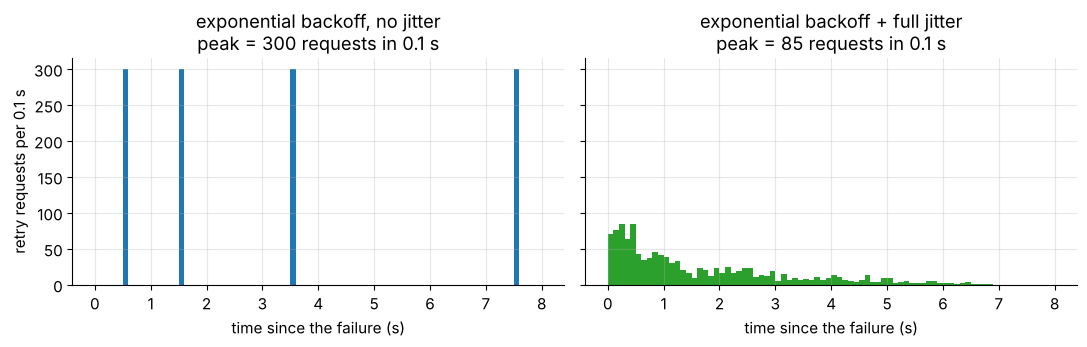

In [10]:
n_clients, base, cap, n_retries = 300, 0.5, 8.0, 4
ceilings = np.minimum(cap, base * 2.0 ** np.arange(n_retries))           # 0.5, 1, 2, 4 seconds
no_jitter = np.cumsum(np.tile(ceilings, (n_clients, 1)), axis=1)         # every client: same retry times
full_jitter = np.cumsum(rng.uniform(0, 1, size=(n_clients, n_retries)) * ceilings, axis=1)

bins = np.arange(0, 8.01, 0.1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, times, title in [(axes[0], no_jitter, "exponential backoff, no jitter"),
                         (axes[1], full_jitter, "exponential backoff + full jitter")]:
    counts, _, _ = ax.hist(times.ravel(), bins=bins, color="C0" if "no" in title else "C2")
    ax.set_title(f"{title}\npeak = {int(counts.max())} requests in 0.1 s")
    ax.set_xlabel("time since the failure (s)")
axes[0].set_ylabel("retry requests per 0.1 s")
plt.tight_layout()
plt.show()

Without jitter, all 300 clients hit the recovering server in the same 0.1-second slot, four times
in a row. With full jitter the same 1,200 retries are smeared out: the peak load drops several-fold
(compare the two panel titles) and, just as important, the retries no longer arrive in synchronized
waves that knock the server over again each time it recovers. We will implement a complete retry
loop (honoring `Retry-After`) in Section 5.0 and use it for every HTTP call in the lake.

> **Common pitfall.** Retrying a non-idempotent request. Retrying `GET` is safe, but retrying a
> `POST /payments` after a timeout may charge a customer twice (the first request may have succeeded
> even though you never saw the response). Well-designed APIs accept an **idempotency key** header so
> the server can recognize and ignore the duplicate.

> **Going deeper.** APIs can also *push* data to you: with **webhooks** the provider calls *your* URL
> whenever something changes. Webhooks reduce polling, but your endpoint must be always up, verify
> signatures, and tolerate duplicate and out-of-order deliveries: the same concerns as streaming (2.4).

Two jitter recipes are common. **Full jitter** draws the wait uniformly from $[0, c_k]$ where
$c_k = \min(\text{cap}, \text{base}\cdot 2^k)$ is the current ceiling, and its average wait is $c_k/2$.
**Equal jitter** keeps half of the ceiling and randomizes the other half, $d_k = c_k/2 + \mathcal{U}(0, c_k/2)$,
so it never retries "too early" (average $3c_k/4$) but spreads clients a little less.

**Worked example** (base 1 s, cap 10 s, 5 retries):

| retry $k$ | ceiling $c_k = \min(10, 2^k)$ | no jitter | full jitter range | equal jitter range |
|---|---|---|---|---|
| 0 | 1 | 1 | [0, 1] | [0.5, 1] |
| 1 | 2 | 2 | [0, 2] | [1, 2] |
| 2 | 4 | 4 | [0, 4] | [2, 4] |
| 3 | 8 | 8 | [0, 8] | [4, 8] |
| 4 | 10 (capped) | 10 | [0, 10] | [5, 10] |

Without jitter the client waits $1+2+4+8+10 = 25$ s in total before giving up. With full jitter the
expected total is half of that, 12.5 s.

#### ✏️ Exercise 2: a backoff schedule generator

Write `backoff_schedule(n_retries, base, cap, jitter, rng)` returning the list of waits (in seconds)
before retry $0, 1, \dots, n_{\text{retries}}-1$ for the three recipes `"none"`, `"full"` and `"equal"`.
Draw random numbers only with `rng.uniform(...)` so that results are reproducible, and raise a
`ValueError` for an unknown `jitter` name.

In [11]:
# ✏️ Exercise 2: backoff schedule generator
def backoff_schedule(n_retries, base, cap, jitter="full", rng=None):
    """Return a list of n_retries waits (seconds) with ceiling c_k = min(cap, base * 2**k).

    jitter="none" : wait_k = c_k
    jitter="full" : wait_k ~ Uniform(0, c_k)
    jitter="equal": wait_k = c_k / 2 + Uniform(0, c_k / 2)
    rng           : a numpy Generator (use np.random.default_rng() if None)
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert backoff_schedule(0, 1.0, 10.0, "none") == [], "zero retries -> empty list"
    got = backoff_schedule(6, 0.5, 8.0, "none")
    assert np.allclose(got, [0.5, 1, 2, 4, 8, 8]), f"no-jitter schedule wrong: {got}"
    ceilings = np.minimum(10.0, 1.0 * 2.0 ** np.arange(5))
    full = np.array(backoff_schedule(5, 1.0, 10.0, "full", np.random.default_rng(0)))
    assert full.shape == (5,) and np.all(full >= 0) and np.all(full <= ceilings), f"full jitter out of range: {full}"
    again = backoff_schedule(5, 1.0, 10.0, "full", np.random.default_rng(0))
    assert np.allclose(full, again), "same seed must give the same schedule"
    equal = np.array(backoff_schedule(5, 1.0, 10.0, "equal", np.random.default_rng(1)))
    assert np.all(equal >= ceilings / 2) and np.all(equal <= ceilings), f"equal jitter out of range: {equal}"
    g = np.random.default_rng(2)
    mean_first = np.mean([backoff_schedule(1, 1.0, 10.0, "full", g)[0] for _ in range(4000)])
    assert abs(mean_first - 0.5) < 0.03, f"full jitter on a 1 s ceiling should average 0.5 s, got {mean_first:.3f}"
    try:
        backoff_schedule(3, 1.0, 10.0, "bogus")
    except ValueError:
        pass
    else:
        raise AssertionError("an unknown jitter name must raise ValueError")


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def backoff_schedule(n_retries, base, cap, jitter="full", rng=None):
    if jitter not in ("none", "full", "equal"):
        raise ValueError(f"unknown jitter: {jitter!r}")
    rng = rng if rng is not None else np.random.default_rng()
    waits = []
    for k in range(n_retries):
        c = min(cap, base * 2 ** k)
        if jitter == "none":
            waits.append(c)
        elif jitter == "full":
            waits.append(rng.uniform(0, c))
        else:
            waits.append(c / 2 + rng.uniform(0, c / 2))
    return waits
```
Validating the argument *before* doing any work makes the error appear even when `n_retries = 0`.
Note that the cap applies to the ceiling, so the jittered waits never exceed `cap` either.
</details>

### 2.3 Flat files: CSV, TSV, TXT, Excel, JSON, XML

**Flat files** are self-contained files that carry data as text or a simple container: CSV
(comma-separated values), TSV (tab-separated), plain TXT (free text or fixed-width columns), Excel
workbooks, and the semi-structured JSON and XML. They are the duct tape of data exchange: a partner
exports a CSV every night, a government publishes an Excel sheet, an app dumps JSON. They are easy to
create and move, but they carry **little or no schema**, so the *reader* has to guess types, and
guesses go wrong. Let us look at a perfectly legal CSV file with five classic traps.

In [12]:
tricky_csv = '''customer_id,name,zip_code,signup_date,lifetime_value,notes
1,"Rivera, Ana",02139,03/04/2026,"1,250.50","said ""call me later"""
2,Chen,10001,2026-03-05,99.9,
3,O'Neil,N/A,05/03/2026,NA,"line one
line two"
4,Okafor,00501,2026-03-07,0,
'''
naive = pd.read_csv(io.StringIO(tricky_csv))
print("Naive read: dtypes ->", dict(naive.dtypes.astype(str)))
display(naive)

Naive read: dtypes -> {'customer_id': 'int64', 'name': 'object', 'zip_code': 'float64', 'signup_date': 'object', 'lifetime_value': 'object', 'notes': 'object'}


,customer_id,name,zip_code,signup_date,lifetime_value,notes
0,1,"Rivera, Ana",2139.0,03/04/2026,"1,250.50","said ""call me later"""
1,2,Chen,10001.0,2026-03-05,99.9,NaN
2,3,O'Neil,NaN,05/03/2026,NaN,line one\nline two
3,4,Okafor,501.0,2026-03-07,0,NaN


Look closely at what the naive read did:

1. **Quoting.** `"Rivera, Ana"` contains the delimiter and `""` is an escaped quote. A correct CSV parser
   handles both, but a hand-written `line.split(",")` would not.
2. **Embedded newline.** Row 3's note spans two physical lines, so "count the lines" ≠ "count the rows".
3. **Leading zeros.** `zip_code` was guessed to be numeric, so `02139` became `2139.0` and `00501`
   became `501.0`: the identifiers are destroyed (the `.0` appears because `N/A` became a missing value,
   which forces a float column).
4. **Numbers as text.** `"1,250.50"` uses a thousands separator, so the whole column stayed text.
5. **Ambiguous dates.** Is `03/04/2026` March 4 (US style) or April 3 (most of the world)? The column
   also mixes two formats.

The fix is to **stop guessing** and state the schema explicitly:

In [13]:
careful = pd.read_csv(
    io.StringIO(tricky_csv),
    dtype={"customer_id": "int64", "name": "string", "zip_code": "string", "notes": "string"},
    thousands=",",                      # "1,250.50" -> 1250.5
    na_values=["N/A", "NA"], keep_default_na=False,
)
iso = pd.to_datetime(careful["signup_date"], format="%Y-%m-%d", errors="coerce")
us = pd.to_datetime(careful["signup_date"], format="%m/%d/%Y", errors="coerce")
eu = pd.to_datetime(careful["signup_date"], format="%d/%m/%Y", errors="coerce")
careful["signup_if_US"] = iso.fillna(us).dt.date
careful["signup_if_EU"] = iso.fillna(eu).dt.date
display(careful.drop(columns=["notes"]))

# Two more classics: European number formats and text encodings.
euro = pd.read_csv(io.StringIO("item;price\nlamp;3,50\nchair;12,00\n"), sep=";", decimal=",")
print("European CSV prices:", euro["price"].tolist())
raw_bytes = "Café Müller".encode("cp1252")             # a file saved by an old Windows program
try:
    raw_bytes.decode("utf-8")
except UnicodeDecodeError as err:
    print("decoding as UTF-8 fails:", err)
print("decoding as cp1252 works:", raw_bytes.decode("cp1252"))

,customer_id,name,zip_code,signup_date,lifetime_value,signup_if_US,signup_if_EU
0,1,"Rivera, Ana",02139,03/04/2026,1250.5,2026-03-04,2026-04-03
1,2,Chen,10001,2026-03-05,99.9,2026-03-05,2026-03-05
2,3,O'Neil,<NA>,05/03/2026,NaN,2026-05-03,2026-03-05
3,4,Okafor,00501,2026-03-07,0.0,2026-03-07,2026-03-07


European CSV prices: [3.5, 12.0]
decoding as UTF-8 fails: 'utf-8' codec can't decode byte 0xe9 in position 3: invalid continuation byte
decoding as cp1252 works: Café Müller


Notice that the explicit schema fixes the ZIP codes and the amounts, but **no code can decide the
date ambiguity for you**: rows 1 and 3 give different dates depending on the convention. Only an
agreement with the data producer (a *data contract*, ideally "dates are ISO 8601: `YYYY-MM-DD`") can.

JSON and XML are **semi-structured**: every value is labeled, and records can be nested and can have
optional fields. JSON Lines (`.jsonl`, one JSON object per line) is popular for logs and data exchange
because it can be appended to and streamed line by line.

In [14]:
orders_json = [
    {"order_id": 1, "customer": {"id": 7, "city": "Toronto"},
     "items": [{"sku": "P1", "qty": 2}, {"sku": "P9", "qty": 1}]},
    {"order_id": 2, "customer": {"id": 3, "city": "Ottawa"},
     "items": [{"sku": "P4", "qty": 5}], "coupon": "SPRING"},          # an optional field
]
jsonl_text = "\n".join(json.dumps(o) for o in orders_json)
print("JSON Lines file:\n" + jsonl_text + "\n")
flat = pd.json_normalize([json.loads(line) for line in jsonl_text.splitlines()],
                         record_path="items", meta=["order_id", ["customer", "city"], "coupon"],
                         errors="ignore")
display(flat)

orders_xml = """<orders>
  <order id="1"><customer id="7" city="Toronto"/><item sku="P1" qty="2"/><item sku="P9" qty="1"/></order>
  <order id="2" coupon="SPRING"><customer id="3" city="Ottawa"/><item sku="P4" qty="5"/></order>
</orders>"""
xml_rows = [{"order_id": int(o.get("id")), "city": o.find("customer").get("city"),
             "sku": it.get("sku"), "qty": int(it.get("qty")), "coupon": o.get("coupon")}
            for o in ET.fromstring(orders_xml).iter("order") for it in o.iter("item")]
print("Same data parsed from XML:", xml_rows[:2], "...")

JSON Lines file:
{"order_id": 1, "customer": {"id": 7, "city": "Toronto"}, "items": [{"sku": "P1", "qty": 2}, {"sku": "P9", "qty": 1}]}
{"order_id": 2, "customer": {"id": 3, "city": "Ottawa"}, "items": [{"sku": "P4", "qty": 5}], "coupon": "SPRING"}



,sku,qty,order_id,customer.city,coupon
0,P1,2,1,Toronto,NaN
1,P9,1,1,Toronto,NaN
2,P4,5,2,Ottawa,SPRING


Same data parsed from XML: [{'order_id': 1, 'city': 'Toronto', 'sku': 'P1', 'qty': 2, 'coupon': None}, {'order_id': 1, 'city': 'Toronto', 'sku': 'P9', 'qty': 1, 'coupon': None}] ...


Flattening nested JSON produced one row per *item*, with order-level fields repeated, and the missing
`coupon` simply becomes a missing value. The XML version carries the same information with more
characters and needed hand-written parsing code.

Excel deserves its own warning. A workbook stores typed cells (numbers, dates, text) and is what
business users actually send you, but it has a hard limit of 1,048,576 rows per sheet, and it
"helpfully" converts values on entry. Genomics researchers famously lost gene names such as `SEPT2`
and `MARCH1` because Excel turned them into dates, a problem big enough that the official gene names
were changed in 2020. Reading and writing `.xlsx` from pandas uses the `openpyxl` package:

In [15]:
xlsx_path = PLAY / "partner_report.xlsx"
pd.DataFrame({"sku": ["P0001", "P0002"], "zip_code": ["02139", "00501"],
              "shipped": pd.to_datetime(["2026-03-01", "2026-03-02"]), "qty": [3, 7]}
             ).to_excel(xlsx_path, index=False)
back = pd.read_excel(xlsx_path, dtype={"zip_code": "string"})
print("Round trip through Excel, dtypes:", dict(back.dtypes.astype(str)))
display(back)

Round trip through Excel, dtypes: {'sku': 'object', 'zip_code': 'string', 'shipped': 'datetime64[ns]', 'qty': 'int64'}


,sku,zip_code,shipped,qty
0,P0001,02139,2026-03-01,3
1,P0002,00501,2026-03-02,7


| Format | Structure | Strengths | Weaknesses | Typical use |
|---|---|---|---|---|
| CSV / TSV | rows and columns of text | universal, human-readable, appendable, streamable | no types or schema, quoting/delimiter/decimal/encoding ambiguity, no nesting and no compression | exports, data exchange |
| TXT | free text or fixed-width fields | simplest possible | needs a custom parser per file layout | logs, legacy exports |
| Excel (`.xlsx`) | sheets of typed cells | what business users produce, and it has types | row limit, silent auto-conversion, merged cells and formulas, slow to parse | manual reports, partner uploads |
| JSON / JSON Lines | nested key–value | self-describing, optional and nested fields, the language of web APIs | verbose (keys repeated on every record), and no native date type | API payloads, event logs |
| XML | nested tags and attributes | formal schemas (XSD), namespaces, mature tools | very verbose, and parsing is fiddly | RSS/Atom feeds, enterprise and government exchange |

All of these become painful when files get **large**: to answer "what is the average price?" you must
read and parse every byte, because there is no index and no way to read just one column. Section 4.4
measures how columnar formats such as Parquet solve this.

<details>
<summary><b>Quick check:</b> a partner's CSV has a column <code>account_no</code> with values like <code>000731</code>. What will a default <code>pd.read_csv</code> do, and how do you prevent it?</summary>

It infers an integer column and turns `000731` into `731`, destroying the identifier (and two accounts
`0731` and `731` would collide). Pass `dtype={"account_no": "string"}` (or `str`), and better, agree on
a schema with the producer so identifiers are always declared as text.
</details>

### 2.4 Streaming data: events, brokers, topics and offsets

> **Intuition.** A batch source is like a newspaper delivered every morning: one big bundle per day.
> A stream is like a live news ticker: an endless sequence of small items, each delivered seconds
> after it happened. You never "finish downloading" a stream. You keep reading it.

An **event** is an immutable record of something that happened at a point in time: "user 42 added
item P7 to the cart at 09:15:02.381", "sensor T-17 measured 21.4 °C", "row 1009 of table `orders`
was updated". An event usually carries a **key** (what it is about, e.g. the user id), a **value**
(the payload, often JSON, Avro or Protobuf), a **timestamp** and optional headers. **Producers**
(apps, sensors, databases) send events to a **broker**, a server that stores and forwards them, and
**consumers** (our ingestion job, a fraud detector, a dashboard) read them. Producers and consumers
never talk to each other directly, so either side can be slow, restarted or replaced independently.

Three brokers you will meet everywhere:

| | Apache Kafka | RabbitMQ | MQTT brokers (Mosquitto, EMQX, HiveMQ, ...) |
|---|---|---|---|
| Model | distributed, partitioned, replicated **append-only log** | **message queue** with flexible routing (AMQP protocol) | lightweight **publish/subscribe** protocol |
| After a consumer reads | the event **stays** (kept for a retention period, 7 days by default), and anyone can re-read it (**replay**) | the message is **deleted** once the consumer acknowledges it | delivered to the current subscribers, and the broker can keep the last ("retained") message per topic |
| Ordering | guaranteed **within a partition** | per queue, with caveats on redelivery | per topic and session |
| Scaling unit | partitions, and a consumer group shares them | more consumers on the same queue | very many small clients per broker cluster |
| Typical use | event pipelines, change data capture, log aggregation, ML feature streams | task queues and routing between services | sensors and devices on unreliable networks |

Kafka's vocabulary is worth learning precisely, because most streaming systems copy it:

- A **topic** is a named stream, for example `clicks` or `payments`.
- A topic is split into $P$ **partitions**. Each partition is an ordered, append-only log stored (and
  replicated) on the brokers. Partitions are the unit of parallelism.
- An **offset** is an event's position inside its partition: 0, 1, 2, ... The triple
  (topic, partition, offset) identifies an event uniquely.
- The producer chooses the partition by hashing the key: $\text{partition} = h(\text{key}) \bmod P$.
  All events with the same key therefore land in the **same partition, in order**.
- A **consumer group** is a set of consumers that share the work: each partition is read by exactly
  one consumer of the group, so at most $P$ consumers can be busy. Different groups are independent:
  the lake archiver and the fraud detector each receive every event.
- Each group stores a **committed offset** per partition: the offset of the next event it will read.
  After a crash, consumers resume from there. *When* you commit (before or after processing) decides
  whether events can be lost or duplicated (Section 3.6).

```text
 topic "clicks" (3 partitions)                     group "lake-archiver"     group "fraud-detector"
 partition 0: [0][1][2][3][4][5] ...   ------->    consumer A, next=4        consumer X, next=6
 partition 1: [0][1][2][3] ...         ------->    consumer A, next=1        consumer X, next=4
 partition 2: [0][1][2][3][4] ...      ------->    consumer B, next=5        consumer Y, next=2
              new events are appended on the right; nothing is removed when it is read
```

The hash $h$ must be **stable**: the same key must map to the same partition in every process and on
every machine, forever. Kafka uses the murmur2 hash. We will use CRC-32 from `zlib`. Python's built-in
`hash()` is *not* suitable, as the next cell shows.

In [16]:
def partition_for(key: str, n_partitions: int) -> int:
    """Map a key to a partition with a stable hash (same answer in every process, on every machine)."""
    return zlib.crc32(key.encode("utf-8")) % n_partitions


print("partition of 'user-17' among 3 partitions:", partition_for("user-17", 3), "(always)")

# Python salts hash() of strings with a random value chosen when the interpreter starts (a defense
# against attacks on dictionaries), so two processes disagree about hash('user-17').
probe = [sys.executable, "-c", "print(hash('user-17'))"]
h1, h2 = (subprocess.run(probe, capture_output=True, text=True).stdout.strip() for _ in range(2))
print("hash('user-17') in two fresh Python processes:", h1, "and", h2,
      "-> different" if h1 != h2 else "-> equal (PYTHONHASHSEED is fixed in this environment)")

partition of 'user-17' among 3 partitions: 1 (always)
hash('user-17') in two fresh Python processes: -6901645090742448801 and -6766820339282645940 -> different


Now a toy, in-memory version of a Kafka topic. It is only a few lines, but it has the three ideas that
matter: partitions chosen by key, offsets, and per-group committed offsets that are separate from the
data itself.

In [17]:
class MiniLog:
    """A toy in-memory Kafka topic: P append-only partitions plus committed offsets per consumer group."""

    def __init__(self, n_partitions: int):
        self.partitions = [[] for _ in range(n_partitions)]
        self.committed = {}                      # (group, partition) -> offset of the next event to read

    def produce(self, key: str, value: dict) -> tuple[int, int]:
        """Append an event; return its (partition, offset)."""
        p = partition_for(key, len(self.partitions))
        self.partitions[p].append({"key": key, **value})
        return p, len(self.partitions[p]) - 1

    def poll(self, group: str, partition: int, max_events: int = 100) -> tuple[int, list]:
        """Return (first_offset, events) starting at the group's committed offset. Reading never moves it."""
        start = self.committed.get((group, partition), 0)
        return start, self.partitions[partition][start:start + max_events]

    def commit(self, group: str, partition: int, next_offset: int) -> None:
        """Record that `group` has finished everything before `next_offset` in `partition`."""
        self.committed[(group, partition)] = next_offset


clicks = MiniLog(n_partitions=3)
r = np.random.default_rng(7)
users = ["user-17", "user-42", "user-23", "user-08"]
seq = dict.fromkeys(users, 0)
for i in range(14):
    u = users[r.integers(len(users))]
    seq[u] += 1                                          # per-user sequence number 1, 2, 3, ...
    clicks.produce(u, {"seq": seq[u], "sent_order": i})
for p, part in enumerate(clicks.partitions):
    print(f"partition {p}: " + "  ".join(f"[{off}]{e['key']}#{e['seq']}" for off, e in enumerate(part)))

partition 0: [0]user-08#1  [1]user-08#2  [2]user-08#3  [3]user-08#4  [4]user-08#5  [5]user-08#6
partition 1: [0]user-17#1  [1]user-17#2  [2]user-42#1  [3]user-42#2  [4]user-17#3
partition 2: [0]user-23#1  [1]user-23#2  [2]user-23#3


Read the printout carefully:

- Each user always lands in the same partition, and inside a partition each user's sequence numbers
  increase (`#1`, `#2`, ...): **ordering per key is guaranteed**.
- There is **no global order** across partitions. Two consumers reading partitions 0 and 1 in parallel
  may process event `sent_order = 5` before `sent_order = 2`. If you need "all events in the exact
  order they were sent", you need a single partition, and you give up parallelism.
- Partitions are only *roughly* balanced. Hashing spreads **many** keys evenly, but here two of the four
  users share partition 1, and a single very active key (a "hot key", such as a celebrity account)
  always lands in one partition and can overload the consumer that owns it.

Consumer groups split the partitions among their members, and separate groups keep separate offsets:

In [18]:
def assign_partitions(n_partitions: int, consumers: list) -> dict:
    """Round-robin assignment: each partition goes to exactly one consumer of the group."""
    plan = {c: [] for c in consumers}
    for p in range(n_partitions):
        plan[consumers[p % len(consumers)]].append(p)
    return plan


print("lake-archiver with 2 consumers:", assign_partitions(3, ["A", "B"]))
print("lake-archiver with 4 consumers:", assign_partitions(3, ["A", "B", "C", "D"]), "<- D has nothing to do")

# Two groups read partition 0 independently.
start, events = clicks.poll("lake-archiver", partition=0, max_events=3)
clicks.commit("lake-archiver", 0, start + len(events))
clicks.commit("fraud-detector", 0, len(clicks.partitions[0]))         # this group read everything
print("committed offsets:", clicks.committed)

# Replay: rewind the archiver to the beginning (possible because the log keeps events after reading).
clicks.commit("lake-archiver", 0, 0)
print("after the rewind, the archiver's next read starts at offset", clicks.poll("lake-archiver", 0)[0])

lake-archiver with 2 consumers: {'A': [0, 2], 'B': [1]}
lake-archiver with 4 consumers: {'A': [0], 'B': [1], 'C': [2], 'D': []} <- D has nothing to do
committed offsets: {('lake-archiver', 0): 3, ('fraud-detector', 0): 6}
after the rewind, the archiver's next read starts at offset 0


Finally, the failure that every streaming pipeline must be designed for. A consumer reads a batch,
writes it to the lake, and **crashes before committing** its offset. After the restart it reads from
the old committed offset, so the same batch is written again:

In [19]:
sink = []
start, batch = clicks.poll("lake-archiver", 0, max_events=4)
sink.extend(batch)                       # 1) write the batch to the lake
# 2) ... the process crashes HERE, before clicks.commit(...) ...
start, batch = clicks.poll("lake-archiver", 0, max_events=4)       # 3) after the restart
sink.extend(batch)
clicks.commit("lake-archiver", 0, start + len(batch))
distinct = {(e["key"], e["seq"]) for e in sink}
print(f"events written to the sink: {len(sink)}, distinct events: {len(distinct)}")

events written to the sink: 8, distinct events: 4


Every event of the batch was written twice. Nothing was lost (good) but the sink now holds duplicates
(bad, if we sum revenue from it). This is **at-least-once delivery**, the normal case in practice.
Section 3.6 shows how idempotent writes and deduplication keys make the *result* exactly-once anyway.

**RabbitMQ in one paragraph.** Producers publish to an **exchange**, which routes a copy of each
message into one or more **queues** according to *bindings*: a `direct` exchange matches the routing
key exactly, a `topic` exchange matches patterns over dotted keys such as `orders.*.canada`, and a
`fanout` exchange copies to every bound queue. Consumers take messages from a queue and
**acknowledge** them, and an unacknowledged message is redelivered if its consumer dies. Because
acknowledged messages are gone, a queue is ideal for distributing *work* (resize this image, send this
email) but not for replaying history. (Recent RabbitMQ versions also offer log-style "streams".)

**MQTT in one paragraph.** MQTT was designed for small devices on flaky networks: the fixed header can be
as small as 2 bytes, sessions survive reconnects, and a keep-alive detects dead links. Devices publish to
hierarchical **topics** such as `factory/hall-2/press-7/temperature`, and subscribers use wildcards:
`+` matches exactly one level and `#` matches any number of levels (only as the last level). Each
message has a **QoS** level: 0 = at most once (fire and forget), 1 = at least once (acknowledged,
duplicates possible), 2 = exactly once (a four-step handshake, the slowest). A **retained** message
is stored by the broker and handed to every new subscriber (handy for "the latest setting"), and a
**last will** message is published by the broker when a device disconnects without saying goodbye.
A very common IoT architecture is: devices → MQTT broker → bridge → Kafka → data lake.

> **Going deeper.** Event payloads evolve (new fields, renamed fields). Teams therefore register a
> schema per topic (Avro, Protobuf or JSON Schema) in a **schema registry**, which rejects producer
> changes that would break existing consumers. This is the streaming version of the schema-drift
> problem we meet in Sections 2.9 and 5.3.

#### ✏️ Exercise 3: MQTT topic filters

Implement `mqtt_match(topic_filter, topic)`. Levels are separated by `/`. In the filter, `+` matches
exactly one level (an empty level counts as a level), and `#` matches the current level and everything
below it, **including nothing at all**: by the MQTT specification `sport/#` also matches `sport`.
Matching is case-sensitive. Raise `ValueError` for an invalid filter: `#` anywhere except as the whole
last level, or `+` sharing a level with other characters (for example `a/b+/c`).

In [20]:
# ✏️ Exercise 3: MQTT topic filters
def mqtt_match(topic_filter: str, topic: str) -> bool:
    """True if `topic` (no wildcards) matches the subscription `topic_filter` (may use + and #)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = [
        ("sensors/+/temp", "sensors/kitchen/temp", True),
        ("sensors/+/temp", "sensors/kitchen/ceiling/temp", False),
        ("sensors/#", "sensors/kitchen/ceiling/temp", True),
        ("sensors/#", "sensors", True),                       # '#' also matches the parent level
        ("sensors/+", "sensors", False),                      # '+' needs exactly one level
        ("sensors/+/temp", "sensors//temp", True),            # an empty level is still a level
        ("#", "a/b/c", True),
        ("+/+", "a/b", True),
        ("+/+", "a", False),
        ("factory/hall-2/press-7", "factory/hall-2/press-7", True),
        ("factory/hall-2/press-7", "factory/Hall-2/press-7", False),   # case-sensitive
        ("a/b", "a/b/c", False),
    ]
    for f, t, want in cases:
        got = mqtt_match(f, t)
        assert got == want, f"mqtt_match({f!r}, {t!r}) returned {got}, expected {want}"
    for bad in ["a/#/b", "a/b#", "a/b+/c", "#/x"]:
        try:
            mqtt_match(bad, "a/b/c")
        except ValueError:
            continue
        raise AssertionError(f"invalid filter {bad!r} should raise ValueError")


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mqtt_match(topic_filter, topic):
    f_levels, t_levels = topic_filter.split("/"), topic.split("/")
    for i, f in enumerate(f_levels):                       # validate the whole filter first
        if ("#" in f and (f != "#" or i != len(f_levels) - 1)) or ("+" in f and f != "+"):
            raise ValueError(f"invalid filter: {topic_filter!r}")
    for i, f in enumerate(f_levels):
        if f == "#":
            return True                    # matches this level, all deeper levels, or nothing
        if i >= len(t_levels):
            return False                   # the topic ran out of levels
        if f != "+" and f != t_levels[i]:
            return False
    return len(f_levels) == len(t_levels)   # no leftover topic levels
```
The key is to walk both level lists in parallel. Validating first guarantees that an invalid filter
raises an error even when the topic would have failed to match anyway.
</details>

### 2.5 Cloud storage and managed data services

More and more often, the "source" already lives in the cloud: a partner shares a bucket with you, an
app writes its nightly exports to object storage, another team publishes a table in a cloud data
warehouse. The same services are also where most data lakes are built (Section 4), so it pays to
understand their model well.

**Object storage** (Amazon S3, Google Cloud Storage, Azure Blob Storage, and S3-compatible systems such
as MinIO) stores **objects** (any bytes plus a little metadata) inside **buckets**, addressed by a **key**:

```text
s3://acme-partner-exports/sales/2026/03/02/sales.csv
     |-------- bucket ----||--------- key -----------|
```

- **Flat namespace.** There are no real folders: `sales/2026/03/` is just a common *prefix* shared by
  many keys. Consoles and tools *display* folders by grouping keys on the `/` delimiter.
- **Whole-object operations.** `PUT` (write an object), `GET` (read all of it or a byte range), `HEAD`
  (metadata only), `LIST` (keys under a prefix, returned in pages of up to 1,000 on S3) and `DELETE`.
  In general you cannot edit an object in place: "changing" an object means writing it again. (A few
  specialized object types are exceptions, such as Azure's append blobs and the appendable objects of
  S3 Express One Zone, used mostly for logs.)
- **Durability and scale.** S3 is designed for 99.999999999% ("eleven nines") durability, and capacity
  is effectively unlimited.
- **Strong consistency.** S3 (since December 2020), Google Cloud Storage and Azure Blob Storage all give
  strong read-after-write consistency: once a `PUT` succeeds, every later `GET` and `LIST` sees it.
- **Pay per use.** You pay for storage (per GB-month), for requests (per 1,000 operations) and for
  **egress** (data leaving the provider's network). Storage classes trade cheaper storage for slower or
  more expensive access (hot, infrequent-access and archive tiers), and lifecycle rules move or delete
  old objects automatically.
- **Event notifications.** A bucket can emit an event whenever an object is created, so an ingestion
  job can be *triggered* by new files instead of polling for them.

The toy store below makes the flat-namespace idea concrete. Watch what "listing a folder" and "renaming
a folder" really mean.

In [21]:
class ToyObjectStore:
    """A dict pretending to be a bucket: flat keys, whole-object PUT/GET, LIST by prefix and delimiter."""

    def __init__(self):
        self.objects: dict[str, bytes] = {}
        self.requests = dict.fromkeys(["PUT", "GET", "LIST", "COPY", "DELETE"], 0)

    def put(self, key: str, data: bytes) -> None:
        self.requests["PUT"] += 1
        self.objects[key] = bytes(data)

    def get(self, key: str) -> bytes:
        self.requests["GET"] += 1
        return self.objects[key]

    def list(self, prefix: str = "", delimiter: str | None = None, page_size: int = 1000):
        """Return (keys, common_prefixes) like S3's ListObjectsV2; count one LIST request per page."""
        keys, prefixes = [], set()
        for key in sorted(self.objects):
            if not key.startswith(prefix):
                continue
            rest = key[len(prefix):]
            if delimiter and delimiter in rest:          # group deeper keys into a "folder"
                prefixes.add(prefix + rest.split(delimiter, 1)[0] + delimiter)
            else:
                keys.append(key)
        self.requests["LIST"] += max(1, math.ceil((len(keys) + len(prefixes)) / page_size))
        return keys, sorted(prefixes)

    def rename_prefix(self, old: str, new: str) -> int:
        """'Rename a folder'. On a flat namespace that means COPY + DELETE for every object under it."""
        moved = [k for k in self.objects if k.startswith(old)]
        for k in moved:
            self.objects[new + k[len(old):]] = self.objects.pop(k)
            self.requests["COPY"] += 1
            self.requests["DELETE"] += 1
        return len(moved)


bucket = ToyObjectStore()
for day in ["2026-03-01", "2026-03-02", "2026-03-03"]:
    for hour in range(24):
        bucket.put(f"clicks/dt={day}/hour={hour:02d}/part-0.json", b'{"n": 0}')
bucket.put("README.txt", b"partner export, contact data-team@example.com")

print("LIST ''        (delimiter '/'):", bucket.list("", delimiter="/"))
print("LIST 'clicks/' (delimiter '/'):", bucket.list("clicks/", delimiter="/"))
keys, _ = bucket.list("clicks/dt=2026-03-02/")
print(f"LIST 'clicks/dt=2026-03-02/' (no delimiter): {len(keys)} keys, first = {keys[0]}")
n_moved = bucket.rename_prefix("clicks/", "events/clicks/")
print(f"renaming the 'folder' clicks/ touched {n_moved} objects:",
      f"{bucket.requests['COPY']} COPY + {bucket.requests['DELETE']} DELETE requests")

LIST ''        (delimiter '/'): (['README.txt'], ['clicks/'])
LIST 'clicks/' (delimiter '/'): ([], ['clicks/dt=2026-03-01/', 'clicks/dt=2026-03-02/', 'clicks/dt=2026-03-03/'])
LIST 'clicks/dt=2026-03-02/' (no delimiter): 24 keys, first = clicks/dt=2026-03-02/hour=00/part-0.json
renaming the 'folder' clicks/ touched 72 objects: 72 COPY + 72 DELETE requests


The "folders" `clicks/`, `dt=2026-03-02/`, ... do not exist anywhere: `LIST` computes them on the fly
from the keys. And renaming a "folder" of 72 objects cost 144 requests. On a real store each request
takes roughly 10–100 ms and costs money, so renaming a prefix holding millions of objects takes hours,
and it is **not atomic**: a reader in the middle sees some files at the old place and some at the new
one. That is why lake tools avoid renames (Section 4.7), and why Azure Data Lake Storage Gen2 adds a
*hierarchical namespace* in which renaming a directory is one atomic metadata operation (Section 4.8).

**Managed data services as sources.** Cloud data warehouses (BigQuery, Snowflake, Amazon Redshift,
Azure Synapse / Microsoft Fabric) and managed databases (Amazon RDS, Cloud SQL, Azure SQL, DynamoDB,
Firestore) are common sources too. You typically ingest from them in one of three ways:

1. **Query** them through a client library or a JDBC/ODBC driver: fine for small results.
2. Ask them to **export** large results to object storage in a columnar format (BigQuery's
   `EXPORT DATA` to Cloud Storage, Snowflake's `COPY INTO` a stage, Redshift's `UNLOAD` to S3), then
   ingest the files.
3. Subscribe to their **change streams** (CDC, Section 3.5).

Pricing models shape these designs. Pay-per-query engines (BigQuery on-demand, Amazon Athena) charge
for the **bytes scanned**, so the *layout* of the data (columnar files, partitions) directly decides
the bill. A back-of-the-envelope calculation with illustrative round prices:

In [22]:
# Illustrative round prices only (order of magnitude); always check the provider's current price list.
STORAGE_USD_PER_GB_MONTH = 0.02      # standard object-storage tier
SCAN_USD_PER_TB = 5.0                # pay-per-query SQL engine
dataset_tb, queries_per_day = 5.0, 40

print(f"storing {dataset_tb:.0f} TB: about {dataset_tb * 1000 * STORAGE_USD_PER_GB_MONTH:,.0f} USD per month")
scenarios = [("SELECT * over the whole table", 1.0),
             ("2 of 20 columns, columnar file format", 2 / 20),
             ("2 of 20 columns, 1 daily partition out of 365", 2 / 20 / 365)]
for label, fraction_scanned in scenarios:
    monthly = queries_per_day * 30 * dataset_tb * fraction_scanned * SCAN_USD_PER_TB
    print(f"{label:46s} -> {monthly:>10,.2f} USD per month for queries")

storing 5 TB: about 100 USD per month
SELECT * over the whole table                  ->  30,000.00 USD per month for queries
2 of 20 columns, columnar file format          ->   3,000.00 USD per month for queries
2 of 20 columns, 1 daily partition out of 365  ->       8.22 USD per month for queries


Storing 5 TB costs about 100 USD a month, but scanning all of it 40 times a day would cost 30,000 USD a
month. Reading only the needed columns (a columnar format such as Parquet) cuts that tenfold, and
reading only the needed day (partitioning) cuts it to a few dollars. Section 4 explains both techniques,
and Section 4.4 measures them on real files.

<details>
<summary><b>Quick check:</b> a partner delivers 10 million tiny JSON objects (2 KB each) per day into a bucket. The total is only 20 GB. Why can this still be slow and expensive to ingest?</summary>

Object-store costs and latency are per *request*, not just per byte. Reading 10 million objects needs
at least 10 million `GET`s plus 10,000 `LIST` pages, and at tens of milliseconds each that is days of
sequential work (or heavy parallelism), and the request fees add up. This is the **small-files
problem** (Section 4.5). Ask the partner to batch records into fewer, larger files (for example one
compressed JSON Lines or Parquet file per hour), or compact the files right after landing them.
</details>

### 2.6 The web: RSS/Atom feeds, scraping and social media

Public websites, forums, news sites and social platforms hold enormous amounts of text and media.
There are three ways to get at it, from most to least polite:

1. **Official APIs and data dumps.** Documented, stable, authenticated, rate-limited, and covered by
   clear terms of use. Social platforms expose their data this way (posts, authors, timestamps,
   engagement counts, media links as semi-structured JSON), and access is often restricted or paid (both X,
   formerly Twitter, and Reddit introduced paid API tiers in 2023).
2. **Feeds.** An **RSS 2.0** or **Atom** feed is a small XML document listing a site's latest items
   (title, link, date, summary). Polling a feed every few hours, with conditional requests (the `ETag`
   and `Last-Modified` headers, answered by `304 Not Modified` when nothing changed), costs the site
   almost nothing. Section 5.1 parses an Atom feed from arXiv.
3. **Web scraping.** Downloading HTML pages and extracting fields with a parser. It works on any site
   but it is fragile (a redesign breaks your parser), it is heavy for the site, and it raises legal and
   ethical questions.

**The Robots Exclusion Protocol.** A site publishes `/robots.txt` to tell automated clients which paths
they may fetch. It was standardized as RFC 9309 in 2022. Python ships a parser for it:

In [23]:
ROBOTS_TXT = """\
# robots.txt of https://shop.example.org (a made-up site)
User-agent: *
Allow: /accounts/help/
Disallow: /accounts/
Disallow: /cart
Disallow: /search
Crawl-delay: 2

User-agent: GreedyBot
Disallow: /
"""
robots = urllib.robotparser.RobotFileParser()
robots.parse(ROBOTS_TXT.splitlines())

agent = "ai-foundations-lake-bot"
for path in ["/products/lamp-42", "/accounts/settings", "/accounts/help/returns", "/search?q=lamp", "/cart"]:
    url = "https://shop.example.org" + path
    print(f"{path:24s} {agent}: {str(robots.can_fetch(agent, url)):5s}   GreedyBot: {robots.can_fetch('GreedyBot', url)}")
print(f"requested delay between requests for {agent}: {robots.crawl_delay(agent)} s")

/products/lamp-42        ai-foundations-lake-bot: True    GreedyBot: False
/accounts/settings       ai-foundations-lake-bot: False   GreedyBot: False
/accounts/help/returns   ai-foundations-lake-bot: True    GreedyBot: False
/search?q=lamp           ai-foundations-lake-bot: False   GreedyBot: False
/cart                    ai-foundations-lake-bot: False   GreedyBot: False
requested delay between requests for ai-foundations-lake-bot: 2 s


Product pages are allowed, private areas are not, the help pages are explicitly re-allowed inside the
forbidden `/accounts/` area, and `GreedyBot` is banned from everything. `Crawl-delay` is not part of
RFC 9309, but many sites use it and polite crawlers honor it.

> **Going deeper.** When an `Allow` and a `Disallow` rule both match a path, RFC 9309 says the **most
> specific** (longest) rule wins. Older parsers, including older versions of Python's `robotparser`,
> used the *first* matching rule instead. Writing the narrow `Allow` line before the broad `Disallow`
> line, as above, gives the same answer under both conventions.

**Scraping is fragile.** The next cell extracts products from a page in two ways: by walking the
visual layout (`<div class="card">`), and by reading the page's embedded **JSON-LD** block, a
machine-readable summary (schema.org vocabulary) that many sites include for search engines. Then the
site "redesigns" its HTML.

In [24]:
PAGE_V1 = """<html><head><title>Lamps | Example Shop</title>
<script type="application/ld+json">
{"@type": "ItemList", "itemListElement": [
  {"@type": "Product", "sku": "L-42", "name": "Desk lamp", "offers": {"price": "24.90", "priceCurrency": "CAD"}},
  {"@type": "Product", "sku": "L-77", "name": "Floor lamp", "offers": {"price": "89.00", "priceCurrency": "CAD"}}]}
</script></head><body>
<div class="card" data-sku="L-42"><h2>Desk lamp</h2><span class="price">$24.90</span></div>
<div class="card" data-sku="L-77"><h2>Floor lamp</h2><span class="price">$89.00</span></div>
</body></html>"""
# The redesign: new class names and tags for the visible layout; the JSON-LD block is unchanged.
PAGE_V2 = (PAGE_V1.replace('class="card"', 'class="product-tile"')
           .replace('<span class="price">', '<p class="cost">').replace("</span>", "</p>"))


class CardParser(HTMLParser):
    """Collect {sku, name, price} from <div class="card"> blocks: tied to the visual layout."""

    def __init__(self):
        super().__init__()
        self.rows, self._row, self._field = [], None, None

    def handle_starttag(self, tag, attrs):
        a = dict(attrs)
        if tag == "div" and a.get("class") == "card":
            self._row = {"sku": a.get("data-sku")}
        elif self._row is not None and tag == "h2":
            self._field = "name"
        elif self._row is not None and tag == "span" and a.get("class") == "price":
            self._field = "price"

    def handle_data(self, data):
        if self._row is not None and self._field:
            self._row[self._field] = data.strip()
            self._field = None

    def handle_endtag(self, tag):
        if tag == "div" and self._row is not None:
            self.rows.append(self._row)
            self._row = None


class JsonLdParser(HTMLParser):
    """Collect the JSON-LD blocks (<script type="application/ld+json">) of a page."""

    def __init__(self):
        super().__init__()
        self.blocks, self._buffer = [], None

    def handle_starttag(self, tag, attrs):
        if tag == "script" and dict(attrs).get("type") == "application/ld+json":
            self._buffer = []

    def handle_data(self, data):
        if self._buffer is not None:
            self._buffer.append(data)

    def handle_endtag(self, tag):
        if tag == "script" and self._buffer is not None:
            self.blocks.append(json.loads("".join(self._buffer)))
            self._buffer = None


def scrape(page: str) -> tuple[list, list]:
    cards, ld = CardParser(), JsonLdParser()
    cards.feed(page)
    ld.feed(page)
    products = [{"sku": p["sku"], "name": p["name"], "price": float(p["offers"]["price"])}
                for block in ld.blocks for p in block.get("itemListElement", [])]
    return cards.rows, products


for label, page in [("original page", PAGE_V1), ("after the redesign", PAGE_V2)]:
    by_layout, by_jsonld = scrape(page)
    print(f"{label:19s} layout parser: {len(by_layout)} products {by_layout}")
    print(f"{'':19s} JSON-LD parser: {len(by_jsonld)} products {by_jsonld}")

original page       layout parser: 2 products [{'sku': 'L-42', 'name': 'Desk lamp', 'price': '$24.90'}, {'sku': 'L-77', 'name': 'Floor lamp', 'price': '$89.00'}]
                    JSON-LD parser: 2 products [{'sku': 'L-42', 'name': 'Desk lamp', 'price': 24.9}, {'sku': 'L-77', 'name': 'Floor lamp', 'price': 89.0}]
after the redesign  layout parser: 0 products []
                    JSON-LD parser: 2 products [{'sku': 'L-42', 'name': 'Desk lamp', 'price': 24.9}, {'sku': 'L-77', 'name': 'Floor lamp', 'price': 89.0}]


The layout-based parser silently returns **zero rows** after the redesign: no crash, no error, just
missing data. That is the worst kind of failure, and it is why ingestion jobs need row-count checks
(Section 5.5). Machine-readable sources (APIs, feeds, JSON-LD, sitemaps) are far more robust than
visual layout.

**Scraping ethically and legally.** Laws differ between countries and change over time, so treat this
as a checklist of good practice, not legal advice:

1. **Prefer an official API, feed or data dump.** Scrape only when none exists.
2. **Read the Terms of Service and `robots.txt`.** If the terms forbid automated collection, don't.
3. **Identify yourself** with a descriptive `User-Agent` that includes a contact address.
4. **Be gentle:** one request at a time, a pause between requests (honor `Crawl-delay`), back off on
   `429`/`503`, and crawl off-peak.
5. **Never download the same thing twice:** cache pages and use conditional requests.
6. **Minimize personal data.** Names, e-mail addresses, faces and voices are personal data, and privacy laws
   such as the EU's GDPR apply to scraped data too. Collect only what you need and store it securely.
7. **Respect copyright and licenses.** Facts are generally not protected, but their expression (articles,
   photos, videos) is. Copying content into a dataset may need permission or a license.
8. **Never bypass access controls:** logins, paywalls and CAPTCHAs are a clear "no".

### 2.7 Application and system logs

Every piece of software writes **logs**: time-stamped records of what it did. Web servers write access
logs (one line per request), applications write messages at levels such as `DEBUG`, `INFO`, `WARNING`,
`ERROR`, operating systems write system logs (syslog, journald, the Windows Event Log), and cloud
platforms write audit logs ("who changed this firewall rule?"). Logs feed monitoring and alerting,
debugging, security analysis (intrusion detection) and product analytics (click streams), and they are
a classic input for anomaly-detection models.

Logs come in three flavors: **unstructured** text lines, **semi-structured** `key=value` lines, and
**structured** JSON lines. The classic web-server "combined" format looks like this:

```text
203.0.113.7 - - [02/Mar/2026:09:15:02 -0500] "GET /products/lamp-42 HTTP/1.1" 200 5123 "-" "Mozilla/5.0"
 client IP    user  timestamp with UTC offset   method, path, protocol      status bytes referrer user agent
```

To ingest such lines we parse them with a **regular expression**, convert timestamps to UTC, and put
lines that do not match into a **quarantine** instead of crashing or silently dropping them. (The IP
addresses below come from blocks reserved for documentation, so they belong to nobody.)

In [25]:
def make_access_log(n: int, seed: int) -> list[str]:
    """Generate n synthetic access-log lines (combined format) plus a few broken ones."""
    r = np.random.default_rng(seed)
    ips = [f"203.0.113.{i}" for i in range(1, 60)] + [f"198.51.100.{i}" for i in range(1, 30)]
    paths = ["/", "/products/lamp-42", "/products/chair-7", "/cart", "/checkout", "/search?q=lamp"]
    statuses = np.array([200, 304, 302, 404, 500])
    tz = timezone(timedelta(hours=-5))                          # the server writes local time, UTC-5
    t0 = datetime(2026, 3, 2, 9, 0, 0, tzinfo=tz)
    lines = []
    for s in np.sort(r.uniform(0, 3600, n)):
        status = int(r.choice(statuses, p=[0.82, 0.07, 0.04, 0.05, 0.02]))
        if 2400 <= s < 2700 and r.random() < 0.5:               # a 5-minute incident: many 500s
            status = 500
        size = int(r.integers(200, 20_000)) if status == 200 else 0
        ts = (t0 + timedelta(seconds=float(s))).strftime("%d/%b/%Y:%H:%M:%S %z")
        method = "POST" if r.random() < 0.1 else "GET"
        lines.append(f'{r.choice(ips)} - - [{ts}] "{method} {r.choice(paths)} HTTP/1.1" {status} {size} '
                     f'"-" "Mozilla/5.0 (X11; Linux x86_64)"')
    lines[100] = lines[100][:57]                                 # a line cut off mid-write
    lines.insert(500, "java.lang.IllegalStateException: pool exhausted")   # a stray stack-trace line
    lines.insert(900, "")                                        # an empty line
    return lines


LOG_RE = re.compile(
    r'(?P<ip>\S+) \S+ (?P<user>\S+) \[(?P<ts>[^\]]+)\] '
    r'"(?P<method>[A-Z]+) (?P<path>\S+) (?P<protocol>[^"]+)" (?P<status>\d{3}) (?P<bytes>\d+|-) '
    r'"(?P<referrer>[^"]*)" "(?P<agent>[^"]*)"$')


def parse_access_log(lines: list[str]) -> tuple[pd.DataFrame, list[str]]:
    """Parse combined-format lines; return (parsed rows, quarantined lines)."""
    rows, quarantine = [], []
    for line in lines:
        m = LOG_RE.match(line)
        if not m:
            quarantine.append(line)
            continue
        rec = m.groupdict()
        local = datetime.strptime(rec.pop("ts"), "%d/%b/%Y:%H:%M:%S %z")
        rec["ts_utc"] = local.astimezone(UTC)                        # store all times in UTC
        rec["ip"] = ".".join(rec["ip"].split(".")[:3] + ["0"])       # anonymize: drop the last octet
        rec["status"] = int(rec["status"])
        rec["bytes"] = 0 if rec["bytes"] == "-" else int(rec["bytes"])
        rows.append(rec)
    return pd.DataFrame(rows), quarantine


raw_log = make_access_log(2000, seed=3)
access, quarantined = parse_access_log(raw_log)
print(f"lines: {len(raw_log)} | parsed: {len(access)} | quarantined: {len(quarantined)}")
for q in quarantined:
    print("   quarantined:", repr(q[:70]))
print("first event (UTC):", access["ts_utc"].min(), "| anonymized IP example:", access["ip"].iloc[0])
per_10min = (access.set_index("ts_utc").resample("10min")["status"]
             .agg(requests="size", server_errors=lambda s: int((s >= 500).sum())))
per_10min["error_rate"] = (per_10min["server_errors"] / per_10min["requests"]).round(3)
display(per_10min)

lines: 2002 | parsed: 1999 | quarantined: 3
   quarantined: '198.51.100.25 - - [02/Mar/2026:09:02:52 -0500] "GET / HTT'
   quarantined: 'java.lang.IllegalStateException: pool exhausted'
   quarantined: ''
first event (UTC): 2026-03-02 14:00:01+00:00 | anonymized IP example: 203.0.113.0


,requests,server_errors,error_rate
ts_utc,,,
2026-03-02 14:00:00+00:00,360,11,0.031
2026-03-02 14:10:00+00:00,332,12,0.036
2026-03-02 14:20:00+00:00,315,5,0.016
2026-03-02 14:30:00+00:00,332,8,0.024
2026-03-02 14:40:00+00:00,328,76,0.232
2026-03-02 14:50:00+00:00,332,4,0.012


Three lines were quarantined (a truncated line, a stray stack-trace line, an empty line), and the
10-minute table immediately exposes the incident: the error rate jumps in the window that starts at
14:40 UTC (09:40 at the server's local time, UTC-5). Note the two transformations we applied *at
ingestion*: timestamps were converted to UTC (mixing time zones is a classic source of bugs), and IP
addresses were truncated, because an IP address can identify a person and privacy rules apply to logs too.

Parsing free text with regular expressions is brittle. If you control the application, emit
**structured logs** instead: one JSON object per line, with explicit fields. Python's `logging` module
can do this with a tiny custom formatter:

In [26]:
class JsonFormatter(logging.Formatter):
    """Format each log record as one JSON object (a 'structured log line')."""

    def format(self, record: logging.LogRecord) -> str:
        entry = {"ts": datetime.fromtimestamp(record.created, UTC).isoformat(timespec="milliseconds"),
                 "level": record.levelname, "logger": record.name, "msg": record.getMessage()}
        entry.update(getattr(record, "fields", {}))             # extra structured fields, if any
        return json.dumps(entry)


log_buffer = io.StringIO()
handler = logging.StreamHandler(log_buffer)
handler.setFormatter(JsonFormatter())
demo_logger = logging.getLogger("checkout-service")
demo_logger.handlers[:] = [handler]                              # re-running the cell must not add duplicates
demo_logger.setLevel(logging.INFO)
demo_logger.propagate = False
demo_logger.info("order placed", extra={"fields": {"order_id": "A-1009", "amount_cents": 4590}})
demo_logger.warning("payment retry", extra={"fields": {"order_id": "A-1009", "attempt": 2}})
print(log_buffer.getvalue().strip())

{"ts": "2026-10-02T05:10:38.271+00:00", "level": "INFO", "logger": "checkout-service", "msg": "order placed", "order_id": "A-1009", "amount_cents": 4590}
{"ts": "2026-10-02T05:10:38.271+00:00", "level": "WARNING", "logger": "checkout-service", "msg": "payment retry", "order_id": "A-1009", "attempt": 2}


Each line is now self-describing and trivially parseable (`json.loads`), and new fields can be added
without breaking old parsers. In production, small agents (Fluent Bit, Vector, Filebeat) tail log files
or receive them over the network and forward them to a broker or straight into the lake. Watch out for
**log rotation** (the file is renamed and a new one started, and a careless tailer either misses lines or
reads some twice) and for **clock skew** between servers.

### 2.8 IoT and sensor data

Sensors, smart meters, GPS trackers, industrial machines and cameras produce **time series**: small
messages, very often, from many devices, over unreliable networks. That combination creates a
characteristic set of problems:

- **Volume:** tiny messages add up (computed below).
- **Gaps:** readings are lost when a device or its network fails.
- **Duplicates:** at-least-once delivery (MQTT QoS 1) re-sends a reading when an acknowledgment is lost.
- **Out-of-order and late arrivals:** a device that loses connectivity buffers its readings and uploads
  them in a burst when it reconnects, minutes or hours later.
- **Clock problems:** a device's clock can drift or be wrong, so even "event time" must be validated.
- **Units and calibration:** a firmware update can change units or offsets (remember Section 1.2).

Many deployments therefore pre-process at the **edge** (on the device or a local gateway: filter,
aggregate, compress) and ingest through a broker into a time-series database or into lake partitions
by date and device. First, the volume arithmetic:

In [27]:
n_sensors, readings_per_second, bytes_per_message = 5_000, 1.0, 120     # a JSON message of ~120 bytes
per_day_gb = n_sensors * readings_per_second * 86_400 * bytes_per_message / 1e9
print(f"{n_sensors:,} sensors x {readings_per_second:g} reading/s x {bytes_per_message} B "
      f"= {per_day_gb:.2f} GB per day = {per_day_gb * 365 / 1000:.1f} TB per year (before compression)")

5,000 sensors x 1 reading/s x 120 B = 51.84 GB per day = 18.9 TB per year (before compression)


Now one temperature sensor (`T-17`) that should report every 10 seconds for two hours. We simulate the
three classic faults: 3% of messages are lost, 2% are delivered twice, and a 15-minute network outage
(08:40–08:55 UTC) during which the device buffers readings and then uploads them in one burst.

In [28]:
def simulate_sensor(seed: int = 11) -> tuple[pd.DataFrame, int]:
    """Return (messages in arrival order, number of readings the device took)."""
    r = np.random.default_rng(seed)
    n = 720                                                         # 2 h x 6 readings per minute
    t0 = pd.Timestamp("2026-03-02 08:00", tz="UTC")
    event_time = t0 + pd.to_timedelta(np.arange(n) * 10, unit="s")
    temp = 21 + 1.5 * np.sin(np.arange(n) / 115) + r.normal(0, 0.15, n)
    readings = pd.DataFrame({"device_id": "T-17", "seq": np.arange(n), "event_time": event_time,
                             "temp_c": temp.round(2)})
    arrival = event_time + pd.to_timedelta(r.exponential(0.8, n), unit="s")   # normal network delay
    outage = (event_time >= t0 + timedelta(minutes=40)) & (event_time < t0 + timedelta(minutes=55))
    burst_start = t0 + timedelta(minutes=55, seconds=30)             # buffered upload after reconnecting
    arrival = arrival.where(~outage, burst_start + pd.to_timedelta(r.uniform(0, 20, n), unit="s"))
    readings["arrival_time"] = arrival
    lost = (r.random(n) < 0.03) & ~outage                           # buffered readings are not lost
    delivered = readings[~lost]
    dupes = delivered[r.random(len(delivered)) < 0.02].copy()
    dupes["arrival_time"] += timedelta(seconds=3)                  # the re-send arrives a bit later
    messages = pd.concat([delivered, dupes]).sort_values("arrival_time", ignore_index=True)
    return messages, n


messages, n_taken = simulate_sensor()
late = (messages["event_time"] < messages["event_time"].cummax()).sum()   # older than something seen before
clean = (messages.drop_duplicates(subset=["device_id", "seq"])            # one row per reading
         .sort_values("event_time", ignore_index=True))
step = clean["event_time"].diff()
gaps = clean.loc[step > timedelta(seconds=15), "event_time"]
print(f"readings taken: {n_taken} | messages received: {len(messages)} | duplicates removed: "
      f"{len(messages) - len(clean)} | missing readings: {n_taken - len(clean)}")
print(f"messages that arrived after a newer reading (out of order): {late}")
print(f"gaps longer than 15 s: {len(gaps)} (largest gap: {step.max().total_seconds():.0f} s)")
per_minute = clean.set_index("event_time")["temp_c"].resample("1min").agg(["mean", "count"])
print("readings per minute (should be 6):", per_minute["count"].value_counts().sort_index().to_dict())

readings taken: 720 | messages received: 719 | duplicates removed: 13 | missing readings: 14
messages that arrived after a newer reading (out of order): 93
gaps longer than 15 s: 12 (largest gap: 30 s)
readings per minute (should be 6): {4: 1, 5: 12, 6: 107}


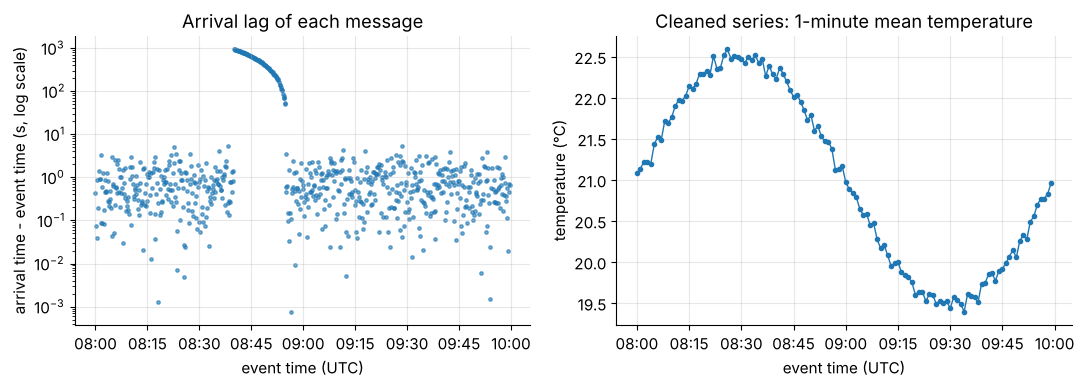

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lag_s = (messages["arrival_time"] - messages["event_time"]).dt.total_seconds()
axes[0].scatter(messages["event_time"], lag_s, s=6, alpha=0.6)
axes[0].set_yscale("log")
axes[0].set_title("Arrival lag of each message")
axes[0].set_xlabel("event time (UTC)")
axes[0].set_ylabel("arrival time - event time (s, log scale)")
axes[1].plot(per_minute.index, per_minute["mean"], marker=".", lw=1)
axes[1].set_title("Cleaned series: 1-minute mean temperature")
axes[1].set_xlabel("event time (UTC)")
axes[1].set_ylabel("temperature (°C)")
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

The left panel shows the burst: readings taken between 08:40 and 08:55 arrived up to about a quarter of
an hour late, after newer readings had already been ingested. If the pipeline had assumed "messages arrive in
order" it would have mixed up the series, so instead we **deduplicated on the natural key**
`(device_id, seq)`, **sorted by event time**, and only then aggregated. The remaining gaps are real
losses, so we report them rather than inventing values. (Interpolating is a modeling decision for later,
not an ingestion decision.) Section 3.7 returns to late data in streaming systems.

### 2.9 Sources by structure: structured, semi-structured, unstructured

The second way to classify a source is by **how organized its data is**:

| | Structured | Semi-structured | Unstructured |
|---|---|---|---|
| Shape | rows and columns with a fixed **schema** (names and types) | self-describing records: keys/tags with values, plus nesting and optional fields | no data model a computer can query directly |
| Examples | relational tables (PostgreSQL, MySQL, SQL Server), well-formed CSV, spreadsheets | JSON, JSON Lines, XML, YAML, HTML, Avro, `key=value` logs, e-mail headers | free text, PDFs, scanned documents, images, audio, video |
| Stored in | databases, warehouses, Parquet tables | document stores, the lake (JSON), or flattened into tables | object storage / the lake, as files ("blobs") |
| Queried with | SQL | JSON path expressions, flattening, then SQL | ML first: OCR, speech-to-text, NLP, computer vision turn it into structure |
| Ingestion focus | types, keys, incremental changes | flattening, schema drift, optional fields | storing the bytes safely **plus a structured metadata record** |

Two remarks. First, the categories describe a spectrum: a CSV file is structured only if every row
follows the same columns and types (Section 2.3 showed how often that fails). Second, unstructured data
almost never travels alone: a photo comes with EXIF metadata (camera, timestamp, GPS), a video comes
with a title, a duration and a language, a PDF with an author and page count. Ingesting unstructured
data mostly means storing the file untouched and writing a **metadata record** that describes it.
The YouTube and Unsplash pipeline of Section 5.7 does exactly that.

**Schema-on-write vs schema-on-read.** When does the schema get enforced?

- **Schema-on-write:** the schema is declared first, and every record is validated (and converted) *as
  it is written*. Records that do not fit are rejected. Databases and warehouses work this way.
- **Schema-on-read:** records are stored *as received*, and a schema is applied *when someone reads*
  them. Data lakes (especially their raw zone) work this way.

Let us see the difference on five raw payment events from a mobile app. Version 1 of the app sent the
amount as a dollar string, and version 2 switched to integer cents, nested the user object and, in one
case, sent the timestamp as Unix epoch seconds. One event is simply garbage.

In [30]:
RAW_EVENTS = [
    '{"event_id": "e1", "user": "u1", "amount": "19.99", "ts": "2026-03-02T09:00:00Z"}',
    '{"event_id": "e2", "user": "u2", "amount": "5.00", "ts": "2026-03-02T09:01:10Z"}',
    '{"event_id": "e3", "user": {"id": "u3", "tier": "gold"}, "amount_cents": 1250, "ts": "2026-03-02T09:02:00Z"}',
    '{"event_id": "e4", "user": {"id": "u1"}, "amount_cents": 300, "ts": 1772442180}',
    '{"event_id": "e5", "user": "u4", "amount": "abc", "ts": "2026-03-02T09:05:00Z"}',
]


def validate_v1(rec: dict) -> list[str]:
    """Schema-on-write contract (app v1): returns a list of violations (empty = valid)."""
    errors = []
    for field, typ in [("event_id", str), ("user", str), ("amount", str), ("ts", str)]:
        if not isinstance(rec.get(field), typ):
            errors.append(f"{field}: expected {typ.__name__}, got {type(rec.get(field)).__name__}")
    if isinstance(rec.get("amount"), str) and not re.fullmatch(r"\d+\.\d{2}", rec["amount"]):
        errors.append(f"amount: {rec['amount']!r} is not a decimal number")
    return errors


table, rejected = [], []
for line in RAW_EVENTS:
    rec = json.loads(line)
    problems = validate_v1(rec)
    (rejected if problems else table).append((rec["event_id"], problems))
print("schema-on-write accepted:", [eid for eid, _ in table])
for eid, problems in rejected:
    print(f"   rejected {eid}: {problems[0]}")
revenue_write = sum(float(json.loads(line)["amount"]) for line in RAW_EVENTS
                    if json.loads(line)["event_id"] in {eid for eid, _ in table})
print(f"revenue visible in the strict table: {revenue_write:.2f}")

schema-on-write accepted: ['e1', 'e2']
   rejected e3: user: expected str, got dict
   rejected e4: user: expected str, got dict
   rejected e5: amount: 'abc' is not a decimal number
revenue visible in the strict table: 24.99


The strict table is clean, but it silently lost every event from the new app version: the
producer changed, the contract did not, and three-fifths of today's events were rejected. In a lake we
would instead keep all five raw lines and apply a schema when reading, with a reader that knows about
both app versions:

In [31]:
def read_payment(rec: dict) -> dict:
    """Schema-on-read: normalize both app versions into one shape, or raise ValueError."""
    user = rec["user"]["id"] if isinstance(rec.get("user"), dict) else rec.get("user")
    if "amount_cents" in rec:
        cents = int(rec["amount_cents"])
    elif re.fullmatch(r"\d+\.\d{2}", str(rec.get("amount", ""))):
        cents = round(float(rec["amount"]) * 100)
    else:
        raise ValueError(f"unreadable amount {rec.get('amount')!r}")
    ts = rec["ts"]
    when = (datetime.fromtimestamp(ts, UTC) if isinstance(ts, (int, float))
            else datetime.fromisoformat(ts.replace("Z", "+00:00")))
    return {"event_id": rec["event_id"], "user": user, "amount_cents": cents, "ts": when}


parsed, unreadable = [], []
for line in RAW_EVENTS:
    try:
        parsed.append(read_payment(json.loads(line)))
    except ValueError as err:
        unreadable.append((json.loads(line)["event_id"], str(err)))
display(pd.DataFrame(parsed))
print("unreadable:", unreadable)
print(f"revenue with the schema-on-read reader: {sum(p['amount_cents'] for p in parsed) / 100:.2f}")

,event_id,user,amount_cents,ts
0,e1,u1,1999,2026-03-02 09:00:00+00:00
1,e2,u2,500,2026-03-02 09:01:10+00:00
2,e3,u3,1250,2026-03-02 09:02:00+00:00
3,e4,u1,300,2026-03-02 09:03:00+00:00


unreadable: [('e5', "unreadable amount 'abc'")]
revenue with the schema-on-read reader: 40.49


Schema-on-read recovered four of the five events (revenue 40.49 instead of 24.99), because the raw data
was still there when we learned about app version 2. But notice the price: *every* reader has to know
these rules. An analyst who writes a quick v1-only query against the same raw files gets 24.99, a
second analyst gets 40.49, and now two dashboards disagree. The standard compromise in a lake is
**both**: schema-on-read for the raw zone (keep everything), and an agreed, tested reader that
publishes typed, validated tables (schema-on-write) for everyone else (Section 4.2).

| | Schema-on-write | Schema-on-read |
|---|---|---|
| Schema enforced | when data is written | when data is read |
| Bad or unexpected records | rejected immediately (good: early alarm, bad: possible data loss) | stored, and problems surface later, at query time |
| Ingestion speed and flexibility | slower to add new sources, and schema changes need migrations | fast: land anything now, decide later |
| Query speed and consistency | fast and consistent: data is already typed and clean | every query parses and interprets, and readers may disagree |
| Typical home | OLTP databases, warehouses, curated (silver/gold) lake tables | raw/bronze zone of a lake, log and document stores |

**Schema drift** is what happens when a source's structure changes without notice: a column is added,
removed or renamed, or its type changes (`qty` arrives as `"3"` instead of `3`). Some changes are
**additive** (a new optional column: old readers keep working) and some are **breaking** (a removed or
renamed column, a narrower type). Detecting drift at ingestion time, recording it, and deciding what to
do is a core ingestion skill. Section 5.3 builds it into our file drop zone.

<details>
<summary><b>Quick check:</b> an IoT vendor sends JSON with a field <code>temp</code>, and after a firmware update the field is called <code>temperature_c</code>. Under schema-on-write, what happens? Under schema-on-read?</summary>

Schema-on-write: records missing the required `temp` are rejected (or `temp` is stored as null),
so readings are lost or blank from the update on, but at least the failure is visible immediately if
someone monitors rejection counts. Schema-on-read: the raw records are kept, so nothing is lost, but
every query that reads `temp` silently returns nulls for new data until someone updates the reader to
coalesce `temp` and `temperature_c`. In both cases you want drift detection that alerts on the change.
</details>

#### ✏️ Exercise 4: a schema-drift detector

A schema is given as a dictionary `{column_name: type_name}`. Write `detect_drift(expected, observed)`
returning a dictionary with three keys: `"added"` (columns only in `observed`), `"removed"` (columns only
in `expected`) and `"type_changed"` (a list of `(column, old_type, new_type)` tuples for columns in
both with different types). Every list must be **sorted** by column name. Names are case-sensitive.

In [32]:
# ✏️ Exercise 4: schema-drift detector
def detect_drift(expected: dict, observed: dict) -> dict:
    """Return {"added": [...], "removed": [...], "type_changed": [(col, old, new), ...]}, each sorted."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    base = {"store_id": "string", "sku": "string", "qty": "int64", "unit_price": "float64"}
    same = detect_drift(base, dict(base))
    assert same == {"added": [], "removed": [], "type_changed": []}, f"identical schemas: got {same}"
    obs = {"store_id": "string", "sku": "string", "quantity": "int64", "unit_price": "string", "currency": "string"}
    got = detect_drift(base, obs)
    assert got["added"] == ["currency", "quantity"], f"added: {got['added']}"
    assert got["removed"] == ["qty"], f"removed: {got['removed']}"
    assert got["type_changed"] == [("unit_price", "float64", "string")], f"type_changed: {got['type_changed']}"
    case = detect_drift({"Qty": "int64"}, {"qty": "int64"})
    assert case["added"] == ["qty"] and case["removed"] == ["Qty"], "column names are case-sensitive"
    assert detect_drift({}, {"a": "int64"})["added"] == ["a"], "everything is new when nothing was expected"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def detect_drift(expected, observed):
    added = sorted(set(observed) - set(expected))
    removed = sorted(set(expected) - set(observed))
    type_changed = [(c, expected[c], observed[c])
                    for c in sorted(set(expected) & set(observed))
                    if expected[c] != observed[c]]
    return {"added": added, "removed": removed, "type_changed": type_changed}
```
Set differences give the added and removed columns, and the intersection gives the columns whose types can
be compared. Note that a *rename* shows up as one removed plus one added column (`qty` → `quantity`).
Telling a rename apart from an unrelated add/remove needs a heuristic, which Section 5.3 adds.
</details>

## 3. Data ingestion: moving data reliably

Section 2 was about *where* data lives. This section is about *moving* it. Every ingestion design has
to answer the same handful of questions, and the rest of this section takes them one at a time:

| Question | Concepts | Section |
|---|---|---|
| Do we clean data before or after storing it? | ingestion vs ETL vs ELT | 3.1 |
| How often do we move data? | batch, micro-batch, streaming, and latency vs cost | 3.2 |
| Everything every time, or only what changed? | full vs incremental loads | 3.3 |
| How do we remember how far we got? | watermarks, state | 3.4 |
| How do we see changes, including deletes? | change data capture (CDC) | 3.5 |
| What happens when something crashes halfway? | at-least-once, exactly-once, idempotency, dedup keys | 3.6 |
| Which clock do we trust, and what about late data? | event time vs processing time, late data, backfills | 3.7 |

### 3.1 Ingestion vs ETL vs ELT

These three terms are often mixed up, so let us pin them down.

- **Data ingestion** is the *moving* part: extract records from a source and land them in central
  storage, **as faithfully as possible**. Typical ingestion-time work is deliberately light: convert the
  transport format (for example JSON pages into JSON Lines files), attach metadata (source, ingestion
  time, file checksum), and maybe mask secrets. The business meaning of the data is not changed.
- **ETL (Extract, Transform, Load)**: extract from the source, **transform** in a separate processing
  engine (clean, join, aggregate, apply business rules), then **load only the result** into the
  warehouse. This was the standard for decades, when warehouse storage and compute were expensive.
- **ELT (Extract, Load, Transform)**: extract, **load the raw data first** into the lake or warehouse,
  and transform it *there*, usually with SQL (tools such as dbt manage those SQL transformations). This
  became the default once cloud storage got cheap and cloud warehouses got fast.

```text
 ETL:  source --extract--> [ transform engine ] --load--> warehouse (only the transformed result)
 ELT:  source --extract--> lake / warehouse (raw copy kept) --transform with SQL--> curated tables
```

Ingestion is the "E" and the "L" of ELT. The single most important difference is **whether the raw data
survives**. The demo below makes that concrete. A source API keeps only the last 7 days of orders (very
common: many APIs, log systems and message brokers have a retention window). Two teams ingest it daily
for 10 days. The ETL team stores only the computed `revenue_usd` per order, and the ELT team stores the raw
records and computes revenue with a SQL query. On day 10, finance changes the definition: *revenue must
exclude sales tax*.

In [33]:
# Ten days of raw orders; gross amounts include a 13% sales tax.
r = np.random.default_rng(21)
order_days = pd.date_range("2026-03-01", periods=10, freq="D")
src_orders = pd.DataFrame({
    "order_id": [f"O{i:04d}" for i in range(1, 201)],
    "day": np.repeat(order_days, 20),
    "currency": r.choice(["CAD", "USD"], size=200, p=[0.6, 0.4]),
    "gross": r.uniform(10, 200, size=200).round(2),
})
src_orders["tax"] = (src_orders["gross"] * 0.13 / 1.13).round(2)
FX_SQL = "CASE currency WHEN 'CAD' THEN 0.73 ELSE 1.0 END"        # illustrative fixed exchange rate

con = duckdb.connect()                                          # an in-process SQL engine
con.register("raw_orders", src_orders)                          # the ELT lake: every raw record it received

# ETL: business rule v1 (revenue = gross amount in USD) applied *before* loading; raw fields are dropped.
etl_table = con.execute(f"SELECT order_id, day, ROUND(gross * {FX_SQL}, 2) AS revenue_usd FROM raw_orders").df()

# Day 10: the rule changes to v2 (revenue excludes tax). The ELT team simply re-runs SQL over the raw data.
REVENUE_V2 = f"SELECT day, ROUND(SUM((gross - tax) * {FX_SQL}), 2) AS revenue_usd FROM {{table}} GROUP BY day"
elt_v2 = con.execute(REVENUE_V2.format(table="raw_orders")).df().set_index("day")["revenue_usd"]

# The ETL team must re-extract gross and tax, but the source only keeps the last 7 days.
still_in_source = src_orders[src_orders["day"] >= order_days[-7]]         # March 4-10 only
con.register("re_extracted", still_in_source)
etl_v2 = con.execute(REVENUE_V2.format(table="re_extracted")).df().set_index("day")["revenue_usd"]

compare = pd.DataFrame({
    "v1 (stored by ETL)": etl_table.groupby("day")["revenue_usd"].sum().round(2),
    "v2 via ELT (from raw)": elt_v2,
    "v2 via ETL (re-extract)": etl_v2,
}).sort_index()
compare.index = compare.index.strftime("%b %d")
display(compare)
print("days the ETL warehouse can no longer recompute:", int(compare["v2 via ETL (re-extract)"].isna().sum()))

,v1 (stored by ETL),v2 via ELT (from raw),v2 via ETL (re-extract)
day,,,
Mar 01,1743.75,1543.14,NaN
Mar 02,1319.32,1167.54,NaN
Mar 03,1827.00,1616.80,NaN
Mar 04,1770.73,1567.02,1567.02
Mar 05,2155.66,1907.67,1907.67
Mar 06,1497.28,1325.03,1325.03
Mar 07,1731.35,1532.17,1532.17
Mar 08,1698.37,1502.99,1502.99
Mar 09,1739.06,1538.98,1538.98


days the ETL warehouse can no longer recompute: 3


The ELT team recomputed all ten days with one query. The ETL team can fix only the seven days that the
source still holds, and for March 1–3 the warehouse is stuck with the old definition forever (or must
report a blank), and any chart spanning March 1–10 now mixes two definitions of revenue. This is the
main reason modern platforms **land raw data first**: business rules change, bugs are found, and new
questions are asked of old data. Keeping the raw copy turns "we can never know" into "re-run the job".

| | ETL | ELT |
|---|---|---|
| Where the transformation runs | a separate engine *before* loading | inside the lake / warehouse *after* loading |
| What is stored | only the transformed result | raw data **and** transformed tables |
| Changing business logic | re-extract from the source (if it still has the data) | re-run the transformation over the raw data |
| Storage cost | lower | higher (raw copies), but object storage is cheap |
| Typical tools | Informatica, SSIS, custom Python/Spark jobs | Fivetran / Airbyte + dbt + BigQuery / Snowflake / Databricks |
| When it is still the right choice | data must be reduced or **de-identified before it may be stored** (privacy law, data residency), very constrained targets, or legacy systems | almost everything else |

In practice many teams do **EtLT**: a *small* "t" during ingestion (fix encodings, normalize timestamps
to UTC, mask or drop sensitive fields that must never be stored), then the big "T" later in SQL. The
web-log parser of Section 2.7 was exactly such a small "t": it converted time zones and truncated IP
addresses, but it did not decide what a "session" or a "conversion" is.

> **Key idea.** Ingestion moves data and preserves it. Transformation interprets it. Keep the two
> separate and keep the raw input, and every interpretation can be redone later.

### 3.2 Batch, micro-batch and streaming

The second design question is **how often** data moves.

- **Batch ingestion** collects data over a period and processes it in one go on a schedule: every
  night, every hour. It is simple, efficient (large sequential reads and writes), easy to retry and easy
  to re-run for past dates, and it is still the backbone of most analytics and ML training pipelines.
  The price is **latency**: data can be up to one full period old.
- **Micro-batch ingestion** runs the same batch logic on very short intervals, every few seconds or
  minutes. Spark Structured Streaming works this way by default. Latency drops to seconds or minutes, at
  the price of many more runs, each with its fixed overhead, and many small output files.
- **Streaming ingestion** processes each event as it arrives, continuously (Apache Flink, Kafka
  Streams, cloud services such as Amazon Kinesis or Google Cloud Dataflow). Latency is milliseconds to
  seconds, but the system must run 24/7 and must handle state, ordering, duplicates and late events
  while running (Sections 3.6 and 3.7).

**A simple latency model.** Let events arrive at random moments, let a batch job start every $T$
seconds, and let each run take $p$ seconds to make its data queryable. An event that arrives at a
random moment inside a cycle waits $U \sim \mathcal{U}(0, T)$ for the next run to start, then $p$ for that
run to finish. Adding the network delay $\delta$ from the source to the landing area, the end-to-end
latency $L$ and its average are

$$
L = \delta + U + p, \qquad \mathbb{E}[L] = \mathbb{E}[\delta] + \frac{T}{2} + p, \qquad L_{\max} \approx T + p .
$$

Halving the interval halves the average wait but doubles the number of runs. The simulation below
takes one hour of events (a Poisson process at 2 events per second) and pushes it through three
ingestion modes. "Latency" is measured from the moment an event happened until it is queryable in the
lake.

In [34]:
# One hour of events and three ways of ingesting them.
r = np.random.default_rng(8)
HORIZON, RATE = 3600.0, 2.0                                    # seconds simulated, events per second
n_events = r.poisson(RATE * HORIZON)
event_t = np.sort(r.uniform(0, HORIZON, n_events))             # when each event happened
arrive_t = event_t + r.exponential(0.3, n_events)              # when it reaches the landing area (network delay)


def ready_times_batch(arrive: np.ndarray, interval: float, job_seconds: float) -> np.ndarray:
    """Runs start at multiples of `interval`; a run picks up everything that arrived before it started
    and makes it queryable `job_seconds` later."""
    next_start = np.floor(arrive / interval) * interval + interval
    return next_start + job_seconds


MODES = {"batch (every 15 min, 60 s job)": (900.0, 60.0),
         "micro-batch (every 10 s, 2 s job)": (10.0, 2.0)}
ready = {name: ready_times_batch(arrive_t, T, p) for name, (T, p) in MODES.items()}
ready["streaming (per event, ~50 ms)"] = arrive_t + r.exponential(0.05, n_events)

rows = []
for name, t_ready in ready.items():
    lat = t_ready - event_t
    T, p = MODES.get(name, (None, None))
    rows.append({
        "mode": name,
        "mean (s)": lat.mean(), "median (s)": np.median(lat),
        "p95 (s)": np.quantile(lat, 0.95), "max (s)": lat.max(),
        "model mean (s)": 0.3 + T / 2 + p if T else 0.3 + 0.05,
        "runs per hour": HORIZON / T if T else n_events,
        "busy compute (s per hour)": HORIZON / T * p if T else HORIZON,
    })
latency_table = pd.DataFrame(rows).set_index("mode")
print(f"{n_events:,} events in one hour")
display(latency_table.round(2))

7,155 events in one hour


,mean (s),median (s),p95 (s),max (s),model mean (s),runs per hour,busy compute (s per hour)
mode,,,,,,,
"batch (every 15 min, 60 s job)",507.93,505.15,915.89,960.15,510.30,4.0,240.0
"micro-batch (every 10 s, 2 s job)",7.26,7.25,11.78,13.03,7.30,360.0,720.0
"streaming (per event, ~50 ms)",0.35,0.27,0.94,2.37,0.35,7155.0,3600.0


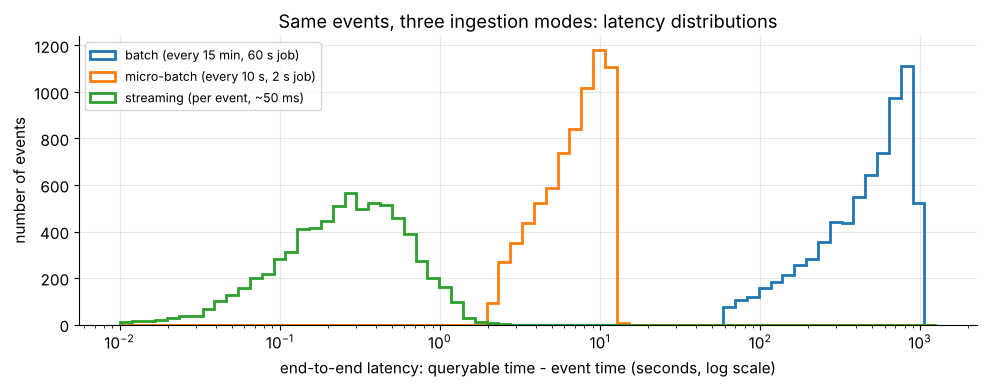

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-2, 3.1, 70)
for (name, t_ready), color in zip(ready.items(), ["C0", "C1", "C2"]):
    ax.hist(t_ready - event_t, bins=bins, histtype="step", lw=2, color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("end-to-end latency: queryable time - event time (seconds, log scale)")
ax.set_ylabel("number of events")
ax.set_title("Same events, three ingestion modes: latency distributions")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The simulated averages match the model closely: the 15-minute batch averages about
$0.3 + 450 + 60 \approx 510$ seconds (worst case about 16 minutes), the 10-second micro-batch about 7
seconds, and per-event streaming about a third of a second, dominated by the network delay. Note the
shapes: batch and micro-batch latencies are spread *uniformly* over a whole interval (on a logarithmic
axis a uniform spread looks like a rising ramp, because each bin is wider than the one to its left),
while streaming latency is concentrated around a few tenths of a second. The three distributions barely
touch: batch and micro-batch do not overlap at all, and only a handful of the slowest streaming events
(around 2 s) are as slow as the fastest micro-batch ones. The choice of mode changes latency by orders of
magnitude.

Now look at the cost columns. The batch job is busy for only 4 minutes per hour (4 runs of 60 s), the
compute can be switched off in between. The micro-batch runs 360 times per hour, and although each run
is short, the fixed per-run overhead (start-up, connections, writing a file and its metadata) is paid
360 times, and if every run writes one file, the lake receives 360 small files per hour (the small-files
problem of Section 4.5). The streaming consumer must be up for the whole hour, every hour, and a design
that wrote one file per event would create thousands of files per hour. That is why real streaming
pipelines buffer events in a broker or in memory and **flush files to the lake in micro-batches** anyway:
streaming gives low latency for *processing*, but object storage prefers large files.

**How short should the interval be?** Suppose each run has a fixed overhead cost $c$, events arrive at
rate $\lambda$ per second, and every second of waiting costs $\alpha$ per event (how much staleness
hurts the business). Per second of operation, the overhead costs $c/T$ and the waiting costs
$\alpha \lambda \cdot T/2$ (on average $\lambda$ events per second each wait $T/2$). The total

$$
J(T) = \frac{c}{T} + \frac{\alpha \lambda T}{2}
$$

is a sum of a term that falls with $T$ and a term that rises with $T$. By the AM–GM inequality,
$\frac{c}{T} + \frac{\alpha\lambda T}{2} \ge 2\sqrt{\frac{c}{T}\cdot\frac{\alpha\lambda T}{2}} = \sqrt{2 c\,\alpha\lambda}$,
with equality exactly when the two terms are equal, $\frac{c}{T} = \frac{\alpha\lambda T}{2}$, that is

$$
T^{*} = \sqrt{\frac{2c}{\alpha\lambda}} .
$$

(Setting $J'(T) = -c/T^2 + \alpha\lambda/2 = 0$ gives the same answer.) The square root has a practical
meaning: quadrupling the per-run overhead only doubles the best interval, and the more events you
receive, the more often it pays to run.

> **Olympiad tip.** "Minimize $a/x + bx$ for $x > 0$" appears everywhere: batch sizes, cache sizes,
> checkpoint intervals, the classic economic order quantity of inventory theory. The answer is always
> $x^* = \sqrt{a/b}$ with minimum $2\sqrt{ab}$, and AM–GM proves it in one line without calculus.

In [36]:
c_run, lam, alpha = 0.20, 2.0, 1e-5      # USD per run, events per second, USD per event-second of delay
T_star = math.sqrt(2 * c_run / (alpha * lam))
print(f"optimal interval T* = sqrt(2c / (alpha * lambda)) = {T_star:.0f} s (about {T_star / 60:.1f} min)")
for T in [10, 60, T_star, 900, 3600]:
    per_hour = 3600 * (c_run / T + alpha * lam * T / 2)
    print(f"  T = {T:6.0f} s -> overhead {3600 * c_run / T:7.2f} + staleness {3600 * alpha * lam * T / 2:6.2f}"
          f" = {per_hour:7.2f} USD per hour")

optimal interval T* = sqrt(2c / (alpha * lambda)) = 141 s (about 2.4 min)
  T =     10 s -> overhead   72.00 + staleness   0.36 =   72.36 USD per hour
  T =     60 s -> overhead   12.00 + staleness   2.16 =   14.16 USD per hour
  T =    141 s -> overhead    5.09 + staleness   5.09 =   10.18 USD per hour
  T =    900 s -> overhead    0.80 + staleness  32.40 =   33.20 USD per hour
  T =   3600 s -> overhead    0.20 + staleness 129.60 =  129.80 USD per hour


The two cost terms are equal at the optimum (about 5.09 USD each, about 10.18 USD per hour in total),
while a 10-second micro-batch wastes money on overhead and an hourly batch on staleness. Real decisions
have more terms (engineering effort, operational risk, the cost of an always-on cluster), but the
structure "overhead per run vs. cost of waiting" is the heart of the choice.

| | Batch | Micro-batch | Streaming |
|---|---|---|---|
| Unit of work | all data of a period (hour, day) | small batch every few seconds or minutes | each event (or tiny buffers) |
| Typical latency | minutes to a day | seconds to minutes | milliseconds to seconds |
| Throughput / efficiency | highest (large sequential I/O) | high | lower per event, but scales by partitions |
| Cost profile | compute only while running | frequent runs, fixed overhead per run | always-on cluster, state storage |
| Complexity | low: rerun a failed day | medium | high: state, ordering, late data, exactly-once |
| Failure handling | retry or backfill the whole run | retry the micro-batch from the last checkpoint | checkpoints plus replay from offsets |
| Typical tools | cron, Airflow, Dagster, plain Python, Spark | Spark Structured Streaming, scheduled loaders | Kafka + Flink, Kafka Streams, Kinesis, Dataflow |
| Typical uses | reports, ML training sets, archiving, reconciliation | near-real-time dashboards, feature refresh | fraud detection, alerting, live recommendations, IoT control |

> **Common pitfall.** Choosing streaming because it sounds modern. Ask "who acts on this data, and how
> fast?" If a human reads the dashboard once each morning, a nightly batch is cheaper, simpler and
> easier to repair. Choose streaming when a *machine* must react within seconds.

<details>
<summary><b>Quick check:</b> a daily batch job starts at 02:00 and needs 40 minutes. An event happens at 02:05. When is it queryable at the earliest, and what is its latency?</summary>

It missed the 02:00 run (that run only picks up what arrived before it started), so it is included in
the next day's run, which finishes at 02:40 the following day: a latency of 24 h 35 min, which is the
worst case $T + p$ minus 5 minutes. An event at 01:59 would have been queryable at 02:40 the same day
(41 minutes). Batch latency depends heavily on *when* within the cycle an event happens.
</details>

### 3.3 Full vs incremental loads

The third question is **how much** to move on each run.

- A **full load** (snapshot) copies the whole table every time: `SELECT * FROM customers`. It is simple
  and self-healing (each run replaces the copy, so deletions and past mistakes disappear), but its cost
  grows with the size of the table, not with the amount of change.
- An **incremental load** copies only what changed since the last run:
  `SELECT * FROM customers WHERE updated_at > :last_seen`. It is cheap and fast, but it needs a
  trustworthy **change marker** (an `updated_at` column, an ever-increasing id, or a change log) and some
  remembered **state** (how far the previous run got, Section 3.4). And it has a blind spot: a row that
  was **deleted** in the source does not show up in "rows changed since...", because it is not there
  any more.

The simulation below tracks a customer table of 50,000 rows for 30 days. Every day 500 customers sign
up, 1,000 existing rows are updated and 20 rows are deleted. Both strategies start with the same full
copy on day 0.

rows transferred in 31 runs: full = 1,773,200, incremental = 95,000 (19x fewer)
after 30 days the incremental copy holds 600 'ghost' rows that were deleted in the source; the full copy holds 0


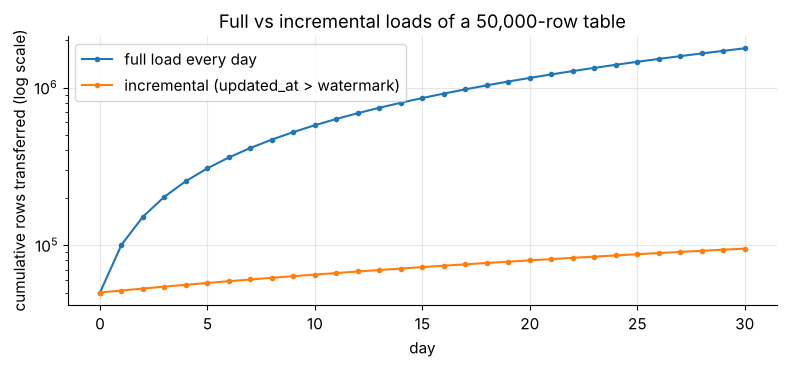

In [37]:
def simulate_loads(days=30, n0=50_000, inserts=500, updates=1_000, deletes=20, seed=4):
    """Return one row per day with the rows transferred by a full and an incremental load."""
    r = np.random.default_rng(seed)
    source = dict.fromkeys(range(n0), 0)            # row id -> day of its last change
    next_id = n0
    incremental_copy = set(source)                  # day 0: initial full copy for both strategies
    log = [{"day": 0, "source rows": n0, "full": n0, "incremental": n0, "ghost rows": 0}]
    for day in range(1, days + 1):
        ids = np.fromiter(source, dtype=np.int64)
        for gone in r.choice(ids, size=deletes, replace=False):
            del source[int(gone)]
        alive = np.fromiter(source, dtype=np.int64)
        for changed in r.choice(alive, size=updates, replace=False):
            source[int(changed)] = day
        for new in range(next_id, next_id + inserts):
            source[new] = day
        next_id += inserts
        changed_today = [i for i, d in source.items() if d == day]   # WHERE updated_at > watermark
        incremental_copy.update(changed_today)
        log.append({"day": day, "source rows": len(source), "full": len(source),
                    "incremental": len(changed_today),
                    "ghost rows": len(incremental_copy - source.keys())})
    return pd.DataFrame(log).set_index("day")


loads = simulate_loads()
totals = loads[["full", "incremental"]].sum()
print(f"rows transferred in 31 runs: full = {totals['full']:,}, incremental = {totals['incremental']:,} "
      f"({totals['full'] / totals['incremental']:.0f}x fewer)")
print(f"after 30 days the incremental copy holds {loads['ghost rows'].iloc[-1]} 'ghost' rows "
      f"that were deleted in the source; the full copy holds 0")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(loads.index, loads["full"].cumsum(), marker=".", label="full load every day")
ax.plot(loads.index, loads["incremental"].cumsum(), marker=".", label="incremental (updated_at > watermark)")
ax.set_yscale("log")
ax.set_xlabel("day")
ax.set_ylabel("cumulative rows transferred (log scale)")
ax.set_title("Full vs incremental loads of a 50,000-row table")
ax.legend()
plt.tight_layout()
plt.show()

After 30 days the full strategy has moved roughly 1.8 million rows to keep a copy of a table that
never had more than 65,000 rows, while the incremental strategy moved about 95,000, nineteen times
fewer. (At a billion rows the difference decides whether the job takes minutes or days.) But the
incremental copy has quietly accumulated **600 ghost rows**: customers who were deleted in the source
but still appear in the lake, and who will be counted in every "number of customers" report.

Real pipelines combine the strengths:

| Strategy | How changes are found | Sees deletes? | Load on the source | Typical use |
|---|---|---|---|---|
| Full snapshot | copy everything | yes (by comparing snapshots) | heavy | small tables, dimension tables, reconciliation |
| Incremental by timestamp | `updated_at > watermark` | no (unless rows are *soft-deleted*: flagged, not removed) | light | most API and database extracts |
| Incremental by increasing id | `id > last_id` | no, and misses updates too | light | append-only data: logs, events, payments |
| Change data capture | read the database's change log | **yes**, including every intermediate update | very light | large, busy OLTP tables (Section 3.5) |
| Hybrid | daily incremental + weekly full reconciliation | yes, with a delay | medium | a pragmatic default |

> **Common pitfall.** Trusting `updated_at` blindly. Some applications forget to set it on certain code
> paths (bulk updates, admin scripts), clocks differ between servers, and a long-running transaction can
> commit a row whose `updated_at` is *older* than rows you have already read. Section 3.4 shows how a
> small overlap window and deduplication protect against the last two problems.

### 3.4 Watermarks: remembering how far you got

An incremental job must remember, between runs, the position up to which it has already ingested.
That remembered position is called a **high-water mark**, or simply **watermark** (like the line a
flood leaves on a wall). In batch ingestion it is usually the largest change-marker value already
loaded, for example the largest `updated_at`:

```text
run k:    SELECT * FROM customers WHERE updated_at > :watermark ORDER BY updated_at LIMIT 1000
          ... write the rows to the lake ...
          watermark := largest updated_at among the rows just written      (persist it!)
```

Simple as it looks, there are two classic bugs. Both appear when you page through results with a
`LIMIT` and several rows share the same timestamp, which is common (bulk updates, timestamps rounded to
the second). The source table below has ten changed rows: three share 10:00:00 and four share 10:00:07.
We fetch pages of 3 rows.

In [38]:
CHANGES = [{"id": f"c{i:02d}", "updated_at": f"2026-03-02T10:00:{s:02d}Z"}
           for i, s in enumerate([0, 0, 0, 5, 7, 7, 7, 7, 9, 12], start=1)]


def query_changes(rows, op, watermark, limit):
    """Mimic `WHERE updated_at {op} :watermark ORDER BY updated_at, id LIMIT :limit`."""
    keep = [r for r in rows if watermark is None
            or (r["updated_at"] > watermark if op == ">" else r["updated_at"] >= watermark)]
    return sorted(keep, key=lambda r: (r["updated_at"], r["id"]))[:limit]


def extract_with_timestamp_watermark(rows, op, limit=3, max_requests=12):
    """Page through the changes using a timestamp-only watermark; return (ids received, requests made)."""
    watermark, received = None, []
    for request in range(1, max_requests + 1):
        page = query_changes(rows, op, watermark, limit)
        if not page:
            return received, request
        received += [r["id"] for r in page]
        watermark = page[-1]["updated_at"]
    return received, max_requests


for op in [">", ">="]:
    got, n_req = extract_with_timestamp_watermark(CHANGES, op)
    lost = sorted({r["id"] for r in CHANGES} - set(got))
    print(f"updated_at {op:2s} watermark: {n_req:2d} requests, {len(got):2d} rows received, "
          f"{len(set(got)):2d} distinct, lost: {lost}")

updated_at >  watermark:  4 requests,  8 rows received,  8 distinct, lost: ['c07', 'c08']
updated_at >= watermark: 12 requests, 36 rows received,  3 distinct, lost: ['c04', 'c05', 'c06', 'c07', 'c08', 'c09', 'c10']


- With the strict comparison `>`, the second page ends in the middle of the 10:00:07 group (c05 and
  c06 are on page 2, c07 and c08 are not). The watermark becomes 10:00:07, and the next request asks
  for rows *after* 10:00:07: **c07 and c08 are skipped forever**, silently.
- With `>=`, nothing is skipped, but the first page ends with three rows that all have 10:00:00, the
  watermark stays at 10:00:00, and every following request returns **the same three rows again**. The
  job never progresses (here it stopped only because of our safety limit of 12 requests). With fewer
  ties than the page size, `>=` "only" re-reads the boundary rows each run, which needs deduplication.

**The fix: a compound watermark.** Make the sort order *total* by adding a unique tie-breaker (the
primary key) and remember the pair $(u^*, k^*)$ = (`updated_at`, `id`) of the last row ingested. The next
page asks for rows whose pair is lexicographically larger:

$$
(u, k) > (u^*, k^*) \iff u > u^* \ \text{ or } \ (u = u^* \text{ and } k > k^*).
$$

In SQL this is `WHERE (updated_at, id) > (:u, :k) ORDER BY updated_at, id LIMIT :n` (row-value
comparisons work in PostgreSQL, MySQL and SQLite). It is the same idea as the cursor pagination of
Section 2.2: the cursor *is* a compound watermark.

**Late commits and the overlap window.** A second, subtler problem comes from transactions. A row's
`updated_at` is usually set when the transaction *starts* writing, but the row only becomes visible when
the transaction *commits*:

| wall clock | what happens |
|---|---|
| 10:02 | a long transaction sets `updated_at = 10:02` on row X (not committed yet) |
| 10:04 | row Y is updated and committed with `updated_at = 10:04` |
| 10:05 | our run reads everything visible, sees Y, sets the watermark to 10:04 |
| 10:07 | the transaction commits, and X becomes visible with `updated_at = 10:02` |
| 10:10 | our next run asks for `updated_at > 10:04` and **misses X forever** |

The standard defense is an **overlap (lookback) window**: query from `watermark - 10 minutes` instead of
`watermark`, and deduplicate by primary key, keeping the newest version. Rows inside the window are
read twice, which is harmless once the write is idempotent (Section 3.6), and rows committed late (by
less than the window) are caught. Log-based change data capture (next section) avoids the problem
entirely, because it delivers each transaction's changes when that transaction *commits*, in commit order
(PostgreSQL's logical decoding regroups the interleaved write-ahead log by transaction and emits each one
at its commit, and MySQL writes its binlog at commit time), so a late commit arrives late but is never
skipped.

**Persisting the state.** The watermark must survive restarts, so it is written to a small state file
(or a table) **after** the data has been written safely. If the job crashes between the two steps, the
next run re-reads some rows (a duplicate) instead of skipping them (a loss). Section 3.6 explains why
that is the right order. The state file itself must never be left half-written, so we write it to a
temporary file and then atomically replace the old one. We will reuse this helper in Section 5.

In [39]:
def write_json_atomic(path, obj) -> None:
    """Write JSON so that readers see either the complete old file or the complete new one, never half."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, sort_keys=True, default=str), encoding="utf-8")
    os.replace(tmp, path)          # an atomic replace on the same file system (POSIX and Windows)


def read_json(path, default=None):
    """Read a JSON file, or return `default` if it does not exist yet (the very first run)."""
    path = Path(path)
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else default


state_path = PLAY / "state" / "customers_extract.json"
print("state before the first run:", read_json(state_path, default={"watermark": None}))
write_json_atomic(state_path, {"watermark": ["2026-03-02T10:00:12Z", "c10"], "rows_loaded": 10})
print("state after the run      :", read_json(state_path))

state before the first run: {'watermark': None}
state after the run      : {'rows_loaded': 10, 'watermark': ['2026-03-02T10:00:12Z', 'c10']}


#### ✏️ Exercise 5: a compound-watermark page reader

Implement `next_page(rows, watermark, limit)` for the compound watermark described above. `rows` is a
list of dictionaries with keys `"id"` and `"updated_at"` (ISO-8601 UTC strings in one fixed format, so
string comparison equals time comparison). `watermark` is `None` (nothing ingested yet) or a tuple
`(updated_at, id)` of the last row already ingested. Return `(page, new_watermark)`: the first `limit`
rows whose `(updated_at, id)` is strictly greater than the watermark, in `(updated_at, id)` order, and
the watermark after ingesting them. If the page is empty, the watermark must not change.

In [40]:
# ✏️ Exercise 5: compound-watermark page reader
def next_page(rows, watermark, limit):
    """Return (page, new_watermark) using the lexicographic order of (updated_at, id)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    for limit in [1, 2, 3, 4, 10]:
        wm, got = None, []
        for _ in range(20):                                  # far more requests than ever needed
            page, wm = next_page(CHANGES, wm, limit)
            if not page:
                break
            got += [r["id"] for r in page]
        assert got == [f"c{i:02d}" for i in range(1, 11)], f"limit={limit}: received {got}"
        assert wm == ("2026-03-02T10:00:12Z", "c10"), f"limit={limit}: final watermark {wm}"
    page, wm = next_page(CHANGES, ("2026-03-02T10:00:07Z", "c06"), 2)
    assert [r["id"] for r in page] == ["c07", "c08"], "rows tied with the watermark's timestamp must not be lost"
    assert wm == ("2026-03-02T10:00:07Z", "c08"), f"got watermark {wm}"
    assert next_page([], ("x", "y"), 5) == ([], ("x", "y")), "an empty page must keep the old watermark"
    shuffled = list(reversed(CHANGES))
    assert [r["id"] for r in next_page(shuffled, None, 3)[0]] == ["c01", "c02", "c03"], "sort the rows yourself"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def next_page(rows, watermark, limit):
    key = lambda r: (r["updated_at"], r["id"])
    newer = [r for r in rows if watermark is None or key(r) > tuple(watermark)]
    page = sorted(newer, key=key)[:limit]
    return page, (key(page[-1]) if page else watermark)
```
Python compares tuples lexicographically, which is exactly the compound order we want: first by
`updated_at`, and by `id` only when the timestamps are equal. Because the order is total (ids are
unique), no row can be skipped or returned twice, whatever the page size.
</details>

### 3.5 Change data capture (CDC)

**Change data capture** means turning every insert, update and delete in a source database into a
record that downstream systems can consume, ideally in the order the changes were committed. There are
two main families.

- **Query-based CDC** (polling) is the incremental load of Sections 3.3–3.4: every few minutes, run
  `SELECT ... WHERE updated_at > :watermark`. It works with any database and needs no special
  permissions, but it adds query load, needs a reliable `updated_at` column (with an index), **cannot see
  hard deletes**, and only sees the *latest* version of a row at polling time: two updates between polls
  look like one.
- **Log-based CDC** reads the database's own **transaction log**: the write-ahead log (WAL) of PostgreSQL
  through logical decoding, the binlog of MySQL, the change tables of SQL Server, MongoDB's change
  streams. Every committed change is in that log already (the database needs it for crash recovery and
  replication), so CDC adds almost no load, sees **every** insert, update and delete, in commit order,
  with seconds of latency. The usual tool is **Debezium**, which reads the log and publishes one event per
  change into a Kafka topic. The cost: database-level configuration and permissions, and care with log
  retention (if the consumer stops, the database must keep its log around until it comes back).

Two more approaches exist: **trigger-based** CDC (database triggers copy each change into an audit
table, which slows down every write) and **snapshot diffing** (compare two full snapshots, which works
anywhere but is expensive).

Let us compare polling and log reading on a tiny `orders` table that, like a real database, appends
every change to a log with an increasing **log sequence number** (LSN).

In [41]:
class LoggedTable:
    """A dictionary-backed table that appends every change to a write-ahead log, like a real database."""

    def __init__(self):
        self.rows, self.wal = {}, []

    def _log(self, op, key, before, after, ts):
        self.wal.append({"lsn": len(self.wal) + 1, "op": op, "key": key, "before": before, "after": after, "ts": ts})

    def upsert(self, key, ts, **fields):
        before = self.rows.get(key)
        after = {**(before or {}), **fields, "updated_at": ts}
        self.rows[key] = after
        self._log("c" if before is None else "u", key, before, after, ts)   # c = create, u = update

    def delete(self, key, ts):
        self._log("d", key, self.rows.pop(key), None, ts)                   # d = delete


orders = LoggedTable()
poll_replica, poll_watermark, poll_seen = {}, 0, 0
log_replica, last_lsn = {}, 0
script = [("upsert", "A", 1, "new"), ("upsert", "B", 2, "new"), ("poll", None, None, None),
          ("upsert", "A", 3, "paid"), ("upsert", "A", 4, "shipped"), ("upsert", "C", 5, "new"),
          ("delete", "B", 6, None), ("poll", None, None, None), ("upsert", "C", 7, "paid"),
          ("poll", None, None, None)]
for action, key, minute, status in script:
    if action == "upsert":
        orders.upsert(key, minute, status=status)
    elif action == "delete":
        orders.delete(key, minute)
    else:
        # Query-based CDC: SELECT * WHERE updated_at > watermark
        changed = {k: v for k, v in orders.rows.items() if v["updated_at"] > poll_watermark}
        poll_replica.update(changed)
        poll_seen += len(changed)
        poll_watermark = max([poll_watermark] + [v["updated_at"] for v in changed.values()])
        # Log-based CDC: read every log entry after the last LSN and apply it in order
        for entry in orders.wal[last_lsn:]:
            if entry["op"] == "d":
                log_replica.pop(entry["key"], None)
            else:
                log_replica[entry["key"]] = entry["after"]
            last_lsn = entry["lsn"]

print("the change log (WAL):")
for e in orders.wal:
    print(f"  lsn={e['lsn']} op={e['op']} key={e['key']} 10:{e['ts']:02d}  "
          f"{(e['before'] or {}).get('status', '-'):>7s} -> {(e['after'] or {}).get('status', '-')}")
fmt = lambda rep: {k: v["status"] for k, v in sorted(rep.items())}
print("source table now     :", fmt(orders.rows))
print("query-based replica  :", fmt(poll_replica), f"(saw {poll_seen} row versions in 3 polls)")
print("log-based replica    :", fmt(log_replica), f"(applied {len(orders.wal)} change events)")
print("a Debezium-style change event:", json.dumps({
    "op": "u", "before": {"id": "A", "status": "paid"}, "after": {"id": "A", "status": "shipped"},
    "source": {"lsn": 4, "ts_ms": 1772445840000, "table": "orders"}}))

the change log (WAL):
  lsn=1 op=c key=A 10:01        - -> new
  lsn=2 op=c key=B 10:02        - -> new
  lsn=3 op=u key=A 10:03      new -> paid
  lsn=4 op=u key=A 10:04     paid -> shipped
  lsn=5 op=c key=C 10:05        - -> new
  lsn=6 op=d key=B 10:06      new -> -
  lsn=7 op=u key=C 10:07      new -> paid
source table now     : {'A': 'shipped', 'C': 'paid'}
query-based replica  : {'A': 'shipped', 'B': 'new', 'C': 'paid'} (saw 5 row versions in 3 polls)
log-based replica    : {'A': 'shipped', 'C': 'paid'} (applied 7 change events)
a Debezium-style change event: {"op": "u", "before": {"id": "A", "status": "paid"}, "after": {"id": "A", "status": "shipped"}, "source": {"lsn": 4, "ts_ms": 1772445840000, "table": "orders"}}


Polling saw 5 row versions. The log holds 7 changes. Two changes were invisible to polling:

1. Order A went `new → paid → shipped` between two polls, and polling only saw `shipped`. If you wanted to
   measure "time from payment to shipping", the information is gone.
2. Order B was **deleted**. The query-based replica still contains it (a ghost row, as in Section 3.3),
   while the log-based replica matches the source exactly.

| | Query-based (polling) | Log-based | Trigger-based | Snapshot diff |
|---|---|---|---|---|
| Sees deletes | no (only soft deletes) | yes | yes | yes |
| Sees every intermediate change | no | yes, in commit order | yes | no |
| Load on the source | queries every poll | very low (reads the log) | extra work on every write | full scans |
| Latency | the polling interval | seconds | seconds | the snapshot interval |
| Setup | easy, any database | database configuration and permissions, a tool such as Debezium | triggers on every table | easy, expensive |

> **Key idea.** A CDC stream turns a mutable table into an immutable log of facts ("A became paid at
> 10:03"). Replaying that log rebuilds the table at any point in time, and that is exactly how the lake
> table formats of Section 4.7 work too.

<details>
<summary><b>Quick check:</b> why can't query-based CDC see a deleted row, and what is the "soft delete" workaround?</summary>

Polling asks the *current* table which rows changed, and a hard-deleted row is no longer in the table, so
no query can return it. With **soft deletes** the application never removes rows: it sets a column such
as `deleted_at` (which also bumps `updated_at`), so the next poll returns the row with its deletion flag
and the lake can mark it deleted. The cost: every query of the application must now filter out deleted
rows.
</details>

### 3.6 Delivery guarantees, idempotency and deduplication keys

Crashes are not exceptional in data pipelines. They are scheduled for (machines restart, networks
drop, deployments kill processes). What matters is what a crash does to the *result*. Every consumer
does two things per batch: it **processes** the batch (writes it to the sink) and it **commits** its
progress (an offset in Kafka, a watermark in a state file). The order of the two decides the guarantee:

| Guarantee | Order | After a crash between the two steps | Result |
|---|---|---|---|
| **at-most-once** | commit, then process | the batch is never processed | events can be **lost**, never duplicated |
| **at-least-once** | process, then commit | the batch is processed again | events are never lost, but can be **duplicated** |
| **exactly-once** | process and commit *atomically*, or at-least-once + an idempotent sink | the batch's effect appears once | each event affects the result exactly once |

The simulation below streams 1,000 payment events through a consumer that reads batches of 50 and
crashes in the middle of 15% of the batches (after writing a random part of the batch). We try both
commit orders and two kinds of sink: a plain **append** and a sink that **deduplicates on `event_id`**.

In [42]:
def make_payments(n=1_000, seed=12):
    r = np.random.default_rng(seed)
    return [{"event_id": f"pay-{i:05d}", "amount_cents": int(r.integers(100, 10_000))} for i in range(n)]


def consume(events, commit, crash_prob=0.15, batch_size=50, seed=0):
    """Consume `events` in batches; a crash can interrupt a batch after a random number of writes.

    commit="before": commit the offset, then write  (at-most-once)
    commit="after" : write, then commit the offset  (at-least-once)
    Returns the list of records the sink received, in order.
    """
    r = np.random.default_rng(seed)
    offset, written = 0, []
    while offset < len(events):
        batch = events[offset: offset + batch_size]
        if commit == "before":
            offset += len(batch)
        if r.random() < crash_prob:                              # crash in the middle of the batch
            written.extend(batch[: int(r.integers(0, len(batch)))])
            continue                                             # restart from the committed offset
        written.extend(batch)
        if commit == "after":
            offset += len(batch)
    return written


payments = make_payments()
true_total = sum(p["amount_cents"] for p in payments)
rows = []
for commit, guarantee in [("before", "at-most-once"), ("after", "at-least-once")]:
    written = consume(payments, commit)
    deduped = {p["event_id"]: p for p in written}                # an upsert keyed by event_id
    for sink, records in [("append", written), ("dedup on event_id", list(deduped.values()))]:
        total = sum(p["amount_cents"] for p in records)
        rows.append({"delivery": guarantee, "sink": sink, "rows in sink": len(records),
                     "distinct events": len({p["event_id"] for p in records}),
                     "missing events": len(payments) - len({p["event_id"] for p in written}),
                     "revenue error": f"{(total - true_total) / true_total:+.1%}"})
display(pd.DataFrame(rows))

,delivery,sink,rows in sink,distinct events,missing events,revenue error
0,at-most-once,append,827,827,173,-18.8%
1,at-most-once,dedup on event_id,827,827,173,-18.8%
2,at-least-once,append,1077,1000,0,+7.8%
3,at-least-once,dedup on event_id,1000,1000,0,+0.0%


Read the table row by row:

- **At-most-once** never duplicates, but every crash throws away the unwritten rest of a batch: 173 of
  the 1,000 payments are missing and revenue is understated by almost 19%. Deduplication cannot bring
  back lost data.
- **At-least-once with an append sink** loses nothing, but each crash re-writes the beginning of a batch:
  77 duplicate rows, and revenue is *overstated* by almost 8%.
- **At-least-once with a deduplicating sink** is exact: every event is present once, and revenue is
  right to the cent.

That last combination is how most real pipelines achieve "exactly-once": not by making delivery
perfect (over an unreliable network that is impossible in general), but by making **duplicates
harmless**. People sometimes call this *effectively-once*. The other route is transactional: some
systems commit the output and the input offsets in one atomic transaction (Kafka transactions, Flink's
two-phase-commit sinks), which needs a sink that supports transactions.

**Idempotency** is the property that makes duplicates harmless. An operation $f$ is idempotent if
applying it twice has the same effect as applying it once:

$$
f(f(S)) = f(S) \quad \text{for every state } S .
$$

| Operation | Idempotent? | Why |
|---|---|---|
| `balance = 100` | yes | sets a value, and repeating sets the same value |
| `balance = balance + 10` | **no** | every repetition adds 10 more |
| `INSERT INTO payments VALUES (...)` | **no** | each repetition adds a row |
| upsert / `MERGE` by primary key | yes | the second write replaces the first with the same content |
| overwrite the partition `dt=2026-03-02` with that day's data | yes | the folder ends up identical |
| write a file named by a random UUID | **no** | each run adds a new file |
| write a file whose name is derived from the run's logical date or content | yes | a rerun replaces the same file |
| HTTP `GET`, `PUT`, `DELETE` | yes (by the HTTP specification) | they describe a target state |
| HTTP `POST` | not in general | unless the server honors an idempotency key |

**Choosing a deduplication key.** Deduplication needs a key that identifies "the same event":

1. A **producer-assigned event id** (a UUID created once, when the event is born) is ideal: retries carry
   the same id.
2. A **natural business key**: `order_id`, or `(device_id, seq)` for the sensor of Section 2.8. For
   records that change over time, the key is the entity and you keep the **latest version** (by
   `updated_at` or by a version number).
3. A **content hash** (for example SHA-256 of the canonical JSON) when nothing else exists. Beware: two
   genuinely different events with identical content (two identical coffees bought in the same second)
   collapse into one.

Streaming systems cannot remember every id forever, so they deduplicate inside a **window** (say, ids
seen in the last 24 hours). A duplicate that arrives later than that slips through, and a periodic batch
deduplication in the lake catches it.

#### ✏️ Exercise 6: an idempotent "keep the latest version" merge

Write `merge_latest(existing, incoming, key="id", version="updated_at")`. Both inputs are lists of
dictionaries. Return a **new** list with exactly one record per key, sorted by key: for each key, the
record with the largest `version`. On a version tie the record from `incoming` wins (and, inside
`incoming`, the later one). Do not modify the input lists. This is the merge every incremental load and
every CDC replica performs, and it is idempotent: merging the same batch twice changes nothing.

In [43]:
# ✏️ Exercise 6: idempotent keep-latest merge
def merge_latest(existing, incoming, key="id", version="updated_at"):
    """Return one record per key (the latest version; ties go to incoming), sorted by key."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    existing = [{"id": "a", "updated_at": 1, "v": "a1"}, {"id": "b", "updated_at": 5, "v": "b5"}]
    incoming = [{"id": "b", "updated_at": 3, "v": "b3"},          # older than what we have: ignore
                {"id": "c", "updated_at": 2, "v": "c2"},          # new key: add
                {"id": "a", "updated_at": 4, "v": "a4"},          # newer: replace
                {"id": "c", "updated_at": 7, "v": "c7"}]          # a newer duplicate inside the batch
    snapshot = [dict(r) for r in existing], [dict(r) for r in incoming]
    once = merge_latest(existing, incoming)
    assert [r["v"] for r in once] == ["a4", "b5", "c7"], f"got {[r['v'] for r in once]}"
    assert (existing, incoming) == snapshot, "the input lists must not be modified"
    assert merge_latest(once, incoming) == once, "merging the same batch again must change nothing"
    tie = merge_latest([{"id": "x", "updated_at": 1, "v": "old"}], [{"id": "x", "updated_at": 1, "v": "new"}])
    assert tie == [{"id": "x", "updated_at": 1, "v": "new"}], f"on a tie the incoming record wins, got {tie}"
    b1 = [{"id": "k", "updated_at": 2, "v": "k2"}]
    b2 = [{"id": "k", "updated_at": 9, "v": "k9"}, {"id": "m", "updated_at": 1, "v": "m1"}]
    assert merge_latest(merge_latest([], b1), b2) == merge_latest(merge_latest([], b2), b1), \
        "with distinct versions, the arrival order of batches must not matter"
    custom = merge_latest([], [{"sku": 2, "rev": 1}, {"sku": 1, "rev": 3}], key="sku", version="rev")
    assert [r["sku"] for r in custom] == [1, 2], "use the key/version arguments and sort by key"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def merge_latest(existing, incoming, key="id", version="updated_at"):
    best = {}
    for rec in list(existing) + list(incoming):          # incoming last, so it wins ties
        k = rec[key]
        if k not in best or rec[version] >= best[k][version]:
            best[k] = dict(rec)                          # copy: never alias the caller's records
    return [best[k] for k in sorted(best)]
```
Scanning `existing` first and using `>=` makes later records win ties. The result depends only on the
set of (key, version) pairs seen, which is why merging a batch twice, or two batches in either order,
gives the same table.
</details>

### 3.7 Time: event time, processing time, late data and backfills

Every record has (at least) two timestamps:

- **Event time**: when the thing happened in the real world (the sensor reading, the click, the payment).
- **Processing time** (or ingestion time): when our pipeline saw it.

They differ by network delays, retries, buffering on devices, batch schedules and wrong clocks. In
Section 2.8 a sensor reading arrived up to a quarter of an hour after it was taken. Analyses almost
always want **event time** ("sales on March 2"), but a pipeline only ever *observes* processing time.
Data whose event time is older than other data we have already processed is **late** (or
**out-of-order**) data.

**Late data in batch pipelines.** If the lake is partitioned by *ingestion date*, late data is simply in
a later folder. Nothing is rewritten, but a query for "events of March 2" must scan several folders. If
it is partitioned by *event date*, a late record must be written into an old partition, so that
partition changes after it was "done", and every result computed from it is stale. Section 4.3 discusses
the layout choice.

**Late data in streaming pipelines: watermarks.** A streaming job that counts readings per minute of
event time must decide when a minute is *complete*. It cannot know whether more readings for 08:41 are
still on their way, so it tracks a **streaming watermark**, an estimate of event-time progress:

$$
W = \max(\text{event times seen so far}) - L ,
$$

where $L$ is the **allowed lateness**. (Terminology varies: Spark calls $L$ the watermark's *delay
threshold* and Flink calls it the *bounded out-of-orderness*, while in Flink and Apache Beam "allowed
lateness" names an extra grace period *after* the watermark has passed a window's end, 0 by default.)
The watermark claims "no event older than $W$ should arrive any more". When $W$ passes the end of a
window, the window's result is emitted as final, and a record that shows up later for an already-final
window is *late* and is dropped (or diverted to a side table). (This
"streaming watermark" is a cousin of the batch watermark of Section 3.4: both mark how far we have got.)
The choice of $L$ is a trade-off between **completeness** and **latency**. Let us measure it on the
sensor messages of Section 2.8, processed in arrival order.

In [44]:
sensor_msgs, _ = simulate_sensor()                       # same seed: the messages of Section 2.8
by_arrival = sensor_msgs.sort_values("arrival_time", ignore_index=True)
t_ref = by_arrival["event_time"].min()
ev_s = (by_arrival["event_time"] - t_ref).dt.total_seconds().to_numpy()      # event time, seconds
ar_s = (by_arrival["arrival_time"] - t_ref).dt.total_seconds().to_numpy()    # arrival time, seconds


def stream_minute_windows(ev_s, ar_s, lateness, width=60.0):
    """Count readings per event-time minute with watermark W = max(event time seen) - lateness.

    Returns (number of messages dropped as late, median seconds from a window's end until it is final).
    """
    max_seen = np.maximum.accumulate(ev_s)               # max event time seen after each arrival
    wm_before = np.concatenate([[-np.inf], max_seen[:-1] - lateness])
    window_end = (np.floor(ev_s / width) + 1) * width
    dropped = int((window_end <= wm_before).sum())       # the window was already final on arrival
    ends = np.arange(width, ev_s.max(), width)           # every complete minute window
    first = np.searchsorted(max_seen - lateness, ends, side="left")   # arrival that made W >= end
    ok = first < len(ar_s)
    delay = ar_s[first[ok]] - ends[ok]
    return dropped, float(np.median(delay))


lateness_grid = [0, 10, 60, 300, 600, 900, 1200]
results = pd.DataFrame([dict(zip(["dropped", "median delay (s)"], stream_minute_windows(ev_s, ar_s, L)),
                             allowed_lateness_s=L) for L in lateness_grid]).set_index("allowed_lateness_s")
results["dropped (%)"] = (100 * results["dropped"] / len(ev_s)).round(1)
results["median delay (s)"] = results["median delay (s)"].round(1)
display(results)

,dropped,median delay (s),dropped (%)
allowed_lateness_s,,,
0,93,0.6,12.9
10,93,10.8,12.9
60,86,60.6,12.0
300,62,300.6,8.6
600,32,600.6,4.5
900,0,900.6,0.0
1200,0,1200.6,0.0


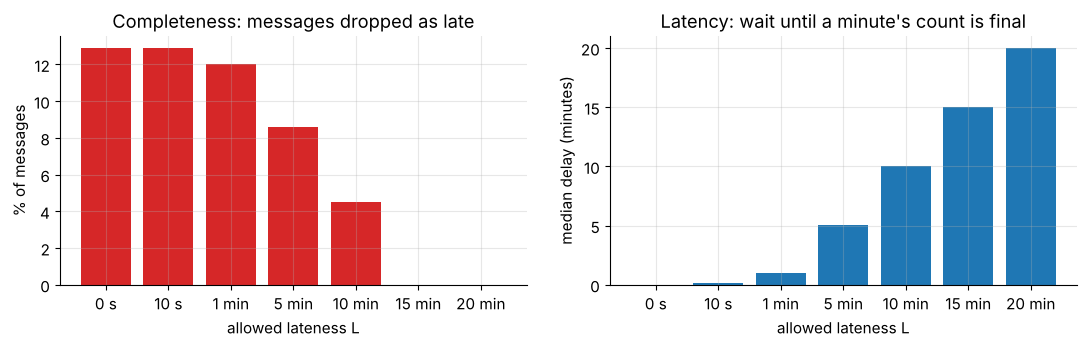

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labels = [f"{L // 60} min" if L >= 60 else f"{L} s" for L in lateness_grid]
axes[0].bar(labels, results["dropped (%)"], color="C3")
axes[0].set_title("Completeness: messages dropped as late")
axes[0].set_ylabel("% of messages")
axes[1].bar(labels, results["median delay (s)"] / 60, color="C0")
axes[1].set_title("Latency: wait until a minute's count is final")
axes[1].set_ylabel("median delay (minutes)")
for ax in axes:
    ax.set_xlabel("allowed lateness L")
plt.tight_layout()
plt.show()

With no allowed lateness, results are final almost immediately, but 93 messages (about one in eight)
are dropped: exactly the messages buffered during the 15-minute network outage (90 readings plus 3
duplicate copies). Ordinary network jitter never crossed a minute boundary late enough to matter here. Allowing 15 minutes of lateness keeps every message, but every count is
delayed by roughly 15 minutes. There is no free lunch: you trade **latency for completeness**. Real
systems soften the trade-off in three ways:

1. **Early and late firings:** emit a provisional result immediately, then emit corrections when late
   data arrives (the consumer must handle updates).
2. **Side outputs:** send late records to a "late" table instead of dropping them, and **monitor** how
   many there are: a sudden rise reveals an upstream problem.
3. **Batch correction:** a nightly batch job recomputes yesterday from the complete raw data in the lake,
   replacing the streaming results. This is the pragmatic reason to keep raw data even in streaming
   architectures.

**Backfills.** A **backfill** re-runs a pipeline for past logical dates: to load history when a new
source is added, or to repair results after fixing a bug. Backfills are only safe if every run is

- **parameterized by its logical date** instead of reading the clock. A job that computes
  `day = date.today() - timedelta(days=1)` cannot be asked to redo March 1.
  A job `run(logical_date)` can.
- **deterministic**: the same inputs (the raw data in the lake) give the same output.
- **idempotent**: re-running a date *replaces* that date's output instead of adding to it.
- **gentle with sources**: throttled, because a backfill of 365 days can be 365 times the normal load.

Here is a daily job written both ways, backfilled twice over the ten days of orders from Section 3.1:

In [46]:
def daily_orders_job(logical_date: date, out_root: Path, mode: str) -> None:
    """Process exactly one logical date. mode="overwrite" replaces that day's partition (idempotent);
    mode="append" adds one more file per run (not idempotent)."""
    rows = src_orders[src_orders["day"].dt.date == logical_date]
    part = out_root / f"order_date={logical_date.isoformat()}"
    if mode == "overwrite":
        tmp = part.with_name(part.name + ".tmp")
        shutil.rmtree(tmp, ignore_errors=True)
        tmp.mkdir(parents=True)
        rows.to_csv(tmp / "part-0000.csv", index=False)          # write the complete new version aside
        shutil.rmtree(part, ignore_errors=True)
        tmp.rename(part)                                         # then swap it in
    else:
        part.mkdir(parents=True, exist_ok=True)
        rows.to_csv(part / f"part-{len(list(part.glob('*.csv'))):04d}.csv", index=False)


def backfill(start: date, end: date, out_root: Path, mode: str) -> None:
    day = start
    while day <= end:
        daily_orders_job(day, out_root, mode)
        day += timedelta(days=1)


def folder_fingerprint(root: Path) -> str:
    """SHA-256 over every file's relative path and bytes: equal fingerprints = identical folders."""
    h = hashlib.sha256()
    for f in sorted(p for p in Path(root).rglob("*") if p.is_file()):
        h.update(f.relative_to(root).as_posix().encode() + b"\0" + f.read_bytes())
    return h.hexdigest()[:16]


for mode in ["overwrite", "append"]:
    out = PLAY / f"backfill_{mode}"
    for attempt in [1, 2]:
        backfill(date(2026, 3, 1), date(2026, 3, 10), out, mode)
        n_rows = sum(len(pd.read_csv(f)) for f in out.rglob("*.csv"))
        print(f"{mode:9s} backfill #{attempt}: {n_rows} rows in the output, fingerprint {folder_fingerprint(out)}")

overwrite backfill #1: 200 rows in the output, fingerprint bb08a66c9d04d7b7
overwrite backfill #2: 200 rows in the output, fingerprint bb08a66c9d04d7b7
append    backfill #1: 200 rows in the output, fingerprint bb08a66c9d04d7b7


append    backfill #2: 400 rows in the output, fingerprint f66fdbc7f556aa2d


The overwrite version produces a byte-identical folder no matter how often it runs: 200 orders, same
fingerprint. The append version doubles the data on the second backfill, which is the classic way a
"harmless re-run" corrupts a lake. (One honest caveat: between `rmtree` and `rename` there is a brief
moment when the partition does not exist, so a reader could see a day with no orders. On object storage
the table formats of Section 4.7 remove that gap with atomic commits.)

> **Common pitfall.** Mixing the run date and the logical date. A daily job that runs at 01:00 on March 3
> usually processes March 2. Name things after the **logical date** (`order_date=2026-03-02`), record the
> run time separately as metadata, and let the scheduler pass the date in.

<details>
<summary><b>Quick check:</b> your nightly job writes <code>dt=&lt;today&gt;/data.csv</code> using <code>date.today()</code>. It failed on March 5 and you re-run it on March 6. What goes wrong, and what is the fix?</summary>

The re-run computes `today = March 6` and writes March 6's partition (possibly overwriting a correct
file) while March 5 stays empty. The job is not parameterized by its logical date. Fix: make the logical
date an argument (`--date 2026-03-05`), defaulting to "yesterday" only in the scheduler, and write the
partition for that argument.
</details>

## 4. Data lakes: storing raw data so it stays useful

### 4.1 What a data lake is (and is not)

A **data lake** is a central repository that stores data of every kind (tables, JSON, logs, images,
audio, PDFs) **in its original format**, at any scale, usually on object storage (Section 2.5). Four
properties define it:

1. **Raw first.** Data lands as received, and interpretation (schema-on-read) comes later.
2. **Any structure.** Structured, semi-structured and unstructured data live side by side.
3. **Cheap, durable storage**, billed per GB-month, effectively unlimited.
4. **Storage separated from compute.** The files just sit there, and many engines read the same files: Spark,
   Trino/Presto, Athena, DuckDB, pandas, and the data loaders of ML training jobs. You pay for compute only
   while a query or job runs.

| | Data lake | Data warehouse | Lakehouse |
|---|---|---|---|
| Data | anything, raw and curated | structured, curated tables | anything, plus table semantics on top |
| Schema | on read (raw zone) | on write | on write for tables, on read for raw files |
| Storage | open files on object storage | proprietary, managed by the engine | open files (Parquet) + an open table format |
| Transactions / updates | none on plain files | full ACID, `UPDATE`/`MERGE` | ACID commits, `MERGE`, time travel |
| Users | data engineers, data scientists, ML | analysts, BI | everyone |
| Typical products | S3 / GCS / ADLS + Spark, Athena, Trino | BigQuery, Snowflake, Redshift | Delta Lake, Apache Iceberg, Apache Hudi |

Machine-learning teams like lakes for three reasons: unstructured training data (images, audio, text)
fits naturally, raw history allows building **new features from old data**, and immutable raw files plus
versioned tables make a training set **reproducible** ("exactly the data we trained the March model on").

A lake is *not* a dumping ground. Without organization, documentation and ownership it degrades into a
**data swamp** (Section 4.6): petabytes that nobody can find, understand or trust.

### 4.2 Zones: landing, raw/bronze, silver, gold

Lakes are organized into **zones** (also called layers) that data passes through, each with a clear
contract. The most common naming is the **medallion architecture**:

| Zone | Contents | Schema | Mutability | Main users |
|---|---|---|---|---|
| **landing** | files exactly as delivered (uploads, API pages), short-lived | none | transient: cleared after ingestion | the ingestion job |
| **raw / bronze** | the source data as received, plus ingestion metadata (source, ingestion time, file name, checksum) | on read | **immutable, append-only** | engineers, reprocessing |
| **silver** | cleaned and conformed data: typed columns, UTC timestamps, deduplicated, validated, joined to reference data | on write (validated) | rebuilt or merged by code | data scientists, analysts |
| **gold** | business-level aggregates, reporting tables, ML feature tables and training sets | on write | rebuilt by code | dashboards, ML training, apps |

Plus two helpers: a **quarantine** for records that failed validation (kept for inspection, never
silently dropped) and **sandboxes** for experiments.

```text
lake/
├── landing/                      <- drop area, emptied after each ingestion
├── raw/                          <- bronze: as received, never edited
│   └── source=payments_app/ingest_date=2026-03-02/batch-0001.jsonl
├── silver/                       <- typed, deduplicated, UTC
│   └── payments/event_date=2026-03-02/part-0000.parquet
├── gold/                         <- aggregates, features
│   └── revenue_per_user_day/part-0000.parquet
└── quarantine/                   <- rejected records + the reason
```

Three rules make zones work:

1. **Raw is immutable.** Never edit, fix or delete raw files by hand (except to enforce retention or
   privacy rules). They are the evidence and the starting point for every rebuild.
2. **Data moves forward only through code.** Silver and gold are produced by versioned jobs from the zone
   before them, and nobody copies files into silver by hand.
3. **Everything downstream of raw can be rebuilt.** If silver is wrong, fix the job and rebuild silver
   from raw (a backfill, Section 3.7). This is the ELT idea of Section 3.1 turned into a folder layout.

Here are the five payment events of Section 2.9 travelling through the zones. Bronze keeps the raw lines
plus metadata, silver applies the schema-on-read reader (`read_payment`) and quarantines what it cannot
read, and gold aggregates.

In [47]:
ingested_at = datetime(2026, 3, 2, 23, 5, tzinfo=UTC)          # a fixed time keeps outputs reproducible
bronze = pd.DataFrame({"raw_line": RAW_EVENTS, "source": "payments_app",
                       "source_file": "batch-0001.jsonl", "line_no": range(1, len(RAW_EVENTS) + 1),
                       "ingested_at": ingested_at})

silver_rows, quarantine_rows = [], []
for rec in bronze.itertuples(index=False):
    try:
        silver_rows.append({**read_payment(json.loads(rec.raw_line)), "source_file": rec.source_file})
    except (ValueError, KeyError, json.JSONDecodeError) as err:
        quarantine_rows.append({"source_file": rec.source_file, "line_no": rec.line_no, "reason": str(err)})
silver = pd.DataFrame(silver_rows).drop_duplicates(subset="event_id")
gold = (silver.assign(event_date=silver["ts"].dt.date)
        .groupby(["event_date", "user"], as_index=False)["amount_cents"].sum())

print("BRONZE (as received + metadata):")
display(bronze.assign(raw_line=bronze["raw_line"].str.slice(0, 48) + "...").drop(columns=["ingested_at"]))
print("SILVER (typed, one shape, UTC):")
display(silver)
print("QUARANTINE:", quarantine_rows)
print("GOLD (revenue in cents per user and day):")
display(gold)

BRONZE (as received + metadata):


,raw_line,source,source_file,line_no
0,"{""event_id"": ""e1"", ""user"": ""u1"", ""amount"": ""19.9...",payments_app,batch-0001.jsonl,1
1,"{""event_id"": ""e2"", ""user"": ""u2"", ""amount"": ""5.00...",payments_app,batch-0001.jsonl,2
2,"{""event_id"": ""e3"", ""user"": {""id"": ""u3"", ""tier"": ...",payments_app,batch-0001.jsonl,3
3,"{""event_id"": ""e4"", ""user"": {""id"": ""u1""}, ""amount...",payments_app,batch-0001.jsonl,4
4,"{""event_id"": ""e5"", ""user"": ""u4"", ""amount"": ""abc""...",payments_app,batch-0001.jsonl,5


SILVER (typed, one shape, UTC):


,event_id,user,amount_cents,ts,source_file
0,e1,u1,1999,2026-03-02 09:00:00+00:00,batch-0001.jsonl
1,e2,u2,500,2026-03-02 09:01:10+00:00,batch-0001.jsonl
2,e3,u3,1250,2026-03-02 09:02:00+00:00,batch-0001.jsonl
3,e4,u1,300,2026-03-02 09:03:00+00:00,batch-0001.jsonl


QUARANTINE: [{'source_file': 'batch-0001.jsonl', 'line_no': 5, 'reason': "unreadable amount 'abc'"}]
GOLD (revenue in cents per user and day):


,event_date,user,amount_cents
0,2026-03-02,u1,2299
1,2026-03-02,u2,500
2,2026-03-02,u3,1250


Notice what each zone buys you. Bronze can answer "what exactly did the app send us, and when?" (for
debugging and audits). Silver is what analysts should query: one shape, typed, deduplicated. Gold answers
one business question cheaply. If tomorrow we learn how to read event `e5`, we fix `read_payment` and
rebuild silver and gold from bronze, and nothing is lost.

### 4.3 Partitioning: Hive-style folders, ingestion date vs event date

A big table is stored as many files. **Partitioning** groups those files into folders by the value of
one or more columns, so that a query filtering on those columns can skip every other folder. This
skipping is called **partition pruning**, and it is the single most effective performance (and cost)
technique in a lake: remember the pay-per-scan arithmetic of Section 2.5.

The near-universal convention is the **Hive-style** layout, named after Apache Hive, where every folder
level is a `column=value` pair:

```text
silver/sales/sale_date=2026-03-05/country=CA/part-0000.parquet
             |-- partition column = value --|
```

Engines that understand it (Spark, Trino, Athena, BigQuery external tables, DuckDB, pyarrow, pandas)
turn the path segments back into columns, so `sale_date` and `country` appear in query results even
though they are not stored inside the files. Missing values get a special folder name,
`__HIVE_DEFAULT_PARTITION__`, and characters that are special in paths (such as `/`, `=`, `%`) are
escaped as `%XX` codes (engines differ slightly in exactly which characters they escape, so the safest
partition values contain only letters, digits, `-` and `_`).

Let us write 30,000 synthetic sales rows covering 14 days, partitioned by `sale_date`, and look at what a
query for a single day really touches.

In [48]:
r = np.random.default_rng(31)
n_sales = 30_000
sales = pd.DataFrame({
    "sale_date": (np.datetime64("2026-03-01") + r.integers(0, 14, n_sales).astype("timedelta64[D]")).astype(str),
    "country": r.choice(["CA", "US", "MX"], n_sales, p=[0.5, 0.4, 0.1]),
    "sku": [f"P{k:04d}" for k in r.integers(1, 500, n_sales)],
    "qty": r.integers(1, 6, n_sales),
    "unit_price": r.uniform(2, 120, n_sales).round(2),
})
sales_root = PLAY / "sales_by_day"
day_part = ds.partitioning(pa.schema([("sale_date", pa.string())]), flavor="hive")
ds.write_dataset(pa.Table.from_pandas(sales, preserve_index=False), sales_root, format="parquet",
                 partitioning=day_part,
                 basename_template="part-{i}.parquet",             # deterministic names (not random UUIDs)
                 existing_data_behavior="delete_matching")         # re-running replaces the partitions it writes
files = sorted(p.relative_to(sales_root).as_posix() for p in sales_root.rglob("*.parquet"))
print(f"{len(files)} files, for example:", files[:3])

sales_ds = ds.dataset(sales_root, format="parquet", partitioning=day_part)
one_day = ds.field("sale_date") == "2026-03-05"
n_all, n_hit = len(list(sales_ds.get_fragments())), len(list(sales_ds.get_fragments(filter=one_day)))
print(f"\nfiles in the dataset: {n_all} | files a filter on sale_date touches: {n_hit}")
print("rows returned:", sales_ds.to_table(filter=one_day).num_rows)
same = pd.read_parquet(sales_root, filters=[("sale_date", "=", "2026-03-05")])
print("pandas with the same filter:", len(same), "rows; the partition column came back from the path:",
      sorted(same["sale_date"].astype(str).unique()))

14 files, for example: ['sale_date=2026-03-01/part-0.parquet', 'sale_date=2026-03-02/part-0.parquet', 'sale_date=2026-03-03/part-0.parquet']

files in the dataset: 14 | files a filter on sale_date touches: 1


rows returned: 2197


pandas with the same filter: 2197 rows; the partition column came back from the path: ['2026-03-05']


The filter touched one file out of fourteen: the other thirteen were never opened. On a real lake with
three years of daily partitions, a one-day query reads about 1/1000 of the data.

**Which date should you partition by?** Two candidates compete:

| | Partition by **ingestion date** (`ingest_date=`) | Partition by **event date** (`event_date=`) |
|---|---|---|
| What a run writes | exactly one new folder: its own | whatever event dates the batch contains, including old ones |
| Late data | lands in today's folder, and old folders never change | must be added to old folders (rewrite or append) |
| Idempotent re-runs | trivial: overwrite your own folder | overwrite every affected partition ("dynamic partition overwrite") |
| Query "events of March 2" | must scan several ingestion folders (late data is spread out) | reads one folder |
| Typical zone | raw / bronze | silver / gold |

The common answer is **both, in different zones**: raw data is partitioned by ingestion date (simple,
append-only, easy to reprocess "what arrived on day X"), and curated tables are partitioned by event date
(what queries need). The silver job is responsible for routing late records to the right event-date
partitions.

**Choosing partition columns.** A good partition column is (1) **frequently used in filters**, and (2) of
**low to moderate cardinality**. Date is the classic choice, date + country can work, and `user_id` is a
disaster (millions of folders with one tiny file each). A rule of thumb is to aim for files of roughly
100 MB to 1 GB: if partitions are much smaller than that, partition more coarsely (by month instead of
day) or not at all, and let the file format's own statistics do the skipping (Section 4.4).

> **Common pitfall.** Splitting dates into `year=2026/month=3/day=5`. It looks tidy, but a range query
> such as "March 28 to April 3" becomes an awkward condition over three columns, and `month=3` versus
> `month=03` sorts differently as text. A single ISO date column, `dt=2026-03-05`, sorts and compares
> correctly as a string and is easy to filter with `BETWEEN`.

#### ✏️ Exercise 7: Hive-style partition paths

Write two functions:

- `partition_path(root, values, order)`: build `root/k1=v1/k2=v2/...` using the keys in `order`.
  A `datetime.date` value is written in ISO format (`2026-03-05`), `None` becomes
  `__HIVE_DEFAULT_PARTITION__`, and every other value is converted with `str()` and escaped with
  `urllib.parse.quote(text, safe="")`. Raise `ValueError` if a key of `order` is missing from `values`.
  Use `/` as the separator (no `pathlib`), and do not add a trailing slash.
- `parse_partition(path)`: the inverse, returning a dictionary of the `key=value` segments of `path`
  (ignore segments without `=`, such as the root folders or a file name), with values unescaped by
  `urllib.parse.unquote` and `__HIVE_DEFAULT_PARTITION__` turned back into `None`. Values stay strings.

In [49]:
# ✏️ Exercise 7: Hive-style partition paths
HIVE_NULL = "__HIVE_DEFAULT_PARTITION__"


def partition_path(root: str, values: dict, order: list) -> str:
    """Build a Hive-style partition path such as 'lake/sales/sale_date=2026-03-05/country=CA'."""
    # YOUR CODE HERE
    raise NotImplementedError


def parse_partition(path: str) -> dict:
    """Return {key: value} for every 'key=value' segment of `path` (values unescaped; null -> None)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    got = partition_path("lake/silver/sales", {"country": "CA", "sale_date": date(2026, 3, 5)},
                         ["sale_date", "country"])
    assert got == "lake/silver/sales/sale_date=2026-03-05/country=CA", f"got {got!r}"
    got = partition_path("lake", {"category": "books & media/kids", "region": None}, ["category", "region"])
    assert got == "lake/category=books%20%26%20media%2Fkids/region=__HIVE_DEFAULT_PARTITION__", f"got {got!r}"
    assert partition_path("t", {"hour": 7}, ["hour"]) == "t/hour=7"
    try:
        partition_path("t", {"a": 1}, ["a", "b"])
    except ValueError:
        pass
    else:
        raise AssertionError("a missing partition key must raise ValueError")
    parsed = parse_partition("lake/category=books%20%26%20media%2Fkids/region=__HIVE_DEFAULT_PARTITION__/part-0.parquet")
    assert parsed == {"category": "books & media/kids", "region": None}, f"got {parsed}"
    values = {"dt": date(2026, 1, 31), "store": "Main St. #4"}
    back = parse_partition(partition_path("x/y", values, ["dt", "store"]))
    assert back == {"dt": "2026-01-31", "store": "Main St. #4"}, f"round trip failed: {back}"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def partition_path(root, values, order):
    segments = [root]
    for key in order:
        if key not in values:
            raise ValueError(f"missing partition key {key!r}")
        v = values[key]
        if v is None:
            text = HIVE_NULL
        elif isinstance(v, date):
            text = v.isoformat()
        else:
            text = urllib.parse.quote(str(v), safe="")
        segments.append(f"{key}={text}")
    return "/".join(segments)

def parse_partition(path):
    out = {}
    for segment in path.split("/"):
        if "=" in segment:
            key, text = segment.split("=", 1)
            out[key] = None if text == HIVE_NULL else urllib.parse.unquote(text)
    return out
```
Escaping is what makes the round trip safe: an unescaped `/` inside a value would create an extra folder
level, and an unescaped `=` would make the segment ambiguous. Splitting on the *first* `=` only is
correct because keys never contain `=`.
</details>

### 4.4 File formats: CSV vs JSON Lines vs Parquet, measured

The raw zone keeps whatever format the source delivered. For curated zones you choose the format, and
the choice matters more than almost anything else for speed and cost. The key distinction is **row
orientation vs column orientation**:

```text
the table           row-oriented file (CSV, JSON Lines)       column-oriented file (Parquet)
id country rev      1,CA,0.0                                  id:      1, 2, 3, ...
1  CA      0.0      2,US,12.5                                 country: CA, US, CA, ...
2  US      12.5     3,CA,0.0                                  rev:     0.0, 12.5, 0.0, ...
3  CA      0.0      ...                                        (+ a footer with schema and statistics)
```

A query such as "average revenue per country" needs 2 of 7 columns. A row file must still read and
parse *every byte of every row*. A columnar file reads just the two column chunks it needs. Columns
also **compress** far better, because similar values sit next to each other: a `country` column with five
distinct values is stored with **dictionary encoding** (each value becomes a small integer) and
**run-length encoding** (`CA` × 37 becomes one pair), and then a general compressor (Snappy, Zstandard,
gzip) squeezes the result further.

**Apache Parquet** is the standard columnar file format of data lakes. A Parquet file is split into **row
groups** (blocks of, say, 100,000 rows). Inside each row group every column is stored as a **column
chunk**, and the **footer** holds the schema plus **statistics** for every column chunk (min, max, null
count). Readers use the footer to skip what they do not need. Let us measure, on 100,000 synthetic web
events with 7 columns.

In [50]:
def make_web_events(n=100_000, seed=44) -> pd.DataFrame:
    """Synthetic web events, sorted by time, with event_time stored as an ISO-8601 UTC string."""
    r = np.random.default_rng(seed)
    ts = np.sort(np.datetime64("2026-03-01T00:00:00", "s") + r.integers(0, 7 * 86_400, n).astype("timedelta64[s]"))
    return pd.DataFrame({
        "event_time": pd.Series(np.datetime_as_string(ts, unit="s")) + "Z",
        "user_id": r.integers(1, 50_000, n),
        "country": r.choice(["CA", "US", "MX", "FR", "JP"], n, p=[0.35, 0.35, 0.1, 0.1, 0.1]),
        "device": r.choice(["ios", "android", "web"], n),
        "page": r.choice([f"/p/{k}" for k in range(200)], n),
        "duration_ms": r.gamma(2.0, 900, n).round().astype("int64"),
        "revenue": np.where(r.random(n) < 0.05, r.uniform(1, 300, n).round(2), 0.0),
    })


web = make_web_events()
fmt_dir = PLAY / "formats"
fmt_dir.mkdir(exist_ok=True)
typed_web = web.assign(event_time=pd.to_datetime(web["event_time"], utc=True))   # a real timestamp type
paths = {"CSV": fmt_dir / "events.csv", "JSON Lines": fmt_dir / "events.jsonl",
         "Parquet (snappy)": fmt_dir / "events_snappy.parquet", "Parquet (zstd)": fmt_dir / "events_zstd.parquet"}
web.to_csv(paths["CSV"], index=False)
web.to_json(paths["JSON Lines"], orient="records", lines=True)
typed_web.to_parquet(paths["Parquet (snappy)"], compression="snappy", index=False)
typed_web.to_parquet(paths["Parquet (zstd)"], compression="zstd", index=False)

readers = {   # (read everything, read only the two columns a query needs)
    "CSV": (lambda p: pd.read_csv(p), lambda p: pd.read_csv(p, usecols=["country", "revenue"])),
    "JSON Lines": (lambda p: pd.read_json(p, lines=True),
                   lambda p: pd.read_json(p, lines=True)[["country", "revenue"]]),   # must parse everything
    "Parquet (snappy)": (lambda p: pd.read_parquet(p), lambda p: pd.read_parquet(p, columns=["country", "revenue"])),
    "Parquet (zstd)": (lambda p: pd.read_parquet(p), lambda p: pd.read_parquet(p, columns=["country", "revenue"])),
}


def best_time_ms(fn, path, repeat=1):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn(path)
        best = min(best, time.perf_counter() - t0)
    return 1000 * best


fmt_rows = []
for name, path in paths.items():
    read_all, read_two = readers[name]
    fmt_rows.append({"format": name, "size (MB)": path.stat().st_size / 1e6,
                     "read all columns (ms)": best_time_ms(read_all, path),
                     "read 2 columns (ms)": best_time_ms(read_two, path)})
fmt_table = pd.DataFrame(fmt_rows).set_index("format")
fmt_table["size vs CSV"] = (fmt_table["size (MB)"] / fmt_table.loc["CSV", "size (MB)"]).map("{:.0%}".format)
display(fmt_table.round(2))

,size (MB),read all columns (ms),read 2 columns (ms),size vs CSV
format,,,,
CSV,5.04,241.13,157.42,100%
JSON Lines,13.54,1166.33,1078.41,269%
Parquet (snappy),1.62,114.77,24.97,32%
Parquet (zstd),1.26,64.51,11.97,25%


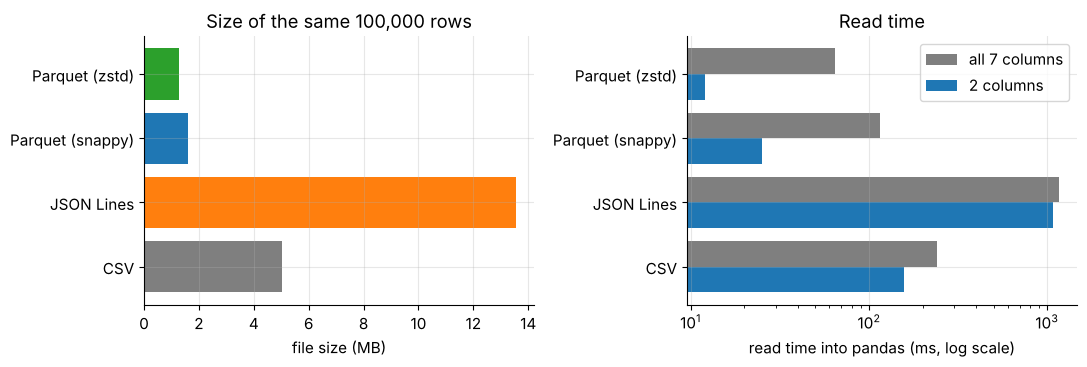

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["C7", "C1", "C0", "C2"]
axes[0].barh(fmt_table.index, fmt_table["size (MB)"], color=colors)
axes[0].set_xlabel("file size (MB)")
axes[0].set_title("Size of the same 100,000 rows")
y = np.arange(len(fmt_table))
axes[1].barh(y + 0.2, fmt_table["read all columns (ms)"], height=0.4, color="C7", label="all 7 columns")
axes[1].barh(y - 0.2, fmt_table["read 2 columns (ms)"], height=0.4, color="C0", label="2 columns")
axes[1].set_yticks(y, fmt_table.index)
axes[1].set_xscale("log")
axes[1].set_xlabel("read time into pandas (ms, log scale)")
axes[1].set_title("Read time")
axes[1].legend()
plt.tight_layout()
plt.show()

The exact timings depend on your machine (and on what else it is doing), but the pattern is robust:

- **Size:** JSON Lines is the largest, because every record repeats every key (`"country":`) and every
  timestamp is long text. CSV is smaller, and Parquet is a fraction of CSV, with Zstandard usually a bit
  smaller than Snappy (Snappy is faster to decompress, and Zstandard compresses better).
- **Full reads:** Parquet is clearly faster than CSV and far faster than JSON Lines: it stores
  binary values with types, so nothing has to be parsed from text, and types are not *guessed* (CSV
  loses the timestamp type, and Parquet keeps it).
- **Reading 2 of 7 columns:** Parquet gets much faster again because it simply skips the other column
  chunks. CSV gets somewhat faster (it still scans every line, but builds fewer columns), and JSON Lines gains
  nothing (it must parse every object completely before selecting fields).

**Predicate pushdown and data skipping.** The footer statistics allow a reader to skip whole row groups
whose min/max range cannot match a filter. This only works well when the data is **clustered** by the
filter column, so that each row group covers a narrow range. Below, the same events are written with row
groups of 10,000 rows twice: once sorted by time (as they arrived) and once shuffled. We count how many
row groups a query for a six-hour window cannot rule out.

In [52]:
def row_groups_to_read(path, column, lo, hi):
    """Count row groups whose [min, max] statistics for `column` overlap the interval [lo, hi]."""
    meta = pq.ParquetFile(path).metadata
    idx = meta.schema.names.index(column)
    stats = [meta.row_group(i).column(idx).statistics for i in range(meta.num_row_groups)]
    return sum(st.min <= hi and st.max >= lo for st in stats), meta.num_row_groups


table_sorted = pa.Table.from_pandas(typed_web, preserve_index=False)
table_shuffled = pa.Table.from_pandas(typed_web.sample(frac=1.0, random_state=0), preserve_index=False)
lo, hi = datetime(2026, 3, 3, 0, 0, tzinfo=UTC), datetime(2026, 3, 3, 6, 0, tzinfo=UTC)
for label, tbl in [("sorted by time", table_sorted), ("shuffled", table_shuffled)]:
    p = fmt_dir / f"events_{label.split()[0]}.parquet"
    pq.write_table(tbl, p, row_group_size=10_000)
    need, total = row_groups_to_read(p, "event_time", lo, hi)
    print(f"{label:15s}: the 6-hour filter must read {need:2d} of {total} row groups")

meta = pq.ParquetFile(fmt_dir / "events_sorted.parquet").metadata
chunk = meta.row_group(0).column(meta.schema.names.index("country"))
print(f"\nfooter of the sorted file: {meta.num_rows:,} rows, {meta.num_row_groups} row groups, {meta.num_columns} columns")
print(f"row group 0, column 'country': codec={chunk.compression}, encodings={chunk.encodings}, "
      f"min={chunk.statistics.min!r}, max={chunk.statistics.max!r}, nulls={chunk.statistics.null_count}")

sorted by time : the 6-hour filter must read  2 of 10 row groups
shuffled       : the 6-hour filter must read 10 of 10 row groups

footer of the sorted file: 100,000 rows, 10 row groups, 7 columns
row group 0, column 'country': codec=SNAPPY, encodings=('PLAIN', 'RLE', 'RLE_DICTIONARY'), min='CA', max='US', nulls=0


Sorted by time, the six-hour window falls inside one or two row groups and the reader can skip
everything else. Shuffled, every row group spans the whole week, so the statistics rule nothing out and
the reader must decompress and check every row. That is why curated tables are often **sorted (or
clustered) by the most common filter column** before writing. (Table formats offer this as
"Z-ordering" or "clustering", which keeps several columns roughly sorted at once.) Note also the column
metadata: the `country` chunk uses dictionary encoding (`RLE_DICTIONARY`), and its min/max are the
alphabetically smallest and largest country codes.

| | CSV | JSON Lines | Parquet |
|---|---|---|---|
| Layout | rows of text | one JSON object per line | binary, columnar, row groups |
| Schema and types | none (guessed on read) | per record, loosely typed | embedded in the footer, strict |
| Nested data | no | yes | yes (structs, lists, maps) |
| Compression | external only (gzip the whole file) | external only | built in, per column (Snappy, Zstandard, gzip) |
| Read a subset of columns | must scan all text | must parse all text | reads only those column chunks |
| Skip rows by a filter | no | no | yes, via row-group statistics (and partitions) |
| Append a record | trivial | trivial | no: files are immutable, write a new file |
| Human-readable | yes | yes | no (needs a tool) |
| Best for | small exchanges, spreadsheets | raw events, API payloads, logs | curated analytical tables, ML datasets |

Other formats you will meet: **Avro** (row-oriented binary with an embedded schema, popular in Kafka
pipelines), **ORC** (columnar, similar to Parquet, from the Hive ecosystem), **Arrow IPC / Feather** (the
in-memory columnar format on disk, very fast to load), and for ML, **TFRecord** or **WebDataset** shards of
images and labels.

> **Common pitfall.** Converting raw JSON to Parquet *and deleting the JSON*. Parquet needs a fixed schema,
> so fields that did not fit (a new nested field, a value of an unexpected type) may be dropped or
> coerced during conversion. Keep the raw JSON in bronze, and write Parquet in silver.

### 4.5 The small-files problem

Each file in a lake has a fixed overhead that does not depend on its size: a `LIST` entry and a `GET`
request on object storage (tens of milliseconds and a fee each), opening the file, parsing its footer,
planning a task for it. With a few large files that overhead is negligible, but with **many tiny files** it
dominates. Small files are produced by micro-batches and streams that flush every few seconds (Section
3.2), by over-partitioning (Section 4.3), and by many producers each uploading their own little files.

The experiment writes the same 100,000 web events once as a single Parquet file and once as 250 files of
400 rows each, then reads both datasets completely.

In [53]:
small_dir, big_dir = fmt_dir / "many_small", fmt_dir / "one_big"
for d in (small_dir, big_dir):
    shutil.rmtree(d, ignore_errors=True)
    d.mkdir()
pq.write_table(table_sorted, big_dir / "part-0000.parquet")
for i, start in enumerate(range(0, table_sorted.num_rows, 400)):
    pq.write_table(table_sorted.slice(start, 400), small_dir / f"part-{i:04d}.parquet")


def dataset_stats(folder: Path) -> dict:
    files = sorted(folder.glob("*.parquet"))
    read_ms = best_time_ms(lambda p: ds.dataset(p, format="parquet").to_table(), folder)
    return {"files": len(files), "total size (MB)": sum(f.stat().st_size for f in files) / 1e6,
            "full read (ms)": read_ms}


small_vs_big = pd.DataFrame({"1 file": dataset_stats(big_dir), "250 small files": dataset_stats(small_dir)}).T
display(small_vs_big.round(2))
print(f"the small files are {small_vs_big.iloc[1, 1] / small_vs_big.iloc[0, 1]:.1f}x larger in total and "
      f"{small_vs_big.iloc[1, 2] / small_vs_big.iloc[0, 2]:.0f}x slower to read, on a local disk")

# Compaction: rewrite the small files into one large file (what OPTIMIZE / rewrite jobs do).
compacted = ds.dataset(small_dir, format="parquet").to_table()
pq.write_table(compacted, fmt_dir / "compacted.parquet")
print("after compaction:", compacted.num_rows, "rows in 1 file of",
      f"{(fmt_dir / 'compacted.parquet').stat().st_size / 1e6:.2f} MB")

,files,total size (MB),full read (ms)
1 file,1.0,1.62,24.11
250 small files,250.0,3.33,160.48


the small files are 2.1x larger in total and 7x slower to read, on a local disk


after compaction: 100000 rows in 1 file of 1.62 MB


Even on a local disk, where opening a file costs microseconds rather than the tens of milliseconds of an
object store, the 250 small files take many times longer to read, and they are larger in total because
every file repeats its own footer and schema, and compression works poorly on 400 rows. On
object storage the gap becomes dramatic: 250 `GET` requests at 20–50 ms each are 5–12 seconds of pure
latency unless the reader parallelizes heavily, against one request for the single file.

Remedies, from prevention to cure:

1. **Batch before writing:** buffer records and flush when a size threshold (say 128 MB) *or* a time limit
   is reached, whichever comes first.
2. **Partition coarsely** enough that each partition holds at least one decently sized file.
3. **Compact** regularly: a background job rewrites many small files of a partition into a few large ones
   (exactly the last line of the cell above). Table formats provide it as a command (`OPTIMIZE` in Delta
   Lake, `rewrite_data_files` in Iceberg) and do it safely while readers keep reading (Section 4.7).
4. **Target file sizes** of roughly 128 MB to 1 GB for analytical tables.

### 4.6 From lake to swamp: governance, catalogs and lineage

A **data swamp** is a lake that nobody can use any more. It does not happen in one day. It happens one
undocumented folder at a time. The symptoms are easy to recognize:

- folders such as `exports_final_v2_REAL/` and `tmp_bob_2023/`, and nobody knows what is inside.
- three copies of "customers", with three different row counts.
- no owner to ask, no documentation of what a column means or in which unit it is.
- no idea how fresh a dataset is, or which job writes it.
- personal data scattered in places nobody knows about (a privacy and security risk).
- nobody dares to delete anything, so the storage bill only grows.

**Data governance** is the set of practices that prevents this. Its main pillars:

| Pillar | What it means in a lake | Typical tools |
|---|---|---|
| **Catalog and metadata** | every dataset is registered with its location, format, schema and partitions (*technical* metadata), a description, owner and glossary terms (*business* metadata), and freshness, row counts and quality results (*operational* metadata) | Hive Metastore, AWS Glue Data Catalog, Unity Catalog, DataHub, OpenMetadata, Amundsen |
| **Ownership and contracts** | each dataset has an owning team, and producers publish a **data contract** (schema, units, update schedule, quality guarantees) | contract files in Git, schema registries |
| **Lineage** | which datasets and jobs each dataset is derived from, down to columns if possible | OpenLineage, the lineage views of catalogs and orchestrators |
| **Quality** | automated checks at ingestion and promotion between zones (Section 5.5) | Great Expectations, Soda, dbt tests |
| **Access control and privacy** | least-privilege access, column masking, tags on personal data, encryption, audit logs | IAM policies, Lake Formation, Ranger, catalog permissions |
| **Lifecycle** | retention periods, cheaper storage tiers for old data, and deletion when required (privacy laws give people a right to erasure, which is hard in immutable files: table formats help, Section 4.7) | lifecycle rules, `DELETE` + vacuum |

**Lineage** deserves a demonstration, because it answers the two questions you will ask during every
incident: *"this number looks wrong. Where does it come from?"* (look **upstream**) and *"this source was
broken yesterday. What did it contaminate?"* (look **downstream**). A lineage graph is just a directed
graph from inputs to outputs, and both questions are graph searches.

In [54]:
LINEAGE = {   # dataset -> the datasets it is computed from
    "raw/payments_app": [], "raw/crm_customers": [], "raw/fx_rates": [],
    "silver/payments": ["raw/payments_app"],
    "silver/customers": ["raw/crm_customers"],
    "silver/fx_rates": ["raw/fx_rates"],
    "gold/revenue_daily": ["silver/payments", "silver/fx_rates"],
    "gold/customer_lifetime_value": ["silver/payments", "silver/customers", "silver/fx_rates"],
    "gold/churn_training_set": ["gold/customer_lifetime_value", "silver/customers"],
}


def upstream(dataset: str, graph: dict = LINEAGE) -> list[str]:
    """Every dataset that `dataset` (directly or indirectly) depends on."""
    seen, stack = set(), list(graph[dataset])
    while stack:
        d = stack.pop()
        if d not in seen:
            seen.add(d)
            stack.extend(graph[d])
    return sorted(seen)


def downstream(dataset: str, graph: dict = LINEAGE) -> list[str]:
    """Every dataset that is (directly or indirectly) computed from `dataset`: a breadth-first search."""
    children = {d: [k for k, parents in graph.items() if d in parents] for d in graph}
    seen, queue = set(), list(children[dataset])
    while queue:
        d = queue.pop(0)
        if d not in seen:
            seen.add(d)
            queue.extend(children[d])
    return sorted(seen)


print("gold/churn_training_set is built from:", upstream("gold/churn_training_set"))
print("a bug in raw/fx_rates contaminates   :", downstream("raw/fx_rates"))

gold/churn_training_set is built from: ['gold/customer_lifetime_value', 'raw/crm_customers', 'raw/fx_rates', 'raw/payments_app', 'silver/customers', 'silver/fx_rates', 'silver/payments']
a bug in raw/fx_rates contaminates   : ['gold/churn_training_set', 'gold/customer_lifetime_value', 'gold/revenue_daily', 'silver/fx_rates']


A wrong exchange rate in one tiny raw table silently reaches revenue reports *and* an ML training set three
hops away. With lineage recorded, you know exactly what to rebuild (in dependency order, upstream first)
and whom to warn. Without it, you guess. Orchestrators such as Dagster and Airflow, and catalogs such as
DataHub, collect this graph automatically from the jobs themselves.

> **Key idea.** A lake becomes a swamp when data is written without metadata. Make registration part of
> the pipeline (every job that writes a dataset also writes its catalog entry), not a documentation task
> for later, because "later" never comes. Our mini lake does this in Section 5.4.


### 4.7 Open table formats and the lakehouse

Plain Parquet folders have serious limits once several jobs and users share them:

1. **No atomic multi-file writes.** A job that writes 50 files and crashes after 30 leaves a half-written
   table, and readers that list the folder in the middle of a write see a mix of old and new files.
2. **No isolation between concurrent writers.** Two jobs updating the same partition can overwrite each
   other's work.
3. **Updates and deletes are manual.** Changing one row means rewriting a whole file (files are immutable),
   and keeping track of which files are current is up to you.
4. **Listing is slow** on object storage when a table has millions of files, and renames are not atomic
   (Section 2.5).
5. **No history:** once a file is overwritten, yesterday's version of the table is gone.

**Open table formats** (Delta Lake, Apache Iceberg, Apache Hudi) fix all five with one idea: keep the data
in immutable Parquet files, and keep a **transaction log** of metadata next to them that says *which files
make up the table at each version*. A reader never lists the folder. It reads the log. A writer adds new
files first (invisible, because no log entry mentions them yet) and then **commits** by atomically
creating the next log entry. Exactly one writer can create entry number $v+1$. A writer that loses the
race must re-read the log, check that its change does not conflict, and retry (**optimistic
concurrency**). The toy implementation below has the same shape as Delta Lake's `_delta_log/`.

In [55]:
class CommitConflict(Exception):
    """Raised when another writer has already committed the version we tried to create."""


class ToyLogTable:
    """A toy table format: immutable Parquet data files plus a log of numbered JSON commits."""

    def __init__(self, root: Path):
        self.root = Path(root)
        self.log_dir = self.root / "_log"
        self.log_dir.mkdir(parents=True, exist_ok=True)

    def latest_version(self) -> int:
        versions = [int(p.stem) for p in self.log_dir.glob("*.json")]
        return max(versions, default=-1)

    def live_files(self, version: int | None = None) -> list[str]:
        """Replay the log up to `version` (default: latest): the set of data files of that snapshot."""
        version = self.latest_version() if version is None else version
        live = set()
        for v in range(version + 1):
            entry = json.loads((self.log_dir / f"{v:06d}.json").read_text())
            live = (live - set(entry["remove"])) | set(entry["add"])
        return sorted(live)

    def read(self, version: int | None = None) -> pd.DataFrame:
        frames = [pd.read_parquet(self.root / f) for f in self.live_files(version)]
        return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

    def commit(self, read_version: int, writer: str, add: list = (), remove: list = (), op: str = "WRITE") -> int:
        """Write the new data files, then atomically create log entry read_version + 1."""
        version = read_version + 1
        names = []
        for i, frame in enumerate(add):
            name = f"{writer}-v{version}-{i}.parquet"
            frame.to_parquet(self.root / name, index=False)     # invisible until the commit succeeds
            names.append(name)
        entry = {"version": version, "op": op, "writer": writer, "add": names, "remove": list(remove)}
        try:
            with open(self.log_dir / f"{version:06d}.json", "x") as fh:   # mode "x": fail if it exists
                json.dump(entry, fh)
        except FileExistsError:
            raise CommitConflict(f"{writer}: version {version} was already committed by someone else") from None
        return version


tbl = ToyLogTable(PLAY / "toy_table")
day1 = pd.DataFrame({"order_id": ["A1", "A2"], "day": "03-01", "amount": [20.0, 35.0]})
day2 = pd.DataFrame({"order_id": ["B1", "B2"], "day": "03-02", "amount": [12.5, 99.0]})
v0 = tbl.commit(-1, "ingest", add=[day1])
v1 = tbl.commit(v0, "ingest", add=[day2])
# A correction: order A2 was 53.0, not 35.0. Rewrite day 1's file: remove the old file, add a fixed one.
v2 = tbl.commit(v1, "fixer", add=[day1.assign(amount=[20.0, 53.0])], remove=tbl.live_files(v1)[:1], op="UPDATE")
print("live files at the latest version:", tbl.live_files())
print("total amount now:", tbl.read()["amount"].sum(), "| time travel to version 1:", tbl.read(version=1)["amount"].sum())

# Two writers start from the same version; only one can create the next log entry.
start = tbl.latest_version()
tbl.commit(start, "writer-A", add=[pd.DataFrame({"order_id": ["C1"], "day": "03-03", "amount": [7.0]})])
try:
    tbl.commit(start, "writer-B", add=[pd.DataFrame({"order_id": ["C2"], "day": "03-03", "amount": [8.0]})])
except CommitConflict as err:
    print("conflict:", err)
    retry_from = tbl.latest_version()                 # re-read the log, check for conflicts, retry
    tbl.commit(retry_from, "writer-B", add=[pd.DataFrame({"order_id": ["C2"], "day": "03-03", "amount": [8.0]})])
print("log entries:", sorted(p.name for p in tbl.log_dir.glob("*.json")))
print("data files on disk:", len(list(tbl.root.glob("*.parquet"))), "| live files:", len(tbl.live_files()),
      "| rows now:", len(tbl.read()))

live files at the latest version: ['fixer-v2-0.parquet', 'ingest-v1-0.parquet']
total amount now: 184.5 | time travel to version 1: 166.5
conflict: writer-B: version 3 was already committed by someone else
log entries: ['000000.json', '000001.json', '000002.json', '000003.json', '000004.json']
data files on disk: 6 | live files: 4 | rows now: 6


Everything the toy shows is real behavior of table formats:

- The update did not modify any file: it **added** a corrected file and **removed** the old one *in the
  log*. The old file is still on disk, which is what makes **time travel** possible (`read(version=1)`
  still sees 35.0). A maintenance command (`VACUUM` in Delta Lake, snapshot expiry in Iceberg) eventually
  deletes files that no retained version references.
- Readers see either version $v$ or version $v+1$, never a half-written state, because the commit is a
  single atomic file creation. On object storage this needs an atomic "create only if absent" operation:
  Google Cloud Storage and Azure have long offered one, and Amazon S3 added conditional writes in 2024.
  Iceberg instead atomically swaps a pointer in a catalog.
- The losing writer got a conflict instead of silently overwriting writer A's commit. Real formats check
  whether the two commits actually touched the same data and retry automatically if not.
- A writer that crashes (or loses a commit race) after writing data files leaves orphan files that no log
  entry mentions: invisible to readers, and removed by vacuuming. That is why the folder above holds 6
  data files but the table has only 4 live ones: the replaced day-1 file (kept for time travel) and
  writer B's file from its failed first attempt.

| | Delta Lake | Apache Iceberg | Apache Hudi |
|---|---|---|---|
| Origin | Databricks, 2019 (now a Linux Foundation project) | Netflix, 2018 (Apache) | Uber, 2016 (Apache) |
| Metadata | `_delta_log/` of JSON commits plus periodic Parquet checkpoints | a metadata file pointing to manifest lists and manifests, and the catalog stores the current pointer | a `.hoodie/` timeline of commits |
| Known for | simplicity, Spark integration, `OPTIMIZE` and Z-ordering | engine neutrality (Spark, Trino, Flink, Snowflake, BigQuery, DuckDB, ...), hidden partitioning, partition evolution | record-level upserts, incremental pulls, merge-on-read tables |

All three provide ACID commits, time travel, schema enforcement and evolution, `MERGE`/`UPDATE`/`DELETE`,
compaction, and file-level statistics for data skipping. A **lakehouse** is the architecture built on
them: open files on cheap object storage, an open table format for transactions, a catalog for governance,
and any number of engines (SQL, Spark, Python, ML training) on top. It aims to give warehouse-style
reliability without copying data into a separate warehouse.

### 4.8 Platforms: Amazon S3, Google Cloud Storage, Azure Data Lake Storage Gen2, MinIO

| | Amazon S3 | Google Cloud Storage | Azure Data Lake Storage Gen2 | MinIO |
|---|---|---|---|---|
| Address | `s3://bucket/key` | `gs://bucket/object` | `abfss://container@account.dfs.core.windows.net/path` | `s3://bucket/key` at your own endpoint |
| Namespace | flat (prefixes) | flat, and buckets with a hierarchical namespace are available | **hierarchical namespace** (real directories) | flat (prefixes) |
| Consistency | strong read-after-write (since 2020) | strong | strong | strong |
| Notable | the de-facto standard object API, many storage classes and managed Iceberg tables (S3 Tables) | tight BigQuery integration | atomic directory rename and delete, POSIX-like access control lists (ACLs) | S3-compatible and self-hosted, but the open-source (AGPLv3) community edition was archived in April 2026 and is no longer maintained (the vendor now offers the commercially licensed AIStor) |
| Typical role | the default lake on AWS | the lake on Google Cloud | the lake on Azure (Synapse, Fabric, Databricks) | existing on-premises deployments, and for a new self-hosted setup, prefer an actively maintained S3-compatible server (Garage, SeaweedFS, Ceph's RADOS Gateway) |

**Azure Data Lake Storage Gen2** is Azure Blob Storage with the **hierarchical namespace** (HNS) switched
on. Directories become real objects in the metadata layer, so renaming or deleting a directory with a
million files is a single atomic metadata operation instead of a million copies and deletes (compare the
144 requests our toy object store needed to "rename" 72 objects in Section 2.5). That makes
rename-based commit protocols (used by older Hadoop and Spark jobs) safe and fast. Permissions can be set
per directory and file with POSIX-style ACLs, on top of Azure's role-based access control.

**MinIO** speaks the S3 API, so code written against S3 runs unchanged against a MinIO server on your
laptop or in your own data center, which made it the classic choice for development, testing and
on-premises lakes. Its open-source community edition is no longer maintained, however: the GitHub
repository was archived in April 2026, and the vendor now points users to AIStor, a commercially licensed
product (with a free standalone edition). For a new setup, pick an actively maintained S3-compatible
server such as Garage, SeaweedFS or Ceph's RADOS Gateway, and check any project's current status before
you depend on it. The `endpoint_override` code below works the same with all of them.

**Writing portable code.** Because every platform is "a key–value store of immutable files", the same
pipeline can run against a local folder (as in this notebook), a self-hosted S3-compatible server or a
cloud bucket if you write paths through a file-system abstraction. A sketch (not executed here: it needs
credentials and a server):

```python
import pyarrow.fs as pafs
# credentials come from environment variables or ~/.aws, never from the notebook itself
s3 = pafs.S3FileSystem(region="us-east-1")
local = pafs.S3FileSystem(endpoint_override="localhost:9000", scheme="http",   # any S3-compatible server
                          access_key=os.environ["LOCAL_S3_ACCESS_KEY"], secret_key=os.environ["LOCAL_S3_SECRET_KEY"])
pq.write_table(table, "my-lake/silver/sales/sale_date=2026-03-05/part-0.parquet", filesystem=local)
sales = ds.dataset("my-lake/silver/sales", filesystem=s3, format="parquet", partitioning="hive")
```

Libraries in the `fsspec` family (`s3fs`, `gcsfs`, `adlfs`) give pandas the same ability:
`pd.read_parquet("s3://my-lake/silver/sales/")` works once the matching package and credentials are set
up. Our mini lake in `data/01_lake/` uses the same folder conventions, so moving it to a bucket would only
change the root path.

<details>
<summary><b>Quick check:</b> why do table formats make "rename the temporary folder into place" unnecessary, and why does that matter more on S3 than on ADLS Gen2?</summary>

Table formats publish new data by **committing a log entry** that lists the new files, and the files never
move. Atomicity comes from creating one small log object, not from renaming folders. On S3, a "folder
rename" is a copy plus a delete of every object (slow, costly and not atomic), so rename-based commits are
unsafe there. On ADLS Gen2 with a hierarchical namespace, a directory rename is atomic, so older
rename-based protocols work, but the log approach is still faster and also enables time travel.
</details>

## 5. Hands-on: building a mini data lake

Time to put everything together. We will build a small but complete lake in `data/01_lake/` that ingests
three kinds of sources every day:

| Job | Source | Origin / structure | Techniques |
|---|---|---|---|
| `arxiv` | research papers from the arXiv Atom API | web API / semi-structured XML | query building, polite delays, retries, XML namespaces, dedup across queries, merge-on-write |
| `api` | a product catalog behind a paginated REST API (a local mock server) | API / JSON | auth header, cursor pagination, `429` + `Retry-After`, transient `503`, incremental extraction with a persisted watermark |
| `files` | partner sales files dropped into a folder (CSV, JSON, Excel) | flat files / structured | SHA-256 manifest (re-ingest = no-op), schema-drift detection |

Then we curate the raw data into Parquet tables with Hive-style partitions, register them in a small
catalog, gate them with data-quality checks, query them with SQL, and finally wrap the jobs in a
command-line orchestrator that a scheduler can run every night.

```text
data/01_lake/
├── landing/partner_drop/                    partners put files here
├── raw/                                     bronze: as received, partitioned by ingestion (logical) date
│   ├── arxiv/ingest_date=2026-03-02/papers.jsonl
│   ├── shop_api/ingest_date=2026-03-02/page-0001.json ...
│   └── partner_files/ingest_date=2026-03-02/<sha256 prefix>__<original name>
├── silver/                                  typed Parquet, Hive-style partitions (Section 5.4)
├── _state/                                  watermarks and file manifests
├── _catalog/catalog.sqlite                  what exists, where, how big, how fresh (Section 5.4)
├── _reports/                                run reports and data-quality reports
└── _logs/                                   one log file per day (Section 5.8)
```

**A simulated clock.** Real jobs ask the clock what day it is, while ours receive a **logical date** (Section
1.3) and a fixed "now". We run the lake for two days, 2026-03-02 and 2026-03-03, so every output in this
section is reproducible. Every job is written to be **idempotent**: running it again for the same date
changes nothing.

### 5.0 Shared helpers

First, a few small helpers that every job uses: JSON Lines files written atomically, SHA-256 checksums
computed in chunks (files can be larger than memory), and one robust `http_get` that implements the
retry rules of Section 2.2 (a `429` or `503` with a `Retry-After` header is honored exactly, other
transient failures use exponential backoff with full jitter, and client errors such as `401` are *not*
retried). The transport (the function that actually sends a request) can be swapped, which lets us test
the client against fake servers.

In [56]:
RUN_DATES = [date(2026, 3, 2), date(2026, 3, 3)]


def run_clock(logical_date: date) -> datetime:
    """The simulated wall-clock time of the nightly run for `logical_date`: 01:00 UTC the next day."""
    return datetime(logical_date.year, logical_date.month, logical_date.day, 1, 0, tzinfo=UTC) + timedelta(days=1)


def write_jsonl_atomic(path, records) -> None:
    """Write a list of dicts as JSON Lines, atomically (temporary file + replace)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as fh:
        for rec in records:
            fh.write(json.dumps(rec, sort_keys=True, ensure_ascii=False) + "\n")
    os.replace(tmp, path)


def read_jsonl(path) -> list:
    """Read a JSON Lines file; a missing file means 'no records yet'."""
    path = Path(path)
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def sha256_file(path, chunk_size: int = 1 << 16) -> str:
    """SHA-256 of a file, read in chunks so that huge files never have to fit in memory."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


RETRYABLE_STATUS = {408, 429, 500, 502, 503, 504}


def parse_retry_after(value, now=None):
    """Seconds to wait according to a Retry-After header (delta-seconds or an HTTP date), or None."""
    if value is None:
        return None
    value = str(value).strip()
    if value.isdigit():
        return float(value)
    try:
        when = email.utils.parsedate_to_datetime(value)
    except (TypeError, ValueError):
        return None
    now = now or datetime.now(timezone.utc)
    return max(0.0, (when - now).total_seconds())


def urllib_transport(url, headers, timeout):
    """Send one GET with urllib; return (status, lower-cased headers, body bytes) even for 4xx/5xx."""
    request = urllib.request.Request(url, headers=headers)
    local = (urllib.parse.urlparse(url).hostname or "") in ("127.0.0.1", "localhost")
    opener = urllib.request.build_opener(*([urllib.request.ProxyHandler({})] if local else []))  # no proxy for local servers
    try:
        with opener.open(request, timeout=timeout) as resp:
            return resp.status, {k.lower(): v for k, v in resp.headers.items()}, resp.read()
    except urllib.error.HTTPError as err:                  # error statuses still carry headers and a body
        return err.code, {k.lower(): v for k, v in (err.headers or {}).items()}, err.read()


def http_get(url, headers=None, timeout=10.0, max_retries=4, base=0.5, cap=8.0,
             transport=None, sleep=time.sleep, rng=None, events=None):
    """GET with retries. Honors Retry-After on 429/503; otherwise exponential backoff with full jitter.

    Returns (status, headers, body) for success and for non-retryable errors (e.g. 401, 404), so the
    caller can decide. Raises RuntimeError when the retries are exhausted. `events`, if given, is a list
    that receives one dict per failed attempt (for run reports).
    """
    transport = transport or urllib_transport
    rng = rng or random.Random()
    for attempt in range(max_retries + 1):
        try:
            status, resp_headers, body = transport(url, headers or {}, timeout)
            problem = f"HTTP {status}"
        except (urllib.error.URLError, TimeoutError, ConnectionError, OSError) as exc:
            status, resp_headers, body, problem = None, {}, b"", f"{type(exc).__name__}: {exc}"
        if status is not None and (status < 400 or status not in RETRYABLE_STATUS):
            return status, resp_headers, body
        if attempt == max_retries:
            raise RuntimeError(f"giving up on {url} after {attempt + 1} attempts ({problem})")
        wait = parse_retry_after(resp_headers.get("retry-after")) if status in (429, 503) else None
        if wait is None:
            wait = rng.uniform(0, min(cap, base * 2 ** attempt))           # full jitter
        if events is not None:
            events.append({"attempt": attempt + 1, "problem": problem, "wait_s": round(wait, 3)})
        sleep(wait)


# A quick test against a fake transport: two failures, then success.
replies = iter([(503, {"retry-after": "2"}, b""), (500, {}, b""), (200, {}, b"ok")])
waits, attempts_log = [], []
status, _, body = http_get("https://example.org/x", transport=lambda u, h, t: next(replies),
                           sleep=waits.append, rng=random.Random(0), events=attempts_log)
print("final:", status, body, "| waits:", waits)
for e in attempts_log:
    print("  ", e)
print("Retry-After as an HTTP date, 90 s ahead ->",
      parse_retry_after("Mon, 02 Mar 2026 10:01:30 GMT", now=datetime(2026, 3, 2, 10, 0, tzinfo=UTC)), "seconds")

final: 200 b'ok' | waits: [2.0, 0.8444218515250481]
   {'attempt': 1, 'problem': 'HTTP 503', 'wait_s': 2.0}
   {'attempt': 2, 'problem': 'HTTP 500', 'wait_s': 0.844}
Retry-After as an HTTP date, 90 s ahead -> 90.0 seconds


The first failure was a `503` with `Retry-After: 2`, so the client waited exactly 2 seconds, and the second, a
plain `500`, got a jittered backoff drawn from $[0, 1]$ seconds (attempt 2, ceiling $0.5 \cdot 2^1$). The
`sleep` function is injectable too, so tests (and this notebook) never actually wait. One more design
choice worth noticing: `401`/`403`/`404` are returned immediately, because retrying a request with a wrong
key only burns quota.

### 5.1 arXiv: an Atom API client

[arXiv](https://arxiv.org) is an open archive of research papers in physics, mathematics and computer
science, with a free query API. A query is a single `GET` whose `search_query` parameter combines field
prefixes such as `cat:` (category), `ti:` (title), `au:` (author) and `submittedDate:[from TO to]` (times
as `YYYYMMDDHHMM` in UTC) with `AND`/`OR`, plus paging parameters `start` and `max_results` and a sort
order. The answer is an **Atom feed**: XML with one `<entry>` per paper. The API manual asks clients to
wait about **3 seconds between calls** and to fetch large result sets in modest pages, and we follow both.

Our daily job asks, for each category we follow, "which papers were submitted on the logical date?",
merges the answers (a paper cross-listed in two categories is returned by both queries), and merges the
result into one JSON Lines file per day.

In [57]:
ARXIV_API = "https://export.arxiv.org/api/query"
ARXIV_CATEGORIES = ["cs.LG", "cs.CV", "stat.ML"]
ATOM_NS = {"atom": "http://www.w3.org/2005/Atom", "arxiv": "http://arxiv.org/schemas/atom",
           "opensearch": "http://a9.com/-/spec/opensearch/1.1/"}


def build_arxiv_query_url(categories, day, start=0, max_results=50):
    """URL for papers in any of `categories` submitted on `day` (UTC), oldest first."""
    cats = " OR ".join(f"cat:{c}" for c in categories)
    span = f"submittedDate:[{day:%Y%m%d}0000 TO {day:%Y%m%d}2359]"
    query = f"({cats}) AND {span}" if len(categories) > 1 else f"{cats} AND {span}"
    params = {"search_query": query, "start": start, "max_results": max_results,
              "sortBy": "submittedDate", "sortOrder": "ascending"}
    return ARXIV_API + "?" + urllib.parse.urlencode(params)


def parse_arxiv_feed(xml_bytes):
    """Parse an arXiv Atom feed into (total_results, list of normalized paper dicts)."""
    root = ET.fromstring(xml_bytes)
    total = int(root.findtext("opensearch:totalResults", default="0", namespaces=ATOM_NS))
    papers = []
    for entry in root.findall("atom:entry", ATOM_NS):
        abs_url = entry.findtext("atom:id", default="", namespaces=ATOM_NS).strip()
        match = re.search(r"/abs/(.+?)v(\d+)$", abs_url)          # e.g. http://arxiv.org/abs/2603.01234v2
        if not match:
            continue                                               # not a paper entry (e.g. an error entry)
        text = lambda tag: " ".join((entry.findtext(tag, default="", namespaces=ATOM_NS) or "").split())
        pdf = [l.get("href") for l in entry.findall("atom:link", ATOM_NS) if l.get("title") == "pdf"]
        primary = entry.find("arxiv:primary_category", ATOM_NS)
        papers.append({
            "arxiv_id": match.group(1), "version": int(match.group(2)),
            "title": text("atom:title"), "summary": text("atom:summary"),
            "authors": [a.findtext("atom:name", default="", namespaces=ATOM_NS).strip()
                        for a in entry.findall("atom:author", ATOM_NS)],
            "primary_category": primary.get("term") if primary is not None else None,
            "categories": [c.get("term") for c in entry.findall("atom:category", ATOM_NS)],
            "published": text("atom:published"), "updated": text("atom:updated"),
            "pdf_url": pdf[0] if pdf else None,
        })
    return total, papers


print(build_arxiv_query_url(["cs.LG"], date(2026, 3, 2)))

https://export.arxiv.org/api/query?search_query=cat%3Acs.LG+AND+submittedDate%3A%5B202603020000+TO+202603022359%5D&start=0&max_results=50&sortBy=submittedDate&sortOrder=ascending


Notice the namespaces: every Atom tag lives in the namespace `http://www.w3.org/2005/Atom`, arXiv's own
tags (`primary_category`, `comment`, `doi`) in `http://arxiv.org/schemas/atom`, and the paging totals in
the OpenSearch namespace. `ElementTree` only finds a tag if you give its namespace, which is what the
`ATOM_NS` prefix map does. Forgetting it is the classic "my XML parser returns nothing" bug.

Next, an offline stand-in for the real API. `sample_arxiv_transport` behaves like the real endpoint (it
reads `search_query`, `start` and `max_results` from the URL and answers with an Atom feed) but serves a
small embedded list of **fictional** papers. The job code is identical either way. Only the transport
differs.

In [58]:
SAMPLE_PAPERS = [   # fictional papers: invented titles and authors, used when the live API is unavailable
    ("2603.90011", 1, "2026-03-02T09:14:00Z", ["cs.LG", "stat.ML"], "Sketched Gradients for Tiny Federated Clients", ["Alex Example", "Jordan Sample"]),
    ("2603.90012", 1, "2026-03-02T11:02:00Z", ["cs.CV"], "A Toy Benchmark for Counting Objects in Synthetic Scenes", ["Riley Placeholder"]),
    ("2603.90013", 1, "2026-03-02T15:47:00Z", ["stat.ML", "cs.LG"], "Calibration Curves Under Label Shift: A Didactic Study", ["Casey Fictional", "Alex Example"]),
    ("2603.90014", 1, "2026-03-02T18:30:00Z", ["cs.LG"], "Learning-Rate Warmup Explained with Two-Parameter Models", ["Morgan Mockup"]),
    ("2603.90015", 1, "2026-03-02T21:05:00Z", ["cs.CV", "cs.LG"], "Patch Dropout as Cheap Data Augmentation", ["Jordan Sample", "Taylor Dummy"]),
    ("2603.90021", 1, "2026-03-03T08:20:00Z", ["cs.LG"], "When Do Small Transformers Learn Modular Addition?", ["Riley Placeholder", "Casey Fictional"]),
    ("2603.90022", 1, "2026-03-03T10:41:00Z", ["stat.ML"], "Bootstrap Intervals for Leaderboard Accuracies", ["Morgan Mockup"]),
    ("2603.90023", 1, "2026-03-03T13:13:00Z", ["cs.CV", "stat.ML"], "Uncertainty Maps for Toy Segmentation Tasks", ["Taylor Dummy", "Alex Example"]),
    ("2603.90024", 1, "2026-03-03T16:58:00Z", ["cs.LG", "cs.CV", "stat.ML"], "One Dataset, Three Splits: Leakage Case Studies", ["Jordan Sample"]),
    ("2603.90031", 1, "2026-03-04T09:00:00Z", ["cs.LG"], "Curriculum Ordering for Synthetic Arithmetic Data", ["Casey Fictional"]),
    ("2603.90032", 1, "2026-03-04T12:30:00Z", ["cs.CV"], "Low-Resolution Thumbnails Are Enough for Toy Retrieval", ["Riley Placeholder", "Morgan Mockup"]),
]


def render_atom(papers, total, start):
    """Render paper tuples as an arXiv-style Atom feed (the subset of tags our parser reads)."""
    out = ['<?xml version="1.0" encoding="UTF-8"?>',
           '<feed xmlns="http://www.w3.org/2005/Atom" xmlns:arxiv="http://arxiv.org/schemas/atom" '
           'xmlns:opensearch="http://a9.com/-/spec/opensearch/1.1/">',
           f"<opensearch:totalResults>{total}</opensearch:totalResults>",
           f"<opensearch:startIndex>{start}</opensearch:startIndex>"]
    for pid, ver, submitted, cats, title, authors in papers:
        out += ["<entry>", f"<id>http://arxiv.org/abs/{pid}v{ver}</id>",
                f"<published>{submitted}</published><updated>{submitted}</updated>",
                f"<title>{title}</title>",
                f"<summary>  A fictional abstract about {title.lower()}.\n  It exists only to test parsers. </summary>"]
        out += [f"<author><name>{a}</name></author>" for a in authors]
        out += [f'<link title="pdf" href="https://arxiv.org/pdf/{pid}v{ver}" rel="related" type="application/pdf"/>',
                f'<arxiv:primary_category term="{cats[0]}" scheme="http://arxiv.org/schemas/atom"/>']
        out += [f'<category term="{c}" scheme="http://arxiv.org/schemas/atom"/>' for c in cats]
        out.append("</entry>")
    return ("\n".join(out + ["</feed>"])).encode("utf-8")


def sample_arxiv_transport(url, headers, timeout):
    """Answer an arXiv query URL from SAMPLE_PAPERS, like the real API would (offline fallback)."""
    params = urllib.parse.parse_qs(urllib.parse.urlparse(url).query)
    query = params["search_query"][0]
    cats = set(re.findall(r"cat:([\w.\-]+)", query))
    lo, hi = re.search(r"submittedDate:\[(\d{12}) TO (\d{12})\]", query).groups()
    start, size = int(params.get("start", ["0"])[0]), int(params.get("max_results", ["10"])[0])
    stamp = lambda iso: iso[0:4] + iso[5:7] + iso[8:10] + iso[11:13] + iso[14:16]   # -> YYYYMMDDHHMM
    hits = sorted((p for p in SAMPLE_PAPERS if cats & set(p[3]) and lo <= stamp(p[2]) <= hi), key=lambda p: p[2])
    return 200, {"content-type": "application/atom+xml"}, render_atom(hits[start:start + size], len(hits), start)


total, papers = parse_arxiv_feed(sample_arxiv_transport(build_arxiv_query_url(["cs.LG"], date(2026, 3, 2)), {}, 5)[2])
print(f"sample feed: {total} cs.LG papers on 2026-03-02; first one:")
print(json.dumps(papers[0], indent=1)[:600])

sample feed: 4 cs.LG papers on 2026-03-02; first one:
{
 "arxiv_id": "2603.90011",
 "version": 1,
 "title": "Sketched Gradients for Tiny Federated Clients",
 "summary": "A fictional abstract about sketched gradients for tiny federated clients. It exists only to test parsers.",
 "authors": [
  "Alex Example",
  "Jordan Sample"
 ],
 "primary_category": "cs.LG",
 "categories": [
  "cs.LG",
  "stat.ML"
 ],
 "published": "2026-03-02T09:14:00Z",
 "updated": "2026-03-02T09:14:00Z",
 "pdf_url": "https://arxiv.org/pdf/2603.90011v1"
}


Now let us try the **real** API once, with a short timeout and a single retry. If it answers, you will
see real papers. If your machine is offline (or the service is unreachable), the notebook says so and the
lake keeps using the sample feed. Either way, the rest of the section ingests the *sample* feed by default,
so that every number below is reproducible. Set the environment variable `LAKE_LIVE_ARXIV=1` before
starting the notebook to ingest live data instead.

In [59]:
def probe_live_arxiv(timeout=5.0):
    """Try one real arXiv request; return (ok, message)."""
    url = build_arxiv_query_url(["cs.LG"], date(2026, 3, 2), max_results=3)
    try:
        status, _, body = http_get(url, headers={"User-Agent": "ai-foundations-mini-lake/1.0 (education)"},
                                   timeout=timeout, max_retries=1, base=0.5, cap=1.0)
        if status != 200:
            return False, f"HTTP {status}"
        n_total, live = parse_arxiv_feed(body)
        return True, f"{n_total} live results, e.g. {live[0]['title'][:70]!r}" if live else "no results"
    except Exception as exc:                          # offline, proxy, DNS, timeout, malformed XML ...
        return False, f"{type(exc).__name__}: {str(exc)[:120]}"


ok, message = probe_live_arxiv()
print("live arXiv API:", "reachable ->" if ok else "NOT reachable -> using the offline sample feed;", message)
ARXIV_TRANSPORT = None if (ok and os.environ.get("LAKE_LIVE_ARXIV") == "1") else sample_arxiv_transport
print("transport used by the lake jobs:", "live urllib" if ARXIV_TRANSPORT is None else "sample_arxiv_transport")

live arXiv API: NOT reachable -> using the offline sample feed; RuntimeError: giving up on https://export.arxiv.org/api/query?search_query=cat%3Acs.LG+AND+submittedDate%3A%5B202603020000+TO+20260302
transport used by the lake jobs: sample_arxiv_transport


The daily job itself. Three details matter:

1. **Paging and politeness.** For each category it pages through the results with `start` and
   `max_results`, pausing between calls (3 seconds against the real service, and no pause is needed for the
   offline sample).
2. **Deduplication across queries.** A paper cross-listed in `cs.LG` and `stat.ML` is returned by both
   queries. We keep one record per `arxiv_id` (the highest version wins) and remember *which* queries
   found it in `query_categories`.
3. **Merge-on-write.** The day's file is merged with what is already there and rewritten atomically. A
   record whose content did not change keeps its original `ingested_at`, so re-running a day produces a
   byte-identical file: the job is idempotent.

In [60]:
ARXIV_USER_AGENT = "ai-foundations-mini-lake/1.0 (education; contact: you@example.com)"


def merge_papers(existing, incoming):
    """Merge paper records by arxiv_id: highest (version, updated) wins; query_categories are united.
    Unchanged records keep their original ingested_at, which makes re-runs byte-identical."""
    content = lambda rec: {k: v for k, v in rec.items() if k != "ingested_at"}
    by_id = {p["arxiv_id"]: p for p in existing}
    for p in incoming:
        old = by_id.get(p["arxiv_id"])
        if old is None:
            by_id[p["arxiv_id"]] = p
            continue
        newer = (p["version"], p["updated"]) > (old["version"], old["updated"])
        cats = sorted(set(old.get("query_categories", [])) | set(p.get("query_categories", [])))
        merged = {**(p if newer else old), "query_categories": cats}
        by_id[p["arxiv_id"]] = old if content(merged) == content(old) else merged
    return [by_id[k] for k in sorted(by_id)]


def ingest_arxiv(lake, run_date, now, categories=None, transport=None, page_size=50,
                 polite_delay=None, sleep=time.sleep):
    """Daily job: papers submitted on `run_date` in each category -> raw/arxiv/ingest_date=.../papers.jsonl"""
    categories = categories or ARXIV_CATEGORIES
    polite_delay = (3.0 if transport is None else 0.0) if polite_delay is None else polite_delay
    events, fetched, requests = [], [], 0
    for cat in categories:
        start = 0
        while True:
            if requests:
                sleep(polite_delay)                                   # pause between consecutive calls
            url = build_arxiv_query_url([cat], run_date, start, page_size)
            status, _, body = http_get(url, headers={"User-Agent": ARXIV_USER_AGENT},
                                       transport=transport, sleep=sleep, events=events)
            requests += 1
            if status != 200:
                raise RuntimeError(f"arXiv answered HTTP {status} for {url}")
            total, papers = parse_arxiv_feed(body)
            fetched += [{**p, "query_categories": [cat], "ingested_at": now.isoformat()} for p in papers]
            start += len(papers)
            if not papers or start >= total:
                break
    out = Path(lake) / "raw" / "arxiv" / f"ingest_date={run_date.isoformat()}" / "papers.jsonl"
    before = read_jsonl(out)
    merged = merge_papers(before, fetched)
    write_jsonl_atomic(out, merged)
    return {"job": "arxiv", "logical_date": run_date.isoformat(), "requests": requests, "retries": len(events),
            "records_fetched": len(fetched), "papers_in_file": len(merged),
            "new_or_changed": sum(1 for p in merged if p not in before), "file": out.as_posix()}


reports = [ingest_arxiv(LAKE, d, run_clock(d), transport=ARXIV_TRANSPORT) for d in RUN_DATES]
display(pd.DataFrame(reports).drop(columns=["file"]))

day1_file = LAKE / "raw" / "arxiv" / "ingest_date=2026-03-02" / "papers.jsonl"
before_rerun = sha256_file(day1_file)
rerun = ingest_arxiv(LAKE, RUN_DATES[0], run_clock(RUN_DATES[0]) + timedelta(hours=5), transport=ARXIV_TRANSPORT)
print(f"re-run of 2026-03-02 five hours later: new_or_changed = {rerun['new_or_changed']}, "
      f"file unchanged: {sha256_file(day1_file) == before_rerun}")
display(pd.DataFrame(read_jsonl(day1_file))[["arxiv_id", "version", "primary_category", "query_categories", "title"]])

,job,logical_date,requests,retries,records_fetched,papers_in_file,new_or_changed
0,arxiv,2026-03-02,3,0,8,5,5
1,arxiv,2026-03-03,3,0,7,4,4


re-run of 2026-03-02 five hours later: new_or_changed = 0, file unchanged: True


,arxiv_id,version,primary_category,query_categories,title
0,2603.90011,1,cs.LG,"[cs.LG, stat.ML]",Sketched Gradients for Tiny Federated Clients
1,2603.90012,1,cs.CV,[cs.CV],A Toy Benchmark for Counting Objects in Synthetic Scenes
2,2603.90013,1,stat.ML,"[cs.LG, stat.ML]",Calibration Curves Under Label Shift: A Didactic Study
3,2603.90014,1,cs.LG,[cs.LG],Learning-Rate Warmup Explained with Two-Parameter Models
4,2603.90015,1,cs.CV,"[cs.CV, cs.LG]",Patch Dropout as Cheap Data Augmentation


With the sample feed, the 2026-03-02 run made three requests (one per category), received 8 records and
kept 5 papers: the three cross-listed papers were each returned twice, and their `query_categories` now
list both queries. The re-run five hours later fetched the same records, changed nothing, and left the
file byte-for-byte identical (same SHA-256), even though its clock said a different time.

Finally, what happens when a paper is **revised**? arXiv keeps the identifier and increments the version
(`v1` → `v2`). Merging a newer version replaces the old record, and merging an *older* version (a
delayed or replayed response) is ignored:

In [61]:
current = read_jsonl(day1_file)
p13 = next(p for p in current if p["arxiv_id"] == "2603.90013")
v2 = {**p13, "version": 2, "updated": "2026-03-05T10:00:00Z", "title": p13["title"] + " (revised)",
      "query_categories": ["stat.ML"], "ingested_at": "2026-03-06T01:00:00+00:00"}
after_v2 = merge_papers(current, [v2])
after_replay = merge_papers(after_v2, [p13])                 # the old v1 shows up again later
pick = lambda recs: next((p["version"], p["title"][-10:], p["query_categories"]) for p in recs if p["arxiv_id"] == "2603.90013")
print("before :", pick(current))
print("v2     :", pick(after_v2))
print("replay :", pick(after_replay), "<- the stale v1 did not overwrite v2")

before : (1, 'ctic Study', ['cs.LG', 'stat.ML'])
v2     : (2, ' (revised)', ['cs.LG', 'stat.ML'])
replay : (2, ' (revised)', ['cs.LG', 'stat.ML']) <- the stale v1 did not overwrite v2


### 5.2 A paginated REST API: retries, cursors and an incremental watermark

Our second source is a product catalog behind a REST API. Real APIs need keys and network access, so we
run a **mock API server** right here, in a background thread, on `127.0.0.1` (your own machine). It is a
real HTTP server, so our client talks to it exactly as it would talk to a remote service, and it
misbehaves the way real services do:

- `GET /v1/products?updated_since=...&limit=...&cursor=...` returns products sorted by
  `(updated_at, id)`, at most `limit` per page, plus an opaque `next_cursor` (a keyset cursor, Section 2.2).
- it requires an `X-API-Key` header (`401` otherwise).
- it answers some requests with `429 Too Many Requests` and `Retry-After: 1`, and some with a transient
  `503 Service Unavailable`, following a fixed schedule so that the notebook is reproducible.
- it has its own simulated clock: it only shows product versions with `updated_at` up to "now". On March 2,
  60 products are created, and on March 3, 15 of them get a new price (six in one bulk update that gives them
  the *same* timestamp) and 10 new products appear.

In [62]:
API_KEY_DEMO = "demo-key-123"          # a real key would live in an environment variable, never in code


def make_product_versions(seed=5):
    """Every version of every product the mock API will ever serve, with its updated_at time."""
    r = np.random.default_rng(seed)
    iso = lambda t: t.strftime("%Y-%m-%dT%H:%M:%SZ")
    day1, day2 = datetime(2026, 3, 2, tzinfo=UTC), datetime(2026, 3, 3, tzinfo=UTC)
    new_product = lambda i, t: {"id": f"P{i:03d}", "name": f"Product {i:03d}",
                                "category": str(r.choice(["audio", "books", "garden", "kitchen"])),
                                "price": round(float(r.uniform(5, 200)), 2), "stock": int(r.integers(0, 500)),
                                "updated_at": iso(t)}
    versions = [new_product(i, day1 + timedelta(seconds=int(r.integers(3_600, 86_400)))) for i in range(1, 61)]
    latest = {v["id"]: v for v in versions}
    bulk = iso(day2 + timedelta(hours=12))
    for k, i in enumerate(sorted(r.choice(np.arange(1, 61), size=15, replace=False))):
        t = bulk if k < 6 else iso(day2 + timedelta(seconds=int(r.integers(3_600, 86_400))))
        versions.append({**latest[f"P{i:03d}"], "price": round(latest[f"P{i:03d}"]["price"] * 0.9, 2), "updated_at": t})
    versions += [new_product(i, day2 + timedelta(seconds=int(r.integers(3_600, 86_400)))) for i in range(61, 71)]
    return versions


MOCK_API = {"versions": make_product_versions(), "now": None, "requests": 0}


def products_visible_at(versions, now_iso):
    """The API's current view: the latest version of each product with updated_at <= now."""
    latest = {}
    for v in versions:
        if v["updated_at"] <= now_iso and v["updated_at"] >= latest.get(v["id"], {}).get("updated_at", ""):
            latest[v["id"]] = v
    return sorted(latest.values(), key=lambda v: (v["updated_at"], v["id"]))


class MockShopAPI(BaseHTTPRequestHandler):
    """GET /v1/products with API-key auth, cursor pagination, updated_since and injected failures."""

    def log_message(self, *args):          # the default handler logs every request to stderr
        pass

    def _send(self, status, payload, headers=None):
        body = json.dumps(payload).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        for key, value in (headers or {}).items():
            self.send_header(key, value)
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def do_GET(self):
        MOCK_API["requests"] += 1
        n = MOCK_API["requests"]
        url = urllib.parse.urlparse(self.path)
        if url.path != "/v1/products":
            return self._send(404, {"error": "no such endpoint"})
        if self.headers.get("X-API-Key") != API_KEY_DEMO:
            return self._send(401, {"error": "missing or invalid API key"})
        if n % 5 == 3:                                   # deterministic "rate limit" on requests 3, 8, 13, ...
            return self._send(429, {"error": "rate limit exceeded"}, {"Retry-After": "1"})
        if n % 7 == 5:                                   # deterministic transient outage on requests 5, 12, ...
            return self._send(503, {"error": "temporarily unavailable"})
        q = urllib.parse.parse_qs(url.query)
        limit = min(int(q.get("limit", ["20"])[0]), 50)
        items = products_visible_at(MOCK_API["versions"], MOCK_API["now"])
        if "updated_since" in q:                         # inclusive: updated_at >= updated_since
            items = [v for v in items if v["updated_at"] >= q["updated_since"][0]]
        if "cursor" in q:                                # keyset: strictly after (updated_at, id)
            after = tuple(json.loads(base64.urlsafe_b64decode(q["cursor"][0])))
            items = [v for v in items if (v["updated_at"], v["id"]) > after]
        page = items[:limit]
        cursor = None
        if len(items) > limit:
            cursor = base64.urlsafe_b64encode(json.dumps([page[-1]["updated_at"], page[-1]["id"]]).encode()).decode()
        self._send(200, {"data": page, "next_cursor": cursor, "server_time": MOCK_API["now"]})


api_server = ThreadingHTTPServer(("127.0.0.1", 0), MockShopAPI)       # port 0: pick any free port
API_BASE = f"http://127.0.0.1:{api_server.server_address[1]}"
threading.Thread(target=api_server.serve_forever, daemon=True).start()
print("mock API listening at", API_BASE)

mock API listening at http://127.0.0.1:42137


The client job puts Sections 2.2, 3.4 and 3.6 into practice:

- **State.** `_state/shop_api.json` holds the compound watermark `(updated_at, id)` of the newest record
  already ingested, plus a log of completed runs. It is written **after** the raw pages are safely in
  place (a crash in between means a re-read, never a gap).
- **Incremental extraction.** The first request asks for `updated_since=<watermark time>`. Because the
  server's `updated_since` is *inclusive*, the client drops records whose `(updated_at, id)` is not
  strictly after the watermark (the tie problem of Section 3.4). Subsequent pages follow `next_cursor`.
- **Raw landing.** Every page is stored exactly as received under `raw/shop_api/ingest_date=<date>/`, first
  in a temporary folder that is swapped in at the end, so a half-finished run leaves nothing behind.
- **Idempotency.** A logical date that is already in the run log is skipped: re-running is a no-op.
- **A run report** with requests, retries, pages and records, saved under `_reports/`.

In [63]:
def ingest_shop_api(lake, run_date, now, base_url, api_key, page_size=20, sleep=time.sleep):
    """Incremental API extraction for one logical date; returns a run report (dict)."""
    lake, day = Path(lake), run_date.isoformat()
    state_path = lake / "_state" / "shop_api.json"
    state = read_json(state_path, default={"watermark": None, "runs": {}})
    if day in state["runs"]:
        return {"job": "api", "logical_date": day, "status": "skipped: already ingested", "requests": 0,
                "retries": 0, "pages": 0, "records": 0, "watermark": state["watermark"]}
    wm = tuple(state["watermark"]) if state["watermark"] else None
    out_dir = lake / "raw" / "shop_api" / f"ingest_date={day}"
    tmp_dir = out_dir.with_name(out_dir.name + ".tmp")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    tmp_dir.mkdir(parents=True)
    events, records, calls, cursor = [], [], 0, None
    try:
        while True:
            params = {"limit": page_size}
            if cursor:
                params["cursor"] = cursor
            elif wm:
                params["updated_since"] = wm[0]
            status, _, body = http_get(f"{base_url}/v1/products?{urllib.parse.urlencode(params)}",
                                       headers={"X-API-Key": api_key, "Accept": "application/json"},
                                       sleep=sleep, events=events)
            calls += 1
            if status != 200:
                raise RuntimeError(f"API answered HTTP {status}: {body[:120]!r}")
            payload = json.loads(body)
            (tmp_dir / f"page-{calls:04d}.json").write_bytes(body)          # raw page, exactly as received
            records += [r for r in payload["data"] if wm is None or (r["updated_at"], r["id"]) > wm]
            cursor = payload.get("next_cursor")
            if not cursor:
                break
    except Exception:
        shutil.rmtree(tmp_dir, ignore_errors=True)               # leave nothing half-written behind
        raise
    shutil.rmtree(out_dir, ignore_errors=True)
    tmp_dir.rename(out_dir)                                       # the raw pages are now in place ...
    new_wm = list(max(((r["updated_at"], r["id"]) for r in records), default=wm) or []) or None
    state["runs"][day] = {"from": wm, "to": new_wm, "records": len(records), "finished_at": now.isoformat()}
    state["watermark"] = new_wm
    write_json_atomic(state_path, state)                          # ... and only then the state moves on
    report = {"job": "api", "logical_date": day, "status": "ok", "requests": calls + len(events), "retries": len(events),
              "pages": len(list(out_dir.glob("page-*.json"))), "records": len(records), "watermark": new_wm}
    write_json_atomic(lake / "_reports" / f"api_{day}.json", {**report, "retry_events": events})
    return report


api_reports = []
for d in RUN_DATES + [RUN_DATES[-1]]:                        # the last one is a re-run of March 3
    MOCK_API["now"] = run_clock(d).strftime("%Y-%m-%dT%H:%M:%SZ")     # the server's simulated clock
    api_reports.append(ingest_shop_api(LAKE, d, run_clock(d), API_BASE, API_KEY_DEMO))
display(pd.DataFrame(api_reports))
print("retry events of the first run:", read_json(LAKE / "_reports" / "api_2026-03-02.json")["retry_events"])

,job,logical_date,status,requests,retries,pages,records,watermark
0,api,2026-03-02,ok,4,1,3,60,"[2026-03-02T23:33:55Z, P055]"
1,api,2026-03-03,ok,3,1,2,25,"[2026-03-03T21:41:25Z, P061]"
2,api,2026-03-03,skipped: already ingested,0,0,0,0,"[2026-03-03T21:41:25Z, P061]"


retry events of the first run: [{'attempt': 1, 'problem': 'HTTP 429', 'wait_s': 1.0}]


Read the report:

- **March 2** (the server's clock says 01:00 on March 3): the first run has no watermark, so it pages through
  the whole catalog visible at that moment: 60 products in 3 pages. Along the way it met one `429` and
  waited exactly the 1 second the server asked for, and the retry is invisible in the data.
- **March 3**: the second run starts from the stored watermark and receives only what changed since: the
  15 repriced and the 10 new products (25 records). This time a transient `503` was absorbed by a short
  jittered backoff. The six products of the bulk update share one timestamp, and the compound watermark and
  the keyset cursor make sure none of them is skipped or duplicated.
- **Re-run of March 3**: skipped, with zero requests. The lake is unchanged.

A wrong key is a different kind of failure: retrying cannot fix it, so the client gives up at once:

In [64]:
try:
    ingest_shop_api(LAKE, date(2026, 3, 4), run_clock(date(2026, 3, 4)), API_BASE, "wrong-key")
except RuntimeError as err:
    print("job failed fast:", err)
state = read_json(LAKE / "_state" / "shop_api.json")
print("state is untouched by the failed run:", sorted(state["runs"]), "watermark", state["watermark"])
show_tree(LAKE / "raw" / "shop_api", max_files=2)

job failed fast: API answered HTTP 401: b'{"error": "missing or invalid API key"}'
state is untouched by the failed run: ['2026-03-02', '2026-03-03'] watermark ['2026-03-03T21:41:25Z', 'P061']
data/01_lake/raw/shop_api/
├── ingest_date=2026-03-02/
│   ├── page-0001.json  (2,693 B)
│   ├── page-0002.json  (2,686 B)
│   └── ... 1 more file(s)
└── ingest_date=2026-03-03/
    ├── page-0001.json  (2,680 B)
    └── page-0002.json  (712 B)


Two last remarks. The failed run left no `ingest_date=2026-03-04` folder (its temporary folder was removed)
and did not move the watermark, so the next attempt starts cleanly. And
notice what this design did *not* need: no "delete everything and reload" step, no guessing about what was
already ingested. The state file answers that question, and the raw pages are evidence of exactly what the
API returned on each day.

<details>
<summary><b>Quick check:</b> the API job writes the raw pages first and the state file last. What happens if the process is killed between those two steps, and why is that acceptable?</summary>

The raw folder for the date is complete (it was already swapped in), but the watermark and the run log
still describe the previous run. The next run therefore asks for the same changes again and *replaces* the
same `ingest_date` folder: some API calls are repeated, but no record is lost, and because the folder is
replaced rather than appended to, nothing is duplicated. The opposite order (state first) could move the
watermark past data that was never written: a silent, permanent gap.
</details>

### 5.3 A flat-file drop zone: checksums, manifests and schema drift

Three partner stores upload their daily sales into `landing/partner_drop/`: store *north* sends CSV, *south*
sends JSON, and *east* sends Excel. Files are the least disciplined source of all, so the job is defensive:

1. **Identify content, not names.** Each file's SHA-256 checksum goes into a **manifest**
   (`_state/partner_files_manifest.json`). A file whose checksum is already known is a duplicate, whatever
   it is called, and is skipped: re-ingesting is a no-op. Raw copies are stored under a
   **content-addressed** name, `<first 12 hex digits of the checksum>__<original name>`.
2. **Check the contract.** Every file is read with all values as text, the type of each column is
   inferred from its values, and the result is compared with the agreed contract. Known renames
   (aliases) are mapped, extra columns are accepted with a warning, and missing columns or impossible types
   send the file to **quarantine** instead of silently corrupting silver.
3. **Keep landing transient.** A processed file is removed from the drop folder, and the raw copy and the
   manifest entry are the record of what happened.

In [65]:
SALES_CONTRACT = {"store_id": "string", "sale_date": "date", "sku": "string", "qty": "int", "unit_price": "float"}
COLUMN_ALIASES = {"quantity": "qty", "qty_sold": "qty", "price": "unit_price", "store": "store_id"}
DROP_DIR = LAKE / "landing" / "partner_drop"


def make_partner_sales(store, day_iso, n, seed):
    r = np.random.default_rng(seed)
    return pd.DataFrame({"store_id": store, "sale_date": day_iso,
                         "sku": [f"P{k:03d}" for k in r.integers(1, 71, n)],
                         "qty": r.integers(1, 6, n), "unit_price": r.uniform(3, 150, n).round(2)})


def drop_partner_files(day: date, drop_dir: Path = DROP_DIR) -> None:
    """Simulate the uploads of the three partner stores for `day` (deterministic)."""
    drop_dir.mkdir(parents=True, exist_ok=True)
    d = day.isoformat()
    make_partner_sales("north", d, 40, seed=100 + day.day).to_csv(drop_dir / f"north_sales_{d}.csv", index=False)
    south = make_partner_sales("south", d, 30, seed=200 + day.day)
    if day >= date(2026, 3, 3):            # south's new export tool renames a column and adds one
        south = south.rename(columns={"qty": "quantity"}).assign(currency="CAD")
    (drop_dir / f"south_sales_{d}.json").write_text(json.dumps(south.to_dict(orient="records")), encoding="utf-8")
    east = make_partner_sales("east", d, 25, seed=300 + day.day)
    if day >= date(2026, 3, 3):            # east switches to decimal commas: "12,50"
        east["unit_price"] = east["unit_price"].map(lambda x: f"{x:.2f}".replace(".", ","))
    east.to_excel(drop_dir / f"east_sales_{d}.xlsx", index=False)


def read_partner_file(path) -> pd.DataFrame:
    """Read a CSV, JSON or Excel partner file with every value as text: the contract decides the types."""
    suffix = Path(path).suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path, dtype=str, keep_default_na=False)
    if suffix == ".json":
        return pd.DataFrame(json.loads(Path(path).read_text(encoding="utf-8"))).astype(str)
    if suffix == ".xlsx":
        return pd.read_excel(path, dtype=str).fillna("")
    raise ValueError(f"unsupported file type {suffix!r}")


def infer_logical_type(values) -> str:
    """Infer 'int', 'float', 'date' or 'string' from text values (empty strings are ignored)."""
    vals = [str(v).strip() for v in values if str(v).strip() not in ("", "nan", "None")]
    if not vals:
        return "null"
    if all(re.fullmatch(r"[+-]?\d+", v) for v in vals):
        return "int"
    if all(re.fullmatch(r"[+-]?(\d+\.?\d*|\.\d+)([eE][+-]?\d+)?", v) for v in vals):
        return "float"
    if all(re.fullmatch(r"\d{4}-\d{2}-\d{2}", v) for v in vals):
        return "date"
    return "string"


def check_contract(df, contract=None, aliases=None):
    """Compare a file with the contract. Returns (renames, drift report, ok)."""
    contract = contract or SALES_CONTRACT
    aliases = COLUMN_ALIASES if aliases is None else aliases
    observed = {c: infer_logical_type(df[c]) for c in df.columns}
    renames = {c: aliases[c] for c in observed
               if c in aliases and aliases[c] in contract and aliases[c] not in observed}
    seen = {renames.get(c, c): t for c, t in observed.items()}
    fits = lambda want, got: got == want or got == "null" or (want == "float" and got == "int")
    added = sorted(set(seen) - set(contract))
    removed = sorted(set(contract) - set(seen))
    type_problems = [(c, contract[c], seen[c]) for c in sorted(set(contract) & set(seen)) if not fits(contract[c], seen[c])]
    suggestions = [(r, a, round(difflib.SequenceMatcher(None, r, a).ratio(), 2))      # unexplained renames?
                   for r in removed for a in added
                   if fits(contract[r], seen[a]) and difflib.SequenceMatcher(None, r, a).ratio() >= 0.5]
    drift = {"added": added, "removed": removed, "renamed": renames, "type_problems": type_problems,
             "rename_suggestions": suggestions}
    return renames, drift, not removed and not type_problems


def ingest_drop_zone(lake, run_date, now, drop_dir=None):
    """Land every new file of the drop folder in raw (or quarantine) and record it in the manifest."""
    lake, day = Path(lake), run_date.isoformat()
    drop_dir = Path(drop_dir) if drop_dir else lake / "landing" / "partner_drop"
    manifest_path = lake / "_state" / "partner_files_manifest.json"
    manifest = read_json(manifest_path, default={})
    details = []
    for path in sorted(p for p in drop_dir.glob("*") if p.is_file()) if drop_dir.exists() else []:
        digest = sha256_file(path)
        if digest in manifest:                                   # same bytes seen before: a no-op
            details.append({"file": path.name, "action": "duplicate", "note": f"same content as {manifest[digest]['original_name']}"})
            path.unlink()
            continue
        try:
            frame = read_partner_file(path)
            renames, drift, ok = check_contract(frame)
            error, rows = None, len(frame)
        except Exception as exc:                                  # unreadable file: quarantine it, keep going
            renames, drift, ok, error, rows = {}, {}, False, f"{type(exc).__name__}: {exc}", None
        zone = "raw" if ok else "quarantine"
        target = lake / zone / "partner_files" / f"ingest_date={day}" / f"{digest[:12]}__{path.name}"
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, target)
        manifest[digest] = {"original_name": path.name, "bytes": path.stat().st_size, "ingest_date": day,
                            "ingested_at": now.isoformat(), "status": "accepted" if ok else "quarantined",
                            "path": target.relative_to(lake).as_posix(), "rows": rows, "drift": drift, "error": error}
        write_json_atomic(manifest_path, manifest)                # record each file as soon as it is safe
        path.unlink()                                             # landing is transient
        note = "; ".join(f"{k}={v}" for k, v in drift.items() if v) or (error or "matches the contract")
        details.append({"file": path.name, "action": "accepted" if ok else "QUARANTINED", "note": note})
    report = {"job": "files", "logical_date": day, "files": len(details),
              "accepted": sum(d["action"] == "accepted" for d in details),
              "quarantined": sum(d["action"] == "QUARANTINED" for d in details),
              "duplicates": sum(d["action"] == "duplicate" for d in details)}
    write_json_atomic(lake / "_reports" / f"files_{day}.json", {**report, "details": details})
    return report, details


# Day 1: three clean files.
drop_partner_files(RUN_DATES[0])
report1, details1 = ingest_drop_zone(LAKE, RUN_DATES[0], run_clock(RUN_DATES[0]))
# Day 2: new files with drift, plus north re-sends its March 2 file under a new name.
drop_partner_files(RUN_DATES[1])
make_partner_sales("north", "2026-03-02", 40, seed=102).to_csv(DROP_DIR / "north_sales_2026-03-02_RESEND.csv", index=False)
report2, details2 = ingest_drop_zone(LAKE, RUN_DATES[1], run_clock(RUN_DATES[1]))
# Day 2 again: nothing new has arrived.
report3, _ = ingest_drop_zone(LAKE, RUN_DATES[1], run_clock(RUN_DATES[1]))
display(pd.DataFrame([report1, report2, report3]))
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(details1 + details2)[["file", "action", "note"]])

,job,logical_date,files,accepted,quarantined,duplicates
0,files,2026-03-02,3,3,0,0
1,files,2026-03-03,4,2,1,1
2,files,2026-03-03,0,0,0,0


,file,action,note
0,east_sales_2026-03-02.xlsx,accepted,matches the contract
1,north_sales_2026-03-02.csv,accepted,matches the contract
2,south_sales_2026-03-02.json,accepted,matches the contract
3,east_sales_2026-03-03.xlsx,QUARANTINED,"type_problems=[('unit_price', 'float', 'string')]"
4,north_sales_2026-03-02_RESEND.csv,duplicate,same content as north_sales_2026-03-02.csv
5,north_sales_2026-03-03.csv,accepted,matches the contract
6,south_sales_2026-03-03.json,accepted,added=['currency']; renamed={'quantity': 'qty'}


Everything the job decided is visible in the two tables:

- On March 2 all three files matched the contract.
- On March 3, north's re-sent file had a different *name* but identical *bytes*, so its checksum was
  already in the manifest: skipped, nothing written. South renamed `qty` to `quantity` (a known alias, so it
  was mapped automatically) and added a `currency` column (additive drift: accepted, but reported). East's
  prices arrived as `"12,50"`, which is not a number in the contract's sense: the file went to
  **quarantine**, where a human (or a fix in the reader) can deal with it, instead of polluting silver with
  text prices or, worse, with prices parsed as 1250.
- The third run found an empty drop folder and did nothing.

The rename heuristic is the part to be careful with. A known alias is safe to apply automatically. An
*unknown* pair of a removed and an added column with similar names and compatible types is only a
**suggestion** (for example `qty` and `quantity` have a name similarity of about 0.55 by `difflib`), and the
file is quarantined until someone confirms the rename and adds it to the alias list. Silent guessing is
how lakes end up with prices in the quantity column. Here is what the check reports when the alias list is
empty:

In [66]:
south_day2 = read_partner_file(next((LAKE / "raw" / "partner_files" / "ingest_date=2026-03-03").glob("*south*")))
renames, drift, ok = check_contract(south_day2, aliases={})
print("without aliases ->", "accepted" if ok else "QUARANTINE", "|", {k: v for k, v in drift.items() if v})
manifest = read_json(LAKE / "_state" / "partner_files_manifest.json")
display(pd.DataFrame(manifest.values())[["original_name", "ingest_date", "status", "rows", "bytes"]]
        .sort_values(["ingest_date", "original_name"], ignore_index=True))

without aliases -> QUARANTINE | {'added': ['currency', 'quantity'], 'removed': ['qty'], 'rename_suggestions': [('qty', 'quantity', 0.55)]}


,original_name,ingest_date,status,rows,bytes
0,east_sales_2026-03-02.xlsx,2026-03-02,accepted,25,6106
1,north_sales_2026-03-02.csv,2026-03-02,accepted,40,1248
2,south_sales_2026-03-02.json,2026-03-02,accepted,30,2881
3,east_sales_2026-03-03.xlsx,2026-03-03,quarantined,25,6179
4,north_sales_2026-03-03.csv,2026-03-03,accepted,40,1241
5,south_sales_2026-03-03.json,2026-03-03,accepted,30,3612


#### ✏️ Exercise 8: checksum-based ingestion planning

Write `plan_ingestion(batch, manifest)`. `batch` is a list of `(file_name, content_bytes)` in arrival
order, and `manifest` maps SHA-256 hex digests to the file name under which that content was first ingested.
Return a list with one tuple per file, in order:

- `(name, "ingest", digest)` for new content,
- `(name, "skip", earlier_name)` if the content is already in the manifest (`earlier_name` from the
  manifest) **or** appeared earlier in the same batch (`earlier_name` = that earlier file).

Do not modify `manifest`. Use `hashlib.sha256(content).hexdigest()`.

In [67]:
# ✏️ Exercise 8: checksum-based ingestion planning
def plan_ingestion(batch, manifest):
    """Return [(name, "ingest", digest) or (name, "skip", earlier_name), ...] in batch order."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    a, b = b"store,qty\nnorth,3\n", b"store,qty\nsouth,5\n"
    known = {hashlib.sha256(b"old file").hexdigest(): "march_01.csv"}
    snapshot = dict(known)
    plan = plan_ingestion([("a.csv", a), ("old_again.csv", b"old file"), ("b.csv", b), ("a_copy.csv", a)], known)
    assert plan[0] == ("a.csv", "ingest", hashlib.sha256(a).hexdigest()), f"got {plan[0]}"
    assert plan[1] == ("old_again.csv", "skip", "march_01.csv"), f"got {plan[1]}"
    assert plan[2][:2] == ("b.csv", "ingest"), f"got {plan[2]}"
    assert plan[3] == ("a_copy.csv", "skip", "a.csv"), f"a duplicate inside the batch must be skipped, got {plan[3]}"
    assert known == snapshot, "the manifest must not be modified"
    after = dict(known, **{d: n for n, act, d in plan if act == "ingest"})
    again = plan_ingestion([("a.csv", a), ("b.csv", b)], after)
    assert [act for _, act, _ in again] == ["skip", "skip"], "re-planning after ingesting must be a no-op"
    assert plan_ingestion([], known) == []


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def plan_ingestion(batch, manifest):
    seen = dict(manifest)                      # a copy: digests known so far -> first name
    plan = []
    for name, content in batch:
        digest = hashlib.sha256(content).hexdigest()
        if digest in seen:
            plan.append((name, "skip", seen[digest]))
        else:
            plan.append((name, "ingest", digest))
            seen[digest] = name
    return plan
```
Copying the manifest lets the function remember the batch's own files without touching the caller's
dictionary. Because the decision depends only on content, renaming a file can never sneak a duplicate in,
and running the plan twice ingests nothing the second time.
</details>

### 5.4 Curated Parquet tables and a tiny catalog

Raw data is evidence. Silver data is what people query. The silver builders below read *only* from raw
(never from the sources), apply the schema (schema-on-write, Section 2.9) and write typed Parquet tables:

| Silver table | Built from | Rule | Layout |
|---|---|---|---|
| `silver/arxiv_papers` | `raw/arxiv/*/papers.jsonl` | one row per paper, latest version | partitioned by `published_date` (event date) |
| `silver/products` | `raw/shop_api/*/page-*.json` | current state: latest version of each product | one file (a small dimension table) |
| `silver/partner_sales` | accepted files in the manifest | contract columns only, aliases applied, typed, with lineage columns | partitioned by `sale_date` (event date) |

Each table is rebuilt completely from raw into a temporary folder, which then replaces the old version, so
a rebuild is idempotent and a failed rebuild leaves the previous version intact. (A table format would make
the swap itself atomic, Section 4.7.)

In [68]:
def replace_dataset(df: pd.DataFrame, root, partition_cols=()) -> None:
    """Write `df` as Parquet (Hive-style partitions if requested) and swap it in place of `root`."""
    root = Path(root)
    tmp = root.with_name(root.name + ".tmp")
    shutil.rmtree(tmp, ignore_errors=True)
    table = pa.Table.from_pandas(df, preserve_index=False)
    if partition_cols:
        part = ds.partitioning(pa.schema([(c, pa.string()) for c in partition_cols]), flavor="hive")
        ds.write_dataset(table, tmp, format="parquet", partitioning=part, basename_template="part-{i}.parquet")
    else:
        tmp.mkdir(parents=True)
        pq.write_table(table, tmp / "part-0.parquet")
    shutil.rmtree(root, ignore_errors=True)
    tmp.rename(root)


def build_silver_arxiv(lake) -> pd.DataFrame:
    papers = []
    for f in sorted((Path(lake) / "raw" / "arxiv").glob("ingest_date=*/papers.jsonl")):
        papers = merge_papers(papers, read_jsonl(f))
    df = pd.DataFrame(papers).drop(columns=["ingested_at"])
    for col in ["published", "updated"]:
        df[col] = pd.to_datetime(df[col], utc=True)
    df["published_date"] = df["published"].dt.strftime("%Y-%m-%d")
    return df


def build_silver_products(lake) -> pd.DataFrame:
    latest = {}
    for page in sorted((Path(lake) / "raw" / "shop_api").glob("ingest_date=*/page-*.json")):
        for rec in json.loads(page.read_text(encoding="utf-8"))["data"]:
            if rec["updated_at"] >= latest.get(rec["id"], {}).get("updated_at", ""):
                latest[rec["id"]] = rec
    df = pd.DataFrame([latest[k] for k in sorted(latest)])
    return df.assign(updated_at=pd.to_datetime(df["updated_at"], utc=True), price=df["price"].astype(float),
                     stock=df["stock"].astype("int64"))


def build_silver_partner_sales(lake) -> pd.DataFrame:
    lake = Path(lake)
    manifest = read_json(lake / "_state" / "partner_files_manifest.json", default={})
    accepted = sorted((e for e in manifest.values() if e["status"] == "accepted"),
                      key=lambda e: (e["ingest_date"], e["original_name"]))
    frames = []
    for entry in accepted:
        raw = read_partner_file(lake / entry["path"])
        renames, _, _ = check_contract(raw)
        typed = raw.rename(columns=renames)[list(SALES_CONTRACT)].astype({"qty": "int64", "unit_price": "float64"})
        frames.append(typed.assign(source_file=entry["original_name"], ingest_date=entry["ingest_date"]))
    return pd.concat(frames, ignore_index=True)


CATALOG_DDL = """CREATE TABLE IF NOT EXISTS datasets (
    name TEXT PRIMARY KEY, zone TEXT NOT NULL, path TEXT NOT NULL, format TEXT NOT NULL,
    partition_cols TEXT, schema_json TEXT, row_count INTEGER, file_count INTEGER, total_bytes INTEGER,
    owner TEXT, description TEXT, upstream TEXT, updated_at TEXT)"""


def register_dataset(lake, name, zone, rel_path, fmt, owner, description, upstream=(), partition_cols=(), now=None):
    """Compute a dataset's technical metadata from its files and upsert it into the SQLite catalog."""
    lake = Path(lake)
    root = lake / rel_path
    files = [p for p in root.rglob("*") if p.is_file()]
    schema, rows = None, None
    if fmt == "parquet":
        part = (ds.partitioning(pa.schema([(c, pa.string()) for c in partition_cols]), flavor="hive")
                if partition_cols else None)
        dataset = ds.dataset(root, format="parquet", partitioning=part)
        schema, rows = {f.name: str(f.type) for f in dataset.schema}, dataset.count_rows()
    elif fmt == "jsonl":
        rows = sum(len(read_jsonl(f)) for f in files)
    (lake / "_catalog").mkdir(parents=True, exist_ok=True)
    con = sqlite3.connect(lake / "_catalog" / "catalog.sqlite")
    with con:                                                  # one transaction: commit or roll back
        con.execute(CATALOG_DDL)
        con.execute("INSERT OR REPLACE INTO datasets VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
                    (name, zone, rel_path, fmt, ",".join(partition_cols), json.dumps(schema), rows, len(files),
                     sum(p.stat().st_size for p in files), owner, description, json.dumps(list(upstream)),
                     (now or datetime.now(UTC)).isoformat()))
    con.close()


def build_silver_and_catalog(lake, now) -> None:
    lake = Path(lake)
    replace_dataset(build_silver_arxiv(lake), lake / "silver" / "arxiv_papers", ["published_date"])
    replace_dataset(build_silver_products(lake), lake / "silver" / "products")
    replace_dataset(build_silver_partner_sales(lake), lake / "silver" / "partner_sales", ["sale_date"])
    entries = [
        ("raw.arxiv", "raw", "raw/arxiv", "jsonl", "research-data", "arXiv entries as received, one file per day", [], ()),
        ("raw.shop_api", "raw", "raw/shop_api", "json", "commerce-data", "API pages exactly as returned", [], ()),
        ("raw.partner_files", "raw", "raw/partner_files", "mixed", "partnerships", "partner uploads (CSV/JSON/XLSX)", [], ()),
        ("silver.arxiv_papers", "silver", "silver/arxiv_papers", "parquet", "research-data",
         "one row per paper (latest version)", ["raw.arxiv"], ("published_date",)),
        ("silver.products", "silver", "silver/products", "parquet", "commerce-data",
         "current product catalog (latest version per id)", ["raw.shop_api"], ()),
        ("silver.partner_sales", "silver", "silver/partner_sales", "parquet", "partnerships",
         "typed sales lines from accepted partner files", ["raw.partner_files"], ("sale_date",)),
    ]
    for name, zone, rel, fmt, owner, desc, upstream, parts in entries:
        register_dataset(lake, name, zone, rel, fmt, owner, desc, upstream, parts, now)


build_silver_and_catalog(LAKE, run_clock(RUN_DATES[-1]))
first_build = folder_fingerprint(LAKE / "silver")
build_silver_and_catalog(LAKE, run_clock(RUN_DATES[-1]))
print("rebuilding silver gives identical files:", folder_fingerprint(LAKE / "silver") == first_build)
show_tree(LAKE / "silver", max_depth=2, max_files=1)

catalog = pd.read_sql_query("SELECT name, format, partition_cols, row_count, file_count, total_bytes, owner, upstream "
                            "FROM datasets ORDER BY name", sqlite3.connect(LAKE / "_catalog" / "catalog.sqlite"))
display(catalog.astype({"row_count": "Int64"}))          # Int64: integers with a proper missing value

rebuilding silver gives identical files: True
data/01_lake/silver/
├── arxiv_papers/
│   ├── published_date=2026-03-02/
│   └── published_date=2026-03-03/
├── partner_sales/
│   ├── sale_date=2026-03-02/
│   └── sale_date=2026-03-03/
└── products/
    └── part-0.parquet  (6,157 B)


,name,format,partition_cols,row_count,file_count,total_bytes,owner,upstream
0,raw.arxiv,jsonl,,9,2,4779,research-data,[]
1,raw.partner_files,mixed,,<NA>,5,15088,partnerships,[]
2,raw.shop_api,json,,<NA>,5,11418,commerce-data,[]
3,silver.arxiv_papers,parquet,published_date,9,2,18076,research-data,"[""raw.arxiv""]"
4,silver.partner_sales,parquet,sale_date,165,2,10344,partnerships,"[""raw.partner_files""]"
5,silver.products,parquet,,70,1,6157,commerce-data,"[""raw.shop_api""]"


The catalog now answers the questions of Section 4.6 without anyone opening a file: what exists, where,
in which format, how it is partitioned, how big it is, who owns it, and what it was built from (the
`upstream` column is lineage). Two details worth noticing:

- `silver.partner_sales` holds 165 rows: the five accepted files (40 + 30 + 25 on March 2, 40 + 30 on March
  3). The quarantined east file is not there, and neither is the duplicate north file. South's extra
  `currency` column stayed in raw: silver follows the contract until the contract is changed on purpose.
- The rebuild produced byte-identical files: same raw input, same code, same output. That property is what
  makes backfills and bug fixes safe.

The stored schema is the technical metadata a query engine needs:

In [69]:
con_cat = sqlite3.connect(LAKE / "_catalog" / "catalog.sqlite")
schema_json, = con_cat.execute("SELECT schema_json FROM datasets WHERE name = 'silver.partner_sales'").fetchone()
con_cat.close()
print(json.dumps(json.loads(schema_json), indent=1))

{
 "store_id": "string",
 "sku": "string",
 "qty": "int64",
 "unit_price": "double",
 "source_file": "string",
 "ingest_date": "string",
 "sale_date": "string"
}


### 5.5 Data-quality checks at ingestion

Section 1.2 showed a one-line range check catching a unit bug, and Section 2.6 showed a scraper silently
returning zero rows. Both failures are cheap to catch *at ingestion* and expensive to discover in a model.
A data-quality (DQ) layer runs a list of declarative **rules** against every new batch or table:

| Family | Example rule | Catches |
|---|---|---|
| Volume | at least *n* rows, and change vs. the previous day at most *x*% | empty extracts, a missing partner, duplicated loads |
| Schema | expected columns present with expected types | drift that slipped through |
| Completeness | no nulls in key columns | broken joins, partial records |
| Uniqueness | key columns unique | duplicates from at-least-once delivery |
| Validity | values within a range or a set of accepted values | unit bugs, typos, garbage |
| Freshness | newest timestamp is recent enough | a stalled upstream job |

Each rule has a **severity**. An `error` blocks the batch from being promoted to the next zone (it goes to
quarantine and someone is alerted), and a `warn` lets the data through but shows up in the report. Tools such as
Great Expectations, Soda and dbt tests implement this idea at scale, and the essence fits in a few lines.

In [70]:
def _dq_row_count_at_least(df, n):
    return len(df) >= n, f"{len(df)} rows (minimum {n})"


def _dq_columns_present(df, columns):
    missing = [c for c in columns if c not in df.columns]
    return not missing, f"missing: {missing}" if missing else "all present"


def _dq_not_null(df, column):
    nulls = int(df[column].isna().sum())
    return nulls == 0, f"{nulls} null value(s)"


def _dq_unique(df, columns):
    dupes = int(df.duplicated(subset=list(columns)).sum())
    return dupes == 0, f"{dupes} duplicate row(s) on {list(columns)}"


def _dq_between(df, column, lo, hi):
    bad = df.loc[~df[column].between(lo, hi), column]
    return bad.empty, f"{len(bad)} value(s) outside [{lo}, {hi}]" + (f", e.g. {bad.iloc[0]}" if len(bad) else "")


def _dq_accepted_values(df, column, values):
    bad = sorted(set(df[column].dropna()) - set(values))
    return not bad, f"unexpected: {bad}" if bad else "all accepted"


def _dq_fresh(df, column, now, max_age_hours):
    newest = pd.to_datetime(df[column], utc=True).max()
    age_h = (now - newest.to_pydatetime()).total_seconds() / 3600
    return age_h <= max_age_hours, f"newest {newest:%Y-%m-%d %H:%M} UTC, {age_h:.1f} h old (max {max_age_hours} h)"


def _dq_daily_volume_change_at_most(df, date_column, max_change):
    counts = df.groupby(date_column).size().sort_index()
    if len(counts) < 2:
        return True, "not enough history"
    change = counts.iloc[-1] / counts.iloc[-2] - 1
    return abs(change) <= max_change, f"{counts.index[-1]}: {counts.iloc[-1]} rows vs {counts.iloc[-2]} the day before ({change:+.0%})"


DQ_CHECKS = {"row_count_at_least": _dq_row_count_at_least, "columns_present": _dq_columns_present,
             "not_null": _dq_not_null, "unique": _dq_unique, "between": _dq_between,
             "accepted_values": _dq_accepted_values, "fresh": _dq_fresh,
             "daily_volume_change_at_most": _dq_daily_volume_change_at_most}


def run_quality_checks(df, rules, now):
    """Evaluate (rule_name, params, severity) rules; return a report DataFrame and whether errors occurred."""
    rows = []
    for rule, params, severity in rules:
        params = {**params, "now": now} if rule == "fresh" else params
        try:
            passed, detail = DQ_CHECKS[rule](df, **params)
        except Exception as exc:                       # a rule that crashes counts as failed
            passed, detail = False, f"check crashed: {type(exc).__name__}: {exc}"
        shown = {k: v for k, v in params.items() if k != "now"}
        rows.append({"rule": f"{rule}({', '.join(f'{k}={v}' for k, v in shown.items())})"[:70],
                     "severity": severity, "status": "pass" if passed else ("FAIL" if severity == "error" else "warn"),
                     "detail": detail})
    report = pd.DataFrame(rows)
    return report, bool((report["status"] == "FAIL").any())


DQ_RULES = {
    "silver.partner_sales": [
        ("row_count_at_least", {"n": 50}, "error"),
        ("columns_present", {"columns": list(SALES_CONTRACT)}, "error"),
        ("not_null", {"column": "sku"}, "error"),
        ("between", {"column": "qty", "lo": 1, "hi": 100}, "error"),
        ("between", {"column": "unit_price", "lo": 0.01, "hi": 5_000}, "error"),
        ("accepted_values", {"column": "store_id", "values": ["north", "south", "east"]}, "warn"),
        ("daily_volume_change_at_most", {"date_column": "sale_date", "max_change": 0.20}, "warn"),
        ("fresh", {"column": "sale_date", "max_age_hours": 48}, "warn"),
    ],
    "silver.products": [
        ("unique", {"columns": ["id"]}, "error"),
        ("not_null", {"column": "name"}, "error"),
        ("between", {"column": "price", "lo": 0.01, "hi": 10_000}, "error"),
        ("between", {"column": "stock", "lo": 0, "hi": 1_000_000}, "error"),
        ("fresh", {"column": "updated_at", "max_age_hours": 24}, "warn"),
    ],
}
dq_now = run_clock(RUN_DATES[-1])
silver_sales = pd.read_parquet(LAKE / "silver" / "partner_sales")
silver_sales["sale_date"] = silver_sales["sale_date"].astype(str)
silver_products = pd.read_parquet(LAKE / "silver" / "products")
for name, frame in [("silver.partner_sales", silver_sales), ("silver.products", silver_products)]:
    report, blocked = run_quality_checks(frame, DQ_RULES[name], dq_now)
    write_json_atomic(LAKE / "_reports" / f"dq_{name}_{RUN_DATES[-1]}.json", report.to_dict(orient="records"))
    print(f"{name}: {'BLOCKED' if blocked else 'ok to publish'}")
    with pd.option_context("display.max_colwidth", 80):
        display(report)

silver.partner_sales: ok to publish


,rule,severity,status,detail
0,row_count_at_least(n=50),error,pass,165 rows (minimum 50)
1,"columns_present(columns=['store_id', 'sale_date', 'sku', 'qty', 'unit_",error,pass,all present
2,not_null(column=sku),error,pass,0 null value(s)
3,"between(column=qty, lo=1, hi=100)",error,pass,"0 value(s) outside [1, 100]"
4,"between(column=unit_price, lo=0.01, hi=5000)",error,pass,"0 value(s) outside [0.01, 5000]"
5,"accepted_values(column=store_id, values=['north', 'south', 'east'])",warn,pass,all accepted
6,"daily_volume_change_at_most(date_column=sale_date, max_change=0.2)",warn,warn,2026-03-03: 70 rows vs 95 the day before (-26%)
7,"fresh(column=sale_date, max_age_hours=48)",warn,pass,"newest 2026-03-03 00:00 UTC, 25.0 h old (max 48 h)"


silver.products: ok to publish


,rule,severity,status,detail
0,unique(columns=['id']),error,pass,0 duplicate row(s) on ['id']
1,not_null(column=name),error,pass,0 null value(s)
2,"between(column=price, lo=0.01, hi=10000)",error,pass,"0 value(s) outside [0.01, 10000]"
3,"between(column=stock, lo=0, hi=1000000)",error,pass,"0 value(s) outside [0, 1000000]"
4,"fresh(column=updated_at, max_age_hours=24)",warn,pass,"newest 2026-03-03 21:41 UTC, 3.3 h old (max 24 h)"


Both tables pass every blocking rule, but the volume rule raised a **warning** for partner sales: March 3
has 70 sales lines against 95 on March 2, a drop of about 26%. That is exactly the quarantined east file
(25 lines). The DQ report surfaced a missing partner without anyone looking at the data. This is the kind of
warning that goes to a chat channel or a ticket, not to a log nobody reads.

Now a bad batch: a partner file with a negative quantity, a missing SKU, a price typed in cents instead of
dollars, and a store that does not exist. The gate must stop it before it reaches silver:

In [71]:
bad_batch = silver_sales[silver_sales["sale_date"] == "2026-03-03"].head(6).copy()
bad_batch.loc[bad_batch.index[0], "qty"] = -3
bad_batch.loc[bad_batch.index[1], "sku"] = None
bad_batch.loc[bad_batch.index[2], "unit_price"] = 129_900.0          # cents typed into a dollars field
bad_batch.loc[bad_batch.index[3], "store_id"] = "west"
report, blocked = run_quality_checks(bad_batch, DQ_RULES["silver.partner_sales"], dq_now)
print("bad batch:", "BLOCKED -> quarantine, alert the owner" if blocked else "published")
with pd.option_context("display.max_colwidth", 80):
    display(report[report["status"] != "pass"])

bad batch: BLOCKED -> quarantine, alert the owner


,rule,severity,status,detail
0,row_count_at_least(n=50),error,FAIL,6 rows (minimum 50)
2,not_null(column=sku),error,FAIL,1 null value(s)
3,"between(column=qty, lo=1, hi=100)",error,FAIL,"1 value(s) outside [1, 100], e.g. -3"
4,"between(column=unit_price, lo=0.01, hi=5000)",error,FAIL,"1 value(s) outside [0.01, 5000], e.g. 129900.0"
5,"accepted_values(column=store_id, values=['north', 'south', 'east'])",warn,warn,unexpected: ['west']


Five rules fired: four errors (the row count, since a 6-row batch is suspiciously small, the null SKU, the
negative quantity, and the price outside the plausible range) and one warning (the unknown store).
Each failure message says *what* and *how much*, which is what the person on call needs.

> **Common pitfall.** Checks that are too strict are as bad as no checks: if a rule fires every day, people
> learn to ignore it. Start with a few rules that encode real expectations (keys, ranges, volumes), use
> `warn` for anything uncertain, and tighten them as you learn what normal looks like.

### 5.6 Querying the lake with SQL (DuckDB) and pandas

The point of the lake is to be queried. **DuckDB** is an in-process analytical SQL engine (like SQLite, but
columnar and built for aggregations) that reads Parquet files directly, understands Hive partitions, and
skips partitions and row groups using the techniques of Sections 4.3 and 4.4. No server, no loading step:
the files *are* the tables.

In [72]:
silver = (LAKE / "silver").as_posix()
lake_db = duckdb.connect()
daily = lake_db.execute(f"""
    SELECT sale_date, store_id, COUNT(*) AS lines, SUM(qty)::BIGINT AS units, ROUND(SUM(qty * unit_price), 2) AS revenue
    FROM read_parquet('{silver}/partner_sales/*/*.parquet', hive_partitioning = true)
    GROUP BY sale_date, store_id
    ORDER BY sale_date, store_id
""").df()
display(daily)

# A join across sources: partner sales (files) x the product catalog (API).
by_category = lake_db.execute(f"""
    SELECT p.category, COUNT(*) AS lines, SUM(s.qty)::BIGINT AS units, ROUND(SUM(s.qty * s.unit_price), 2) AS revenue
    FROM read_parquet('{silver}/partner_sales/*/*.parquet', hive_partitioning = true) AS s
    JOIN read_parquet('{silver}/products/*.parquet') AS p ON p.id = s.sku
    WHERE s.sale_date = '2026-03-03'                   -- only one partition is read
    GROUP BY p.category
    ORDER BY revenue DESC
""").df()
display(by_category)

# Nested data: a paper can be cross-listed, so `categories` is a list column; unnest() flattens it.
cross = lake_db.execute(f"""
    SELECT category, COUNT(*) AS papers
    FROM (SELECT unnest(categories) AS category
          FROM read_parquet('{silver}/arxiv_papers/*/*.parquet', hive_partitioning = true))
    GROUP BY category ORDER BY papers DESC, category
""").df()
display(cross)

,sale_date,store_id,lines,units,revenue
0,2026-03-02,east,25,63,4898.33
1,2026-03-02,north,40,123,9144.77
2,2026-03-02,south,30,85,5604.69
3,2026-03-03,north,40,107,6948.56
4,2026-03-03,south,30,85,7561.27


,category,lines,units,revenue
0,kitchen,24,63,4656.14
1,garden,19,57,4636.16
2,books,14,41,2729.58
3,audio,13,31,2487.95


,category,papers
0,cs.LG,6
1,stat.ML,5
2,cs.CV,4


Three queries, three lessons. The daily table shows east missing on March 3 (the quarantined file), which
matches the DQ warning. The category join combines two sources that arrived through completely different
channels, an API and a file drop, which is only possible because both landed in one place with consistent
keys (`sku` = `id`). The arXiv query works directly on a **list column**: Parquet stores nested data
natively, so cross-listed papers did not have to be split into a separate table first.

pandas reads the same files, with the same partition pruning, when you pass `filters`:

In [73]:
march3 = pd.read_parquet(LAKE / "silver" / "partner_sales", filters=[("sale_date", "=", "2026-03-03")])
print(f"pandas read {len(march3)} rows of sale_date=2026-03-03 from {march3['source_file'].nunique()} source files:",
      sorted(march3["source_file"].unique()))
top = (march3.assign(revenue=march3["qty"] * march3["unit_price"])
       .groupby("sku")["revenue"].sum().nlargest(3).round(2))
print("top 3 SKUs by revenue on March 3:", top.to_dict())

pandas read 70 rows of sale_date=2026-03-03 from 2 source files: ['north_sales_2026-03-03.csv', 'south_sales_2026-03-03.json']
top 3 SKUs by revenue on March 3: {'P055': 860.11, 'P022': 782.0, 'P013': 732.85}


### 5.7 Media sources: YouTube and Unsplash (templates that run only with your own API keys)

Unstructured data (Section 2.9) is ingested as **files plus a metadata record**. Two popular media sources
show the pattern, and each has traps worth knowing. The code below is complete, but it only talks to the
real services if you set `YOUTUBE_API_KEY` / `UNSPLASH_ACCESS_KEY` in your environment. Otherwise, it runs an
offline demonstration of the filtering logic on made-up API responses.

**YouTube Data API v3.** Two methods matter, and they cost very different amounts of quota (Section 2.2):

| Method | Returns | Cost |
|---|---|---|
| `search.list` | IDs (and short snippets) of videos matching a query, 50 per page at most | scarce: about 100 searches per day for a new project |
| `videos.list` | full details (title, language, `contentDetails.duration`, statistics) for **up to 50 IDs per call** | 1 unit per call, from 10,000 units per day |

The design follows from the prices: **search sparingly** (one search per topic per day, restricted with
`publishedAfter`/`publishedBefore` to the logical date), then **hydrate** the IDs in batches of 50 with
`videos.list`, and do all filtering on your side. Three filtering facts that surprise people:

1. `relevanceLanguage=en` **re-ranks** search results toward English, and it does **not** filter. Non-English
   videos still come back, so post-filter on `snippet.defaultAudioLanguage` (or `defaultLanguage`), which
   can also be missing.
2. Durations come as ISO-8601 strings such as `PT12M5S` (12 minutes 5 seconds), `PT1H2M3S`, or `P0D` for
   live streams: you must parse them to filter by length (Exercise 9).
3. The API has no "is a Short" flag. Common heuristics are a short duration (Shorts used to be at most 60 s
   and since late 2024 can be up to 3 minutes, so a duration rule is imperfect) and `#shorts` in the title or
   description. Upcoming and live broadcasts (`snippet.liveBroadcastContent`) also need excluding.

In [74]:
YT_API = "https://www.googleapis.com/youtube/v3"
PT_DURATION = re.compile(r"PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?")     # the common subset: hours, minutes, seconds


def simple_duration_seconds(text):
    """Seconds for 'PT#H#M#S' durations; None for anything else (days, 'P0D', malformed)."""
    m = PT_DURATION.fullmatch(text or "")
    if not m or text == "PT":
        return None
    h, mi, s = (int(g) if g else 0 for g in m.groups())
    return 3600 * h + 60 * mi + s


def youtube_search_ids(api_key, query, day, lang="en", max_pages=1, transport=None):
    """search.list for videos published on `day` (UTC). Each call spends one of the scarce searches."""
    ids, token = [], None
    for _ in range(max_pages):
        params = {"part": "id", "q": query, "type": "video", "order": "date", "maxResults": 50,
                  "publishedAfter": f"{day}T00:00:00Z", "publishedBefore": f"{day + timedelta(days=1)}T00:00:00Z",
                  "relevanceLanguage": lang, "key": api_key}
        if token:
            params["pageToken"] = token
        status, _, body = http_get(f"{YT_API}/search?{urllib.parse.urlencode(params)}", transport=transport)
        if status != 200:
            raise RuntimeError(f"search.list answered HTTP {status}")
        payload = json.loads(body)
        ids += [item["id"]["videoId"] for item in payload.get("items", [])]
        token = payload.get("nextPageToken")
        if not token:
            break
    return ids


def youtube_video_details(api_key, ids, transport=None):
    """videos.list in batches of 50 IDs (1 quota unit per call)."""
    items = []
    for i in range(0, len(ids), 50):
        params = {"part": "snippet,contentDetails,statistics", "id": ",".join(ids[i:i + 50]), "key": api_key}
        status, _, body = http_get(f"{YT_API}/videos?{urllib.parse.urlencode(params)}", transport=transport)
        if status != 200:
            raise RuntimeError(f"videos.list answered HTTP {status}")
        items += json.loads(body).get("items", [])
    return items


def select_videos(items, lang="en", min_seconds=181, max_seconds=1800):
    """Post-filter hydrated videos: language, duration window, no Shorts, no live/upcoming. Returns (kept, rejected)."""
    kept, rejected = [], []
    for v in items:
        sn, cd = v["snippet"], v["contentDetails"]
        language = (sn.get("defaultAudioLanguage") or sn.get("defaultLanguage") or "").lower()
        seconds = simple_duration_seconds(cd.get("duration"))
        text = (sn.get("title", "") + " " + sn.get("description", "")).lower()
        reasons = []
        if not language.startswith(lang):
            reasons.append(f"language={language or 'missing'}")
        if seconds is None or not (min_seconds <= seconds <= max_seconds):
            reasons.append(f"duration={cd.get('duration')}")
        if "#shorts" in text:
            reasons.append("#shorts")
        if sn.get("liveBroadcastContent", "none") != "none":
            reasons.append(f"broadcast={sn['liveBroadcastContent']}")
        row = {"id": v["id"], "title": sn.get("title", "")[:40], "seconds": seconds}
        (rejected if reasons else kept).append({**row, "reasons": ", ".join(reasons)})
    return kept, rejected


# Offline demonstration on made-up videos.list items (the fields our filter reads).
fake = lambda vid, title, lang, dur, live="none", desc="": {
    "id": vid, "snippet": {"title": title, "description": desc, "defaultAudioLanguage": lang,
                           "liveBroadcastContent": live}, "contentDetails": {"duration": dur}}
demo_items = [fake("vid-001", "Gradient descent, visually", "en", "PT14M32S"),
              fake("vid-002", "Backprop in 45 seconds", "en", "PT45S", desc="#shorts #ml"),
              fake("vid-003", "Redes neuronales desde cero", "es", "PT21M10S"),
              fake("vid-004", "Live study session", "en", "P0D", live="live"),
              fake("vid-005", "Transformers lecture, full course", "en-US", "PT2H3M1S"),
              fake("vid-006", "Data lakes explained", None, "PT9M2S"),
              fake("vid-007", "Parquet file format deep dive", "en-GB", "PT11M")]
kept, rejected = select_videos(demo_items)
print("kept:")
display(pd.DataFrame(kept))
print("rejected:")
display(pd.DataFrame(rejected))

kept:


,id,title,seconds,reasons
0,vid-001,"Gradient descent, visually",872,
1,vid-007,Parquet file format deep dive,660,


rejected:


,id,title,seconds,reasons
0,vid-002,Backprop in 45 seconds,45.0,"duration=PT45S, #shorts"
1,vid-003,Redes neuronales desde cero,1270.0,language=es
2,vid-004,Live study session,NaN,"duration=P0D, broadcast=live"
3,vid-005,"Transformers lecture, full course",7381.0,duration=PT2H3M1S
4,vid-006,Data lakes explained,542.0,language=missing


Only two of the seven candidates survive. Note `vid-003`: it would have been returned for an English
`relevanceLanguage` query anyway (re-ranking is not filtering), and `vid-006` has no language metadata at
all, and whether to keep such videos is a policy decision you should make explicitly and record.

**Quota planning** is simple arithmetic. With 4 topics per day, one search page each, and on average 40
videos per page to hydrate:

In [75]:
topics, pages_per_topic, videos_per_page = 4, 1, 40
searches = topics * pages_per_topic
detail_units = topics * math.ceil(pages_per_topic * videos_per_page / 50)
print(f"searches per day: {searches} of about 100 | videos.list units per day: {detail_units} of 10,000")
print(f"if each video were hydrated with its own call: {topics * pages_per_topic * videos_per_page} units instead of {detail_units}")

searches per day: 4 of about 100 | videos.list units per day: 4 of 10,000
if each video were hydrated with its own call: 160 units instead of 4


**Downloading media with `yt-dlp`.** The official API returns metadata, not video files. The open-source
tool `yt-dlp` can download media, the metadata JSON (`--write-info-json`) and subtitles (`--write-subs`,
`--write-auto-subs --sub-langs en`), and its `--download-archive archive.txt` option is exactly the state
file of Section 3.4: IDs already downloaded are skipped on the next run. A typical raw layout is
`raw/youtube/ingest_date=2026-03-02/<video_id>/<video_id>.mp4` plus `.info.json` and `.en.vtt`.

> **Legal and ethical note.** YouTube's Terms of Service do not allow downloading videos unless YouTube
> offers a download option or you have permission from YouTube and the rights holder. Only download
> content you own, content under a license that permits it (for example Creative Commons, with
> attribution), or content you have explicit permission for, and respect privacy (faces, voices and names
> are personal data). The API's developer policies also limit how long you may keep API data without
> refreshing it. For many ML projects, the metadata and officially published captions are enough.

**Unsplash API.** Unsplash serves photos under a permissive license through a REST API (`Authorization:
Client-ID <access key>`). For a daily incremental pull, `GET /photos?per_page=30&page=n` returns the
**Editorial feed** (a curated selection, not every upload), newest first. Since September 2024 this endpoint
no longer supports `order_by`. To follow a keyword instead, use `GET /search/photos?query=...&order_by=latest`.
Because pages come newest first, the client can **stop early** as soon as it meets a photo that an earlier
run already ingested, instead of paging through the whole archive. Keep the set of photo IDs you have
already stored as the run state (just like the download archive of `yt-dlp` above) rather than a
`created_at` watermark: the documentation does not say which timestamp defines "newest" in this curated
feed, and if it is the moment a photo was added to the feed, an older upload added today would look
"already seen" to a `created_at` comparison and end the paging too soon. Demo applications are limited to
50 requests per hour, so early stopping is not optional. The API guidelines also require that whenever your
application downloads a photo, it calls the photo's `links.download_location` endpoint (this is how
photographers get download statistics), and that you credit the photographer and Unsplash.

In [76]:
UNSPLASH_API = "https://api.unsplash.com"


def unsplash_new_photos(access_key, seen_ids, max_pages=3, transport=None, sleep=time.sleep):
    """Page through the Editorial feed (newest first) and stop at the first photo an earlier run stored.

    `seen_ids` is the run state: the IDs of the photos already ingested. IDs are compared instead of
    `created_at` because the API docs do not say which timestamp orders this curated feed.
    """
    headers = {"Authorization": f"Client-ID {access_key}", "Accept-Version": "v1"}
    fresh = []
    for page in range(1, max_pages + 1):
        url = f"{UNSPLASH_API}/photos?{urllib.parse.urlencode({'per_page': 30, 'page': page})}"
        status, resp_headers, body = http_get(url, headers=headers, transport=transport, sleep=sleep)
        if status != 200:
            raise RuntimeError(f"Unsplash answered HTTP {status}")
        photos = json.loads(body)
        for p in photos:
            if p["id"] in seen_ids:                     # reached already-ingested photos: stop paging
                return fresh
            fresh.append(p)
        if not photos or resp_headers.get("x-ratelimit-remaining") == "0":
            break
    return fresh


def unsplash_download(photo, out_dir, access_key, transport=None):
    """Store the image and its metadata JSON; trigger the download event as the API guidelines require."""
    headers = {"Authorization": f"Client-ID {access_key}", "Accept-Version": "v1"}
    status, _, body = http_get(photo["links"]["download_location"], headers=headers, transport=transport)
    if status != 200:
        raise RuntimeError(f"download_location answered HTTP {status}")
    image_url = json.loads(body)["url"]
    status, _, image = http_get(image_url, transport=transport)
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / f"{photo['id']}.jpg").write_bytes(image)
    write_json_atomic(out_dir / f"{photo['id']}.json", photo)        # credit: photo["user"]["name"], links


yt_key, unsplash_key = os.environ.get("YOUTUBE_API_KEY"), os.environ.get("UNSPLASH_ACCESS_KEY")
if yt_key:
    day = RUN_DATES[-1]
    ids = youtube_search_ids(yt_key, "machine learning tutorial", day)
    kept, rejected = select_videos(youtube_video_details(yt_key, ids))
    write_jsonl_atomic(LAKE / "raw" / "youtube" / f"ingest_date={day}" / "videos.jsonl", kept)
    print(f"YouTube: {len(ids)} search hits, kept {len(kept)} after post-filtering")
else:
    print("YOUTUBE_API_KEY is not set: live YouTube ingestion skipped (expected; the logic was demonstrated offline).")
if unsplash_key:
    photos = unsplash_new_photos(unsplash_key, seen_ids=set(), max_pages=1)
    print(f"Unsplash: {len(photos)} new photos on the first page (metadata only; call unsplash_download to store files)")
else:
    print("UNSPLASH_ACCESS_KEY is not set: live Unsplash ingestion skipped (expected).")

YOUTUBE_API_KEY is not set: live YouTube ingestion skipped (expected; the logic was demonstrated offline).
UNSPLASH_ACCESS_KEY is not set: live Unsplash ingestion skipped (expected).


#### ✏️ Exercise 9: a complete ISO-8601 duration parser

`simple_duration_seconds` only understands `PT#H#M#S`. Write `iso8601_duration_seconds(text)` that
also supports weeks and days before the `T` (`P2W`, `P1DT2H`, `P0D`) and returns whole seconds. Raise
`ValueError` for malformed input (`""`, `"P"`, `"PT"`, `"1H"`, `"PT1H2"`, `"P1H"`, lower case) and for
years or months (`"P1Y"`, `"P1M"`): their length in seconds is ambiguous. Each component is a
non-negative integer and components must appear in the order W, D, T, H, M, S.

In [77]:
# ✏️ Exercise 9: ISO-8601 durations
def iso8601_duration_seconds(text: str) -> int:
    """Whole seconds of an ISO-8601 duration with W, D, H, M, S components."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = {"PT1H2M3S": 3723, "PT45S": 45, "PT2M": 120, "PT1H0M5S": 3605, "P1DT2H": 93_600,
             "P0D": 0, "PT0S": 0, "P2W": 1_209_600, "P1W2DT3H4M5S": 788_645, "PT15M33S": 933}
    for text, want in cases.items():
        got = iso8601_duration_seconds(text)
        assert got == want, f"{text!r}: expected {want}, got {got}"
    for bad in ["", "P", "PT", "1H", "PT1H2", "P1H", "pt1h", "P1Y", "P1M", "PT-5S", "P1DT", "PTM"]:
        try:
            iso8601_duration_seconds(bad)
        except ValueError:
            continue
        raise AssertionError(f"{bad!r} must raise ValueError")


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def iso8601_duration_seconds(text):
    m = re.fullmatch(r"P(?:(\d+)W)?(?:(\d+)D)?(?:T(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?)?", text)
    if not m or text == "P" or text.endswith("T"):
        raise ValueError(f"not a supported ISO-8601 duration: {text!r}")
    weeks, days, hours, minutes, seconds = (int(g) if g else 0 for g in m.groups())
    return (((weeks * 7 + days) * 24 + hours) * 60 + minutes) * 60 + seconds
```
One regular expression encodes the order of the components, and `fullmatch` rejects anything extra
(a `Y`, a month `M` before the `T`, a sign, lower case). Two strings match the pattern with no component
at all, `"P"` and anything ending in `T`, so they are rejected explicitly. The nested multiplication
(Horner's scheme) converts weeks → days → hours → minutes → seconds without separate constants.
</details>

### 5.8 Orchestration and scheduling

So far we called the jobs from notebook cells. In production, nobody runs a notebook at 2 a.m.: a
**scheduler** starts a **command-line program** that runs the jobs, writes logs, and reports success or
failure through its **exit code** (0 = success, and anything else = failure, by universal convention). This
section turns the lake into such a program in three steps:

1. export the job functions we wrote into a Python module, `lake_jobs.py`.
2. write an orchestrator script, `lake_ingest.py`, with a proper command-line interface.
3. run it as a separate process with `subprocess`, exactly as cron or Windows Task Scheduler would.

**Step 1: a module from the notebook's own functions.** `inspect.getsource` returns the source code of a
function, so we can write the functions we already tested into a file instead of copying them by hand.

In [78]:
PIPELINE_DIR = LAKE / "_pipeline"
EXPORTED_FUNCTIONS = [write_json_atomic, read_json, write_jsonl_atomic, read_jsonl, sha256_file,
                      parse_retry_after, urllib_transport, http_get,
                      build_arxiv_query_url, parse_arxiv_feed, render_atom, sample_arxiv_transport,
                      merge_papers, ingest_arxiv, ingest_shop_api,
                      read_partner_file, infer_logical_type, check_contract, ingest_drop_zone]
EXPORTED_CONSTANTS = ["RETRYABLE_STATUS", "ARXIV_API", "ARXIV_CATEGORIES", "ATOM_NS", "ARXIV_USER_AGENT",
                      "SAMPLE_PAPERS", "SALES_CONTRACT", "COLUMN_ALIASES"]
MODULE_HEADER = '''"""Ingestion jobs of the mini data lake (generated from the notebook; edit the notebook, not this file)."""
import difflib, email.utils, hashlib, json, os, random, re, shutil, time
import urllib.error, urllib.parse, urllib.request
import xml.etree.ElementTree as ET
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import pandas as pd

UTC = timezone.utc
'''


def export_module(path: Path) -> None:
    parts = [MODULE_HEADER]
    parts += [f"{name} = {globals()[name]!r}" for name in EXPORTED_CONSTANTS]
    parts += [inspect.getsource(fn) for fn in EXPORTED_FUNCTIONS]
    source = "\n\n".join(parts)
    compile(source, str(path), "exec")                  # fail here, loudly, if the export is not valid Python
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source, encoding="utf-8")


export_module(PIPELINE_DIR / "lake_jobs.py")
print(f"wrote {PIPELINE_DIR / 'lake_jobs.py'}: {len(EXPORTED_FUNCTIONS)} functions, "
      f"{(PIPELINE_DIR / 'lake_jobs.py').read_text().count(chr(10))} lines")

wrote data/01_lake/_pipeline/lake_jobs.py: 19 functions, 372 lines


**Step 2: the orchestrator.** `lake_ingest.py` is a small but complete production-style entry point:

- **Arguments** (`argparse`): `--sources all|arxiv|api|files` (one source, or all of them), `--date` (the
  logical date, default yesterday in UTC), `--lake`, `--api-url`, and `--now` to pin the clock for
  reproducible runs. Secrets such as the API key come from **environment variables**, never from the
  command line (command lines are visible to other users of the machine and end up in shell history).
- **One process per job.** With `--sources all`, the script starts each job as a child process with
  `subprocess.run([sys.executable, __file__, "--sources", ...])`. Using `sys.executable` guarantees the child runs
  with the *same* Python interpreter (and virtual environment) as the parent, and a crash in one job cannot
  take the others down.
- **A lock file** prevents overlapping runs: it is created with `os.O_CREAT | os.O_EXCL`, an atomic "create
  only if it does not exist yet". A lock older than six hours is considered stale (left by a crashed run).
- **Per-day log files** in `_logs/<date>.log`, with full tracebacks for failures.
- **Exit codes:** 0 = all jobs succeeded, 1 = at least one job failed, 2 = invalid arguments (`argparse`
  does this by itself), 3 = another run is still in progress.

In [79]:
LAKE_INGEST = r'''#!/usr/bin/env python3
"""Run the mini-lake ingestion jobs for one logical date.

    python lake_ingest.py --sources all --date 2026-03-04
Exit codes: 0 ok, 1 a job failed, 2 bad arguments, 3 another run holds the lock.
"""
import argparse, json, logging, os, subprocess, sys, time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))

JOBS = ("arxiv", "api", "files")
EXIT_OK, EXIT_FAILED, EXIT_LOCKED = 0, 1, 3


def parse_args(argv=None):
    p = argparse.ArgumentParser(description="Run lake ingestion jobs for one logical date.")
    p.add_argument("--sources", choices=("all",) + JOBS, default="all", help="one source to ingest, or all of them")
    p.add_argument("--date", type=date.fromisoformat, default=None, help="logical date YYYY-MM-DD (default: yesterday, UTC)")
    p.add_argument("--lake", type=Path, default=HERE.parent)
    p.add_argument("--api-url", default=os.environ.get("SHOP_API_URL", ""))
    p.add_argument("--now", default=None, help="pin the run time (ISO 8601) for reproducible runs")
    return p.parse_args(argv)


def setup_logging(lake, day):
    (lake / "_logs").mkdir(parents=True, exist_ok=True)
    handler = logging.FileHandler(lake / "_logs" / f"{day}.log", encoding="utf-8")
    handler.setFormatter(logging.Formatter("%(asctime)s %(levelname)s [%(process)d] %(message)s"))
    logging.basicConfig(level=logging.INFO, handlers=[handler])
    return logging.getLogger("lake_ingest")


def acquire_lock(lock, stale_after_s=6 * 3600):
    """Atomically create the lock file; False if a (non-stale) run already holds it."""
    lock.parent.mkdir(parents=True, exist_ok=True)
    try:
        fd = os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    except FileExistsError:
        if time.time() - lock.stat().st_mtime > stale_after_s:      # left behind by a crashed run
            lock.unlink(missing_ok=True)
            return acquire_lock(lock, stale_after_s)
        return False
    with os.fdopen(fd, "w") as fh:
        fh.write(json.dumps({"pid": os.getpid(), "started": datetime.now(timezone.utc).isoformat()}))
    return True


def run_job(job, lake, day, now, api_url):
    import lake_jobs as jobs              # imported only by the process that runs a job (pandas is slow to load)
    if job == "arxiv":
        live = os.environ.get("LAKE_LIVE_ARXIV") == "1"
        return jobs.ingest_arxiv(lake, day, now, transport=None if live else jobs.sample_arxiv_transport)
    if job == "api":
        key = os.environ.get("SHOP_API_KEY")
        if not key or not api_url:
            raise RuntimeError("the api job needs the SHOP_API_KEY environment variable and --api-url")
        return jobs.ingest_shop_api(lake, day, now, api_url, key)
    report, _ = jobs.ingest_drop_zone(lake, day, now)
    return report


def main(argv=None):
    args = parse_args(argv)
    day = args.date or (datetime.now(timezone.utc).date() - timedelta(days=1))
    now = datetime.fromisoformat(args.now) if args.now else datetime.now(timezone.utc)
    lake = args.lake.resolve()
    log = setup_logging(lake, day.isoformat())
    if args.sources != "all":
        try:
            report = run_job(args.sources, lake, day, now, args.api_url)
        except Exception:
            log.exception("job %s failed for %s", args.sources, day)
            return EXIT_FAILED
        log.info("job %s ok: %s", args.sources, json.dumps(report, default=str))
        print(json.dumps(report, default=str), flush=True)
        return EXIT_OK
    lock = lake / "_locks" / "lake_ingest.lock"
    if not acquire_lock(lock):
        log.warning("another run holds %s; not starting", lock)
        print(f"locked: another run holds {lock.name}", flush=True)
        return EXIT_LOCKED
    try:
        codes = {}
        for job in JOBS:
            cmd = [sys.executable, str(Path(__file__).resolve()), "--sources", job, "--date", day.isoformat(),
                   "--lake", str(lake), "--api-url", args.api_url] + (["--now", args.now] if args.now else [])
            started = time.monotonic()
            codes[job] = subprocess.run(cmd, timeout=3600).returncode
            log.info("job %s exited with %s after %.1f s", job, codes[job], time.monotonic() - started)
        failed = sorted(j for j, c in codes.items() if c != 0)
        log.info("run for %s finished: %s", day, "FAILED " + ",".join(failed) if failed else "all ok")
        print(f"summary for {day}: {codes}", flush=True)
        return EXIT_FAILED if failed else EXIT_OK
    finally:
        lock.unlink(missing_ok=True)


if __name__ == "__main__":
    sys.exit(main())
'''
(PIPELINE_DIR / "lake_ingest.py").write_text(LAKE_INGEST, encoding="utf-8")
print("wrote", PIPELINE_DIR / "lake_ingest.py")

wrote data/01_lake/_pipeline/lake_ingest.py


**Step 3: run it like a scheduler would.** The next logical date is 2026-03-04: partners have dropped new
files, the API server's clock moves on, and the arXiv sample holds two papers for that day. We run the
orchestrator in a separate process and inspect its exit code, its output and its log file.

In [80]:
def run_cli(*args, env_extra=None):
    """Run lake_ingest.py in a fresh Python process; return the CompletedProcess."""
    env = {**os.environ, "SHOP_API_KEY": API_KEY_DEMO, "PYTHONDONTWRITEBYTECODE": "1", **(env_extra or {})}
    cmd = [sys.executable, str(PIPELINE_DIR / "lake_ingest.py"), *args]
    return subprocess.run(cmd, capture_output=True, text=True, env=env, timeout=600)


DAY3 = date(2026, 3, 4)
drop_partner_files(DAY3)
MOCK_API["now"] = run_clock(DAY3).strftime("%Y-%m-%dT%H:%M:%SZ")
common = ["--date", DAY3.isoformat(), "--api-url", API_BASE, "--now", run_clock(DAY3).isoformat()]

first = run_cli("--sources", "all", *common)
print("first run  -> exit code", first.returncode)
for line in first.stdout.splitlines():
    print("   ", line[:150])
second = run_cli("--sources", "all", *common)
print("second run -> exit code", second.returncode, "(idempotent re-run)")
for line in second.stdout.splitlines():
    print("   ", line[:150])

first run  -> exit code 0
    {"job": "arxiv", "logical_date": "2026-03-04", "requests": 3, "retries": 0, "records_fetched": 2, "papers_in_file": 2, "new_or_changed": 2, "file": "/
    {"job": "api", "logical_date": "2026-03-04", "status": "ok", "requests": 1, "retries": 0, "pages": 1, "records": 0, "watermark": ["2026-03-03T21:41:25
    {"job": "files", "logical_date": "2026-03-04", "files": 3, "accepted": 2, "quarantined": 1, "duplicates": 0}
    summary for 2026-03-04: {'arxiv': 0, 'api': 0, 'files': 0}


second run -> exit code 0 (idempotent re-run)
    {"job": "arxiv", "logical_date": "2026-03-04", "requests": 3, "retries": 0, "records_fetched": 2, "papers_in_file": 2, "new_or_changed": 0, "file": "/
    {"job": "api", "logical_date": "2026-03-04", "status": "skipped: already ingested", "requests": 0, "retries": 0, "pages": 0, "records": 0, "watermark"
    {"job": "files", "logical_date": "2026-03-04", "files": 0, "accepted": 0, "quarantined": 0, "duplicates": 0}
    summary for 2026-03-04: {'arxiv': 0, 'api': 0, 'files': 0}


The first run ingested the day's two arXiv papers, asked the API for changes (there were none after March
3, so zero records, and quiet days are normal), and processed the three new partner files, of which east's was
quarantined again because it still uses decimal commas. The second run changed nothing: arXiv found nothing
new to merge, the API job saw that March 4 was already done, and the drop folder was empty. Now the failure
modes, each with its own exit code:

In [81]:
lock_file = LAKE / "_locks" / "lake_ingest.lock"
lock_file.parent.mkdir(parents=True, exist_ok=True)
lock_file.write_text('{"pid": 12345, "note": "a run that is still busy"}')
locked = run_cli("--sources", "all", *common)
lock_file.unlink()
print("while another run holds the lock -> exit code", locked.returncode, "|", locked.stdout.strip())

unreachable = run_cli("--sources", "api", "--date", "2026-03-05", "--api-url", "http://127.0.0.1:9")
print("API server unreachable           -> exit code", unreachable.returncode)

bad_args = run_cli("--sources", "everything")
print("invalid arguments                -> exit code", bad_args.returncode, "|", bad_args.stderr.strip().splitlines()[-1][:110])

log_lines = (LAKE / "_logs" / "2026-03-05.log").read_text(encoding="utf-8").splitlines()
print("\n_logs/2026-03-05.log, first and last line:")
print("   ", re.sub(r"^\S+ \S+ ", "", log_lines[0])[:140])          # without the timestamp
print("    ...")
print("   ", log_lines[-1][:170])

while another run holds the lock -> exit code 3 | locked: another run holds lake_ingest.lock


API server unreachable           -> exit code 1
invalid arguments                -> exit code 2 | lake_ingest.py: error: argument --sources: invalid choice: 'everything' (choose from 'all', 'arxiv', 'api', 'f

_logs/2026-03-05.log, first and last line:
    ERROR [8910] job api failed for 2026-03-05
    ...
    RuntimeError: giving up on http://127.0.0.1:9/v1/products?limit=20&updated_since=2026-03-03T21%3A41%3A25Z after 5 attempts (URLError: <urlopen error [Errno 111] Connectio


Each failure is distinguishable by its exit code alone, which is all a scheduler looks at: `3` means "try
later, someone else is working", `1` means "a job broke, look at the log" (and the log has the full
traceback: after its retries with backoff, the API client gave up on the closed port), and `2` means "the
command itself is wrong" (`argparse` printed the usage message to stderr). The lake itself was not touched
by any of the failures.

<details>
<summary><b>Quick check:</b> why does the orchestrator start its child jobs with <code>sys.executable</code> instead of simply <code>"python"</code>?</summary>

`"python"` is looked up on the `PATH` of whoever starts the script. Under cron or Task Scheduler that is often
a different interpreter (the system Python, without your packages), or none at all. `sys.executable` is the
absolute path of the interpreter running the orchestrator right now, typically the project's virtual
environment, so every child job runs with the same Python version and the same packages.
</details>

**A tour of the finished lake.** The orchestrator only *ingests*, and curation (Section 5.4) is a separate step
that runs after it. Running it once more brings March 4 into silver and the catalog. After three nightly
runs, every question about the data has a place where its answer lives:

In [82]:
build_silver_and_catalog(LAKE, run_clock(DAY3))          # the curation step, after the night's ingestion
show_tree(LAKE, max_depth=3, max_files=2)

data/01_lake/
├── _catalog/
│   └── catalog.sqlite  (12,288 B)
├── _locks/
├── _logs/
│   ├── 2026-03-04.log  (2,071 B)
│   └── 2026-03-05.log  (1,466 B)
├── _pipeline/
│   ├── lake_ingest.py  (4,667 B)
│   └── lake_jobs.py  (22,006 B)
├── _reports/
│   ├── api_2026-03-02.json  (299 B)
│   ├── api_2026-03-03.json  (301 B)
│   └── ... 6 more file(s)
├── _state/
│   ├── partner_files_manifest.json  (5,058 B)
│   └── shop_api.json  (743 B)
├── landing/
│   └── partner_drop/
├── quarantine/
│   └── partner_files/
│       ├── ingest_date=2026-03-03/
│       └── ingest_date=2026-03-04/
├── raw/
│   ├── arxiv/
│   │   ├── ingest_date=2026-03-02/
│   │   ├── ingest_date=2026-03-03/
│   │   └── ingest_date=2026-03-04/
│   ├── partner_files/
│   │   ├── ingest_date=2026-03-02/
│   │   ├── ingest_date=2026-03-03/
│   │   └── ingest_date=2026-03-04/
│   └── shop_api/
│       ├── ingest_date=2026-03-02/
│       ├── ingest_date=2026-03-03/
│       └── ingest_date=2026-03-04/
└── silver/
    ├── arxi

| Folder | Question it answers |
|---|---|
| `landing/` | what has arrived but not been processed yet? (empty after every successful run) |
| `raw/` | exactly what did each source send us, and on which day? |
| `quarantine/` | what did we refuse, and why? (the reason is in the manifest) |
| `silver/` | what should analysts and models read? |
| `_state/` | how far did each incremental job get, and which files have we already seen? |
| `_catalog/` | what datasets exist, who owns them, how big and fresh are they, what are they built from? |
| `_reports/` | what did each run do, and did the data pass its quality checks? |
| `_logs/` | what happened on a given night, including full tracebacks of failures? |
| `_pipeline/` | which code produced all of the above? |

**Scheduling the orchestrator.** Every operating system has a scheduler that can start
`lake_ingest.py` every night.

*cron* (Linux, macOS, WSL) reads a table of lines with **five time fields** followed by a command:

```text
┌──────── minute        0-59
│ ┌────── hour          0-23
│ │ ┌──── day of month  1-31
│ │ │ ┌── month         1-12
│ │ │ │ ┌ day of week   0-6 (0 = Sunday; 7 is also accepted for Sunday)
│ │ │ │ │
15 2 * * *   /home/me/lake/.venv/bin/python /home/me/lake/_pipeline/lake_ingest.py --sources all
```

| Syntax | Meaning | Example | Fires at |
|---|---|---|---|
| `*` | every value | `* * * * *` | every minute |
| `a` | one value | `15 2 * * *` | 02:15 every day |
| `a,b,c` | a list | `0 8,12,18 * * *` | 08:00, 12:00 and 18:00 |
| `a-b` | a range (inclusive) | `0 9 * * 1-5` | 09:00 Monday to Friday |
| `*/s` | every `s`-th value from the start | `*/15 * * * *` | minutes 0, 15, 30, 45 |
| `a-b/s` | every `s`-th value inside a range | `0 9-17/4 * * *` | 09:00, 13:00, 17:00 |

One rule surprises everybody: when **both** day-of-month and day-of-week are restricted, classic cron
fires when **either** matches. `0 9 1 * 1` means "09:00 on the 1st of every month *and* every Monday", not
"Mondays that are the 1st".

A robust crontab entry (edit it with `crontab -e`):

```text
CRON_TZ=UTC
SHOP_API_URL=https://api.example.com
15 2 * * *  cd /home/me/lake && flock -n /tmp/lake.lock /home/me/lake/.venv/bin/python _pipeline/lake_ingest.py --sources all >> _logs/cron.out 2>&1
```

(`CRON_TZ` is supported by the common *cronie* implementation, and elsewhere, run the server in UTC. `flock -n`
adds an operating-system lock on top of our own lock file. The API key would come from a protected
environment file, not from the crontab.)

*Windows Task Scheduler*, from PowerShell:

```powershell
$action   = New-ScheduledTaskAction -Execute "C:\lake\.venv\Scripts\python.exe" `
              -Argument "C:\lake\_pipeline\lake_ingest.py --sources all" -WorkingDirectory "C:\lake"
$trigger  = New-ScheduledTaskTrigger -Daily -At 2:15am
$settings = New-ScheduledTaskSettingsSet -StartWhenAvailable -MultipleInstances IgnoreNew `
              -ExecutionTimeLimit (New-TimeSpan -Hours 2)
Register-ScheduledTask -TaskName "MiniLakeIngestion" -Action $action -Trigger $trigger `
              -Settings $settings -Description "Nightly ingestion of the mini data lake"
```

`-StartWhenAvailable` runs a missed start as soon as the computer is on again, `-MultipleInstances
IgnoreNew` refuses overlapping runs, and the task's "Last Run Result" column shows our exit code.

*launchd* (macOS) uses a property-list file in `~/Library/LaunchAgents/`, loaded with
`launchctl load ~/Library/LaunchAgents/com.example.minilake.plist`:

```xml
<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE plist PUBLIC "-//Apple//DTD PLIST 1.0//EN" "http://www.apple.com/DTDs/PropertyList-1.0.dtd">
<plist version="1.0"><dict>
  <key>Label</key><string>com.example.minilake</string>
  <key>ProgramArguments</key><array>
    <string>/Users/me/lake/.venv/bin/python</string>
    <string>/Users/me/lake/_pipeline/lake_ingest.py</string>
    <string>--sources</string><string>all</string>
  </array>
  <key>StartCalendarInterval</key><dict><key>Hour</key><integer>2</integer><key>Minute</key><integer>15</integer></dict>
  <key>StandardOutPath</key><string>/Users/me/lake/_logs/launchd.out</string>
  <key>StandardErrorPath</key><string>/Users/me/lake/_logs/launchd.err</string>
</dict></plist>
```

If the Mac was asleep at 02:15, launchd runs the job once when it wakes up.

*APScheduler* is a Python library for scheduling inside a long-running Python process (handy in a small
service or a container):

```python
from apscheduler.schedulers.blocking import BlockingScheduler
from apscheduler.triggers.cron import CronTrigger
scheduler = BlockingScheduler(timezone="UTC")
scheduler.add_job(run_nightly_ingestion, CronTrigger.from_crontab("15 2 * * *", timezone="UTC"),
                  max_instances=1, coalesce=True, misfire_grace_time=3600)
scheduler.start()
```

**Scheduling pitfalls** (every one of them has woken somebody up at night):

| Pitfall | What goes wrong | Defense |
|---|---|---|
| Time zones and daylight saving time | a job in the hour that clocks skip in spring (02:00–02:59 in North America) may not run that night, and a job in the hour that repeats in the fall (01:00–01:59 in North America) may run twice (both demonstrated below for Toronto, and the affected hours depend on the time zone) | schedule in UTC and keep jobs logical-date driven |
| Overlapping runs | a slow run is still busy when the next one starts, and both write the same files | lock files, `flock`, `MultipleInstances IgnoreNew`, `max_instances=1` |
| Missed runs (catch-up) | the machine was off or asleep, and a day is silently missing | `StartWhenAvailable`, anacron, launchd's wake-up run, and idempotent per-date jobs so that missed dates can be re-run in order |
| Interpreter and paths | cron runs with a minimal `PATH` and a different working directory, and `python` may not be your virtual environment | absolute paths to the interpreter and the script, and `cd` explicitly |
| Environment | variables from your interactive shell (API keys, proxies) do not exist in cron | an explicit environment file, and fail fast with a clear message when a key is missing |
| Silent failures | the job fails every night and nobody notices | meaningful exit codes, logs, alerts on non-zero exit, and data-quality and freshness checks |

When pipelines grow (dependencies between jobs, retries per step, backfills from a UI, data-aware
scheduling, observability), teams move from cron to an **orchestrator** such as Airflow, Dagster or Prefect.
The ideas stay the same: logical dates, idempotent tasks, state, and exit codes. Notebook 02 covers
orchestration with Dagster.

#### A cron matcher from scratch

To understand schedules precisely, let us implement the matching rules ourselves. The first step is
expanding one field into the set of values it allows, and that is the next exercise. A reference
implementation used by the rest of the notebook follows it.

#### ✏️ Exercise 10: expand a cron field

Write `cron_field_values(field, lo, hi)` returning the **sorted list** of integers in `[lo, hi]` that the field
allows. Support `*`, single values `a`, ranges `a-b`, steps `*/s`, `a-b/s` and `a/s` (which means `a-hi/s`),
and comma-separated lists of any of these. Raise `ValueError` for anything invalid: values outside
`[lo, hi]`, a step below 1, a range with `a > b`, empty items, or non-numeric text.

In [83]:
# ✏️ Exercise 10: expand a cron field
def cron_field_values(field: str, lo: int, hi: int) -> list:
    """Sorted list of the values in [lo, hi] allowed by one cron field such as '*/15' or '1-5,10'."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = [("*", 0, 5, [0, 1, 2, 3, 4, 5]), ("*/15", 0, 59, [0, 15, 30, 45]), ("1-5", 0, 6, [1, 2, 3, 4, 5]),
             ("10-20/5", 0, 59, [10, 15, 20]), ("1,15,30", 1, 31, [1, 15, 30]), ("5/20", 0, 59, [5, 25, 45]),
             ("1-3,2-4", 0, 6, [1, 2, 3, 4]), ("*/7", 1, 12, [1, 8]), ("0", 0, 23, [0])]
    for field, lo, hi, want in cases:
        got = cron_field_values(field, lo, hi)
        assert got == want, f"cron_field_values({field!r}, {lo}, {hi}) = {got}, expected {want}"
    for bad in ["60", "*/0", "5-1", "", "a", "1,,2", "1-", "-1", "*/x", "1-70"]:
        try:
            cron_field_values(bad, 0, 59)
        except ValueError:
            continue
        raise AssertionError(f"invalid field {bad!r} must raise ValueError")


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def cron_field_values(field, lo, hi):
    values = set()
    for item in field.split(","):
        body, slash, step_text = item.partition("/")
        step = int(step_text) if slash else 1          # int("") or int("x") raises ValueError
        if body == "*":
            start, end = lo, hi
        elif "-" in body:
            a, b = body.split("-", 1)
            start, end = int(a), int(b)
        else:
            start = int(body)                           # raises ValueError for "" (an empty item)
            end = hi if slash else start
        if step < 1 or start < lo or end > hi or start > end:
            raise ValueError(f"invalid cron field item {item!r} for range {lo}-{hi}")
        values.update(range(start, end + 1, step))
    return sorted(values)
```
Every item is reduced to the same shape, a start, an end and a step, and `range(start, end + 1, step)` does
the rest. Letting `int()` raise on bad text keeps the validation short: `"-1"` splits into `""` and `"1"`,
and `int("")` fails.
</details>

In [84]:
CRON_FIELDS = [("minute", 0, 59), ("hour", 0, 23), ("day of month", 1, 31), ("month", 1, 12), ("day of week", 0, 7)]


def expand_cron_field(field, lo, hi):
    """Reference implementation of a cron field (same rules as Exercise 10), returning a set."""
    values = set()
    for item in field.split(","):
        body, slash, step_text = item.partition("/")
        step = int(step_text) if slash else 1
        if body == "*":
            start, end = lo, hi
        elif "-" in body:
            a, b = body.split("-", 1)
            start, end = int(a), int(b)
        else:
            start = int(body)
            end = hi if slash else start
        if step < 1 or start < lo or end > hi or start > end:
            raise ValueError(f"invalid cron field item {item!r} for range {lo}-{hi}")
        values.update(range(start, end + 1, step))
    return values


def parse_cron(expr):
    fields = expr.split()
    if len(fields) != 5:
        raise ValueError(f"a cron expression has 5 fields, got {len(fields)}: {expr!r}")
    minute, hour, dom, month, dow = (expand_cron_field(f, lo, hi) for f, (_, lo, hi) in zip(fields, CRON_FIELDS))
    # Classic cron: a day field that starts with '*' counts as unrestricted for the OR rule.
    return minute, hour, dom, month, {d % 7 for d in dow}, fields[2].startswith("*"), fields[4].startswith("*")


def cron_matches(expr, dt):
    """Does the schedule fire at the wall-clock minute `dt` (a naive datetime)?"""
    minute, hour, dom, month, dow, dom_star, dow_star = parse_cron(expr)
    if dt.minute not in minute or dt.hour not in hour or dt.month not in month:
        return False
    in_dom, in_dow = dt.day in dom, (dt.weekday() + 1) % 7 in dow     # Python: Monday = 0; cron: Sunday = 0
    if dom_star or dow_star:
        return in_dom and in_dow
    return in_dom or in_dow                                            # both restricted: either one suffices


def next_runs(expr, after, n=5, max_days=3 * 366):
    """The next n firing minutes strictly after `after`; skips whole days and hours that cannot match."""
    minute, hour, _, month, _, _, _ = parse_cron(expr)
    t = after.replace(second=0, microsecond=0) + timedelta(minutes=1)
    limit, runs = after + timedelta(days=max_days), []
    while len(runs) < n and t <= limit:
        day_possible = t.month in month and any(cron_matches(expr, t.replace(hour=h, minute=m))
                                                for h in sorted(hour)[:1] for m in sorted(minute)[:1])
        if not day_possible:
            t = (t + timedelta(days=1)).replace(hour=0, minute=0)
        elif t.hour not in hour:
            t = (t + timedelta(hours=1)).replace(minute=0)
        else:
            if cron_matches(expr, t):
                runs.append(t)
            t += timedelta(minutes=1)
    return runs


checks = [
    ("15 2 * * *", datetime(2026, 3, 4, 0, 0), ["2026-03-04 02:15", "2026-03-05 02:15", "2026-03-06 02:15"]),
    ("*/20 9-17 * * 1-5", datetime(2026, 3, 6, 17, 50), ["2026-03-09 09:00", "2026-03-09 09:20", "2026-03-09 09:40"]),
    ("0 9 1 * 1", datetime(2026, 3, 23, 12, 0), ["2026-03-30 09:00", "2026-04-01 09:00", "2026-04-06 09:00"]),
    ("0 0 29 2 *", datetime(2026, 1, 1, 0, 0), ["2028-02-29 00:00", "2032-02-29 00:00", "2036-02-29 00:00"]),
    ("30 12 * * 7", datetime(2026, 3, 2, 0, 0), ["2026-03-08 12:30", "2026-03-15 12:30", "2026-03-22 12:30"]),
]
for expr, start, want in checks:
    got = [t.strftime("%Y-%m-%d %H:%M") for t in next_runs(expr, start, n=3, max_days=11 * 366)]
    print(f"{'ok ' if got == want else 'BAD'} {expr:18s} after {start:%a %Y-%m-%d %H:%M} -> {got}")
    assert got == want

ok  15 2 * * *         after Wed 2026-03-04 00:00 -> ['2026-03-04 02:15', '2026-03-05 02:15', '2026-03-06 02:15']
ok  */20 9-17 * * 1-5  after Fri 2026-03-06 17:50 -> ['2026-03-09 09:00', '2026-03-09 09:20', '2026-03-09 09:40']
ok  0 9 1 * 1          after Mon 2026-03-23 12:00 -> ['2026-03-30 09:00', '2026-04-01 09:00', '2026-04-06 09:00']
ok  0 0 29 2 *         after Thu 2026-01-01 00:00 -> ['2028-02-29 00:00', '2032-02-29 00:00', '2036-02-29 00:00']
ok  30 12 * * 7        after Mon 2026-03-02 00:00 -> ['2026-03-08 12:30', '2026-03-15 12:30', '2026-03-22 12:30']


The five checks cover the tricky cases: a weekday schedule that jumps over the weekend (Friday 17:50 →
Monday 09:00), the OR rule (`0 9 1 * 1` fires on Monday March 30, then on Wednesday April 1 because it is
the 1st, then on Monday April 6), a leap-day schedule that fires only every four years, and `7` as an alias
for Sunday. The speed-up in `next_runs` (skipping days and hours that cannot match) matters: a naive
minute-by-minute search for the next February 29 would test about a million minutes.

Finally, the daylight-saving pitfall. In Toronto, clocks jumped from 02:00 to 03:00 on March 8, 2026 and
will fall back from 02:00 to 01:00 on November 1, 2026. A scheduler that naively evaluates a cron line
against *local wall-clock time* behaves like this:

In [85]:
from zoneinfo import ZoneInfo, ZoneInfoNotFoundError

try:
    toronto = ZoneInfo("America/Toronto")
except ZoneInfoNotFoundError:                     # some systems (e.g. Windows) need the tzdata package
    ensure("tzdata")
    toronto = ZoneInfo("America/Toronto")


def local_wall_clock_runs(expr, tz, first_day, days):
    """Walk real time minute by minute and fire whenever local wall-clock time matches `expr`."""
    t = datetime(first_day.year, first_day.month, first_day.day, tzinfo=tz).astimezone(UTC)
    end, fired = t + timedelta(days=days), []
    while t < end:
        local = t.astimezone(tz)
        if cron_matches(expr, local.replace(tzinfo=None)):
            fired.append(local)
        t += timedelta(minutes=1)
    return fired


for expr, first in [("30 2 * * *", date(2026, 3, 7)), ("30 1 * * *", date(2026, 10, 31))]:
    runs = local_wall_clock_runs(expr, toronto, first, days=3)
    per_day = {d: sum(r.date() == d for r in runs) for d in (first + timedelta(days=k) for k in range(3))}
    print(f"'{expr}' in America/Toronto: runs per local day {{{', '.join(f'{d:%b %d}: {c}' for d, c in per_day.items())}}}")
    for r in runs:
        print(f"    fired at {r:%Y-%m-%d %H:%M %Z} = {r.astimezone(UTC):%H:%M} UTC")

'30 2 * * *' in America/Toronto: runs per local day {Mar 07: 1, Mar 08: 0, Mar 09: 1}
    fired at 2026-03-07 02:30 EST = 07:30 UTC
    fired at 2026-03-09 02:30 EDT = 06:30 UTC
'30 1 * * *' in America/Toronto: runs per local day {Oct 31: 1, Nov 01: 2, Nov 02: 1}
    fired at 2026-10-31 01:30 EDT = 05:30 UTC
    fired at 2026-11-01 01:30 EDT = 05:30 UTC
    fired at 2026-11-01 01:30 EST = 06:30 UTC
    fired at 2026-11-02 01:30 EST = 06:30 UTC


The 02:30 job never fired on March 8 (02:30 did not exist that night), and the 01:30 job fired **twice** on
November 1 (once in daylight time, once in standard time, an hour apart). The classic cron daemon has
special rules that compensate for these two cases for fixed-time jobs, but other schedulers and other
schedule shapes do not, so the robust answer is the one in the table above: **schedule in UTC**, and make
each run responsible for an explicit logical date, so that even a skipped or doubled run can be repaired by
re-running a date, idempotently.

## 6. Quiz

Ten exam-style questions. Decide on your answer *and your reason* before opening the explanation, and each
explanation says why the right option is right and why each wrong option is wrong.

**Q1.** A nightly job pages through a table with `WHERE updated_at > :watermark ORDER BY updated_at LIMIT
1000` and sets the watermark to the `updated_at` of the last row of each page. A bulk update gives 3,000
rows the same `updated_at`. What happens?

A. The job crashes with a duplicate-key error.
B. Some of the 3,000 rows are skipped forever, silently.
C. The 3,000 rows are all ingested twice.
D. Nothing special: the `ORDER BY` guarantees correctness.

<details>
<summary>Answer</summary>

**B.** The first page ends in the middle of the tied group. The watermark becomes that timestamp, and the
strict `>` excludes the rest of the group on the next request. A is wrong: nothing about reading raises
errors (that is what makes the bug dangerous). C describes the `>=` variant at best, and with ties larger than
the page size `>=` actually loops forever on the same page. D is wrong because ordering by a non-unique
column does not define *where inside a tie* a page ends, and the fix is a compound watermark `(updated_at, id)`.
</details>

**Q2.** Which combination gives every event exactly one effect on the final table?

A. Commit the offset, then write. Append-only sink.
B. Write, then commit the offset. Append-only sink.
C. Write, then commit the offset. Sink that upserts by `event_id`.
D. Commit the offset, then write. Sink that upserts by `event_id`.

<details>
<summary>Answer</summary>

**C.** Writing before committing is at-least-once (nothing lost, duplicates possible), and an idempotent
upsert keyed by the event id makes the duplicates harmless. A and D commit first, which is at-most-once:
a crash loses the rest of the batch, and no sink can recover lost events. B keeps the duplicates that
at-least-once delivery produces, so sums are inflated.
</details>

**Q3.** A table holds 3 years of click events (2 billion rows). Most queries filter on a date range, and a few
also filter on one of 40 countries. Users number 5 million. Which partitioning is the best starting point?

A. `user_id=...`
B. `event_date=YYYY-MM-DD`
C. `event_ts=YYYY-MM-DDTHH:MM:SS` (to the second)
D. No partitioning. Parquet statistics are enough.

<details>
<summary>Answer</summary>

**B.** Date is used by most filters and gives about 1,100 partitions of roughly 1.8 million rows each, a good
size for large files. A creates 5 million tiny partitions (the small-files problem) and helps no common query.
C is even worse: up to tens of millions of partitions with a handful of rows each. D wastes the most common
filter: statistics help only if data is sorted by date, and every query would still have to list and open
the footers of all files. (Adding `country` under the date only pays off if the per-country files stay large.)
</details>

**Q4.** A query reads 2 of 30 columns of a 1 TB table on a pay-per-scan engine. Which storage format cuts
the bytes scanned the most?

A. gzip-compressed CSV
B. JSON Lines
C. Parquet
D. Avro

<details>
<summary>Answer</summary>

**C.** Parquet is columnar: the engine reads only the two column chunks it needs (about 1/15 of the data,
less after compression), and row-group statistics can skip even more. A compresses well but is
row-oriented, so the whole file must be decompressed and parsed. B is the largest format and also
row-oriented. D is a compact binary format with a schema, but it is row-oriented too, which is why it is
popular for streaming messages rather than analytical scans.
</details>

**Q5.** Which change can query-based CDC (`SELECT ... WHERE updated_at > :watermark`) **never** observe,
whereas log-based CDC can?

A. A newly inserted order.
B. A price that changed once since the last poll.
C. A customer row that was hard-deleted.
D. A row whose `updated_at` moved forward.

<details>
<summary>Answer</summary>

**C.** A deleted row is no longer in the table, so no query against the table can return it. The database
log, however, records the delete. (Intermediate states between polls are the other blind spot.) A, B and D
are ordinary rows with a new `updated_at`, exactly what polling is designed to catch.
</details>

**Q6.** A streaming job counts events per one-minute window with watermark $W = \max(\text{event time seen}) -
5$ min. The largest event time seen so far is 10:20. An event with event time 10:12:30 arrives now. What
happens to it by default?

A. It is added to the window [10:12, 10:13) and that window's count is emitted again.
B. It is treated as late, because that window ended before the watermark (10:15), and is dropped or sent to a
   side output.
C. It is buffered until the watermark reaches 10:12:30.
D. It moves the watermark back to 10:07:30.

<details>
<summary>Answer</summary>

**B.** $W = 10{:}20 - 5\text{ min} = 10{:}15$, and the window ends at 10:13 $\le W$, so it was already
finalized. A describes an optional "late firing" configuration, not the default. C confuses the event's
timestamp with the watermark, which has already passed it. D is impossible by design: a watermark only moves
forward, otherwise no window could ever be declared final.
</details>

**Q7.** For a batch pipeline, the best run interval is $T^* = \sqrt{2c/(\alpha\lambda)}$, where $c$ is the fixed
cost per run. If the per-run overhead $c$ quadruples while everything else stays the same, $T^*$...

A. quadruples.
B. doubles.
C. stays the same.
D. halves.

<details>
<summary>Answer</summary>

**B.** $T^*$ grows with $\sqrt{c}$, and $\sqrt{4} = 2$. A would be true if $T^*$ were proportional to $c$
(it is not: the staleness cost grows with $T$ and balances the overhead). C ignores that overhead is one of
the two balanced costs. D has the direction wrong: more expensive runs mean you should run *less* often.
</details>

**Q8.** A partner writes 10 million JSON objects of 2 KB each per day into your bucket (20 GB in total), and
the daily ingestion takes hours. What is the most effective fix?

A. Use a machine with more memory.
B. Ask the partner to batch records into a few large compressed files per hour, or compact the objects into
   large Parquet files right after landing.
C. Partition the bucket by the partner's user id.
D. Convert each JSON object into its own CSV file.

<details>
<summary>Answer</summary>

**B.** The cost is dominated by per-object overhead (one `GET` and one `LIST` entry per tiny object), not by
the 20 GB, and fewer, larger files remove it. A does not reduce the number of requests. C multiplies the number of
folders and files, making things worse. D keeps one object per record and also throws away the JSON
structure.
</details>

**Q9.** When does the cron line `0 9 1 * 1` fire?

A. At 09:00 on Mondays that fall on the 1st of a month.
B. At 09:00 on the 1st of every month and also at 09:00 every Monday.
C. At 01:00 on the 9th of every month.
D. At 09:00 on January 1st only.

<details>
<summary>Answer</summary>

**B.** When both day-of-month (`1`) and day-of-week (`1` = Monday) are restricted, classic cron fires when
*either* matches. A is the intuitive but wrong AND reading. C swaps the minute/hour and day fields (the order
is minute, hour, day of month, month, day of week). D would need the month field to be `1`, but here it is `*`.
</details>

**Q10.** How do open table formats such as Delta Lake and Apache Iceberg make a write of 50 new files atomic on
object storage?

A. They write into a temporary folder and rename it into place.
B. They write the data files first (invisible to readers) and then atomically create one new metadata/log
   entry that references them.
C. They lock the whole bucket while writing.
D. They rely on the object store's built-in multi-object transactions.

<details>
<summary>Answer</summary>

**B.** Readers only see files listed by the table's log or metadata, so a single atomic "create the next log
entry" (or swap the catalog pointer) publishes all 50 files at once, and a failed writer leaves only invisible
orphans. A is not atomic on flat object stores, where a "folder rename" is a copy and a delete per object. C
would serialize every user of the bucket and object stores offer no such lock. D is wrong because object
stores do not offer transactions across several objects, and that gap is exactly what table formats fill.
</details>

## 7. Summary and going further

**Key formulas**

| Idea | Formula | Where |
|---|---|---|
| Token bucket (rate limits) | $b(t) = \min\big(C,\ b_0 + r\,(t - t_0)\big)$ | 2.2 |
| Exponential backoff ceiling, full jitter | $c_k = \min(\text{cap},\ \text{base}\cdot 2^k)$, wait $\sim \mathcal{U}(0, c_k)$ | 2.2 |
| All $K+1$ independent attempts fail | $p^{K+1}$ | 2.2 |
| Kafka-style partitioning | $\text{partition} = h(\text{key}) \bmod P$ | 2.4 |
| Batch latency | $\mathbb{E}[L] = \mathbb{E}[\delta] + T/2 + p$, $L_{\max} \approx T + p$ | 3.2 |
| Best batch interval | $T^* = \sqrt{2c/(\alpha\lambda)}$ (AM–GM) | 3.2 |
| Compound watermark | $(u, k) > (u^*, k^*) \iff u > u^* \lor (u = u^* \land k > k^*)$ | 3.4 |
| Idempotency | $f(f(S)) = f(S)$ | 3.6 |
| Streaming watermark | $W = \max(\text{event time seen}) - L$ | 3.7 |

**Batch vs micro-batch vs streaming**

| | Batch | Micro-batch | Streaming |
|---|---|---|---|
| Latency | minutes to a day | seconds to minutes | milliseconds to seconds |
| Cost profile | compute only while running | fixed overhead per run, many runs | always-on cluster and state |
| Complexity | low | medium | high |
| Recovery | re-run or backfill a date | re-run from the last checkpoint | replay from offsets with checkpoints |
| Use when | humans read results daily, training sets, archives | dashboards that must be minutes fresh | machines must react within seconds |

**Takeaways**

1. Data quality is decided upstream: most "model problems" are pipeline problems (units, duplicates, drift,
   stale data). Check data at ingestion.
2. Classify every source by origin (how you ingest it) and by structure (how you store and query it).
3. Land raw data first and keep it immutable (ELT). Interpret it later, in code that can be re-run.
4. Prefer incremental loads with a compound watermark and persisted state, and know their blind spots
   (deletes, late commits) and use CDC or periodic reconciliation where they matter.
5. Assume at-least-once delivery and make every write idempotent: dedup keys, upserts, partition overwrites.
6. Parameterize jobs by logical date, and then retries, backfills and catch-up runs are all the same operation.
7. Organize the lake in zones, partition by the columns queries filter on, store curated data as large,
   sorted Parquet files, and register everything in a catalog with owners and lineage, or it becomes a swamp.
8. Table formats add transactions, time travel and safe concurrent writes to object storage: the lakehouse.
9. Automate with exit codes, logs, locks and a UTC schedule, and alert on failures and on data-quality warnings.

**Going further**

- Martin Kleppmann, *Designing Data-Intensive Applications* (O'Reilly, 2017): chapters on replication,
  stream processing and batch processing.
- Joe Reis and Matt Housley, *Fundamentals of Data Engineering* (O'Reilly, 2022): the data engineering
  lifecycle end to end.
- [The Dataflow Model](https://www.vldb.org/pvldb/vol8/p1792-Akidau.pdf) (Akidau et al., VLDB 2015): event
  time, watermarks and triggers.
- [Delta Lake: High-Performance ACID Table Storage over Cloud Object Stores](https://www.vldb.org/pvldb/vol13/p3411-armbrust.pdf)
  (Armbrust et al., VLDB 2020).
- [Exponential Backoff and Jitter](https://aws.amazon.com/blogs/architecture/exponential-backoff-and-jitter/)
  (AWS Architecture Blog).
- Official documentation: [Amazon S3 User Guide](https://docs.aws.amazon.com/AmazonS3/latest/userguide/Welcome.html),
  [Google Cloud Storage](https://cloud.google.com/storage/docs),
  [Azure Data Lake Storage hierarchical namespace](https://learn.microsoft.com/en-us/azure/storage/blobs/data-lake-storage-namespace),
  [Delta Lake](https://docs.delta.io/), [Apache Iceberg](https://iceberg.apache.org/docs/latest/),
  [Apache Hudi](https://hudi.apache.org/docs/overview), [Apache Parquet](https://parquet.apache.org/docs/),
  [Apache Kafka](https://kafka.apache.org/documentation/), [Debezium](https://debezium.io/documentation/),
  [DuckDB: Hive partitioning](https://duckdb.org/docs/data/partitioning/hive_partitioning).
- Source APIs used in Section 5: [arXiv API User's Manual](https://info.arxiv.org/help/api/user-manual.html),
  [YouTube Data API](https://developers.google.com/youtube/v3/docs),
  [Unsplash API guidelines](https://help.unsplash.com/en/articles/2511245-unsplash-api-guidelines),
  [yt-dlp](https://github.com/yt-dlp/yt-dlp).
- Standards: [RFC 9309, the Robots Exclusion Protocol](https://www.rfc-editor.org/rfc/rfc9309) and
  [RFC 9110, HTTP Semantics](https://www.rfc-editor.org/rfc/rfc9110) (status codes, `Retry-After`, idempotent
  methods).

Before you move on, open `data/01_lake/` in a file browser and walk through it: the raw evidence, the state
files, the manifest, the curated tables, the catalog, the reports and the logs. Every folder there answers a
question you would otherwise have to guess about.